In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


DATA = "../Data/train_prices_15min.csv"
ZONE_NAMES = {f'ZONE_{i}': f'Zone {i + 1}' for i in range(4)}   # ZONE_0 → Zone 1, …
ZONES = list(ZONE_NAMES.values())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']           # one colour per zone
Q_COLORS = ['#c6dbef', '#6baed6', '#2171b5', '#08306b']         # quarters Q1 → Q4


In [9]:
df = pd.read_csv(DATA)
df.head()

,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh
0,2025-10-01,ZONE_0,1,1,102.60
1,2025-10-01,ZONE_0,1,2,92.24
2,2025-10-01,ZONE_0,1,3,86.03
3,2025-10-01,ZONE_0,1,4,85.39
4,2025-10-01,ZONE_0,2,1,89.99


## Information of the features

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139392 entries, 0 to 139391
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   delivery_date  139392 non-null  object 
 1   market_id      139392 non-null  object 
 2   hour_index     139392 non-null  int64  
 3   quarter_index  139392 non-null  int64  
 4   price_eur_mwh  139392 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 5.3+ MB


In [11]:
df.describe()

,hour_index,quarter_index,price_eur_mwh
count,139392.000000,139392.000000,139392.000000
mean,12.500000,2.500000,109.822783
std,6.922211,1.118038,61.717514
min,1.000000,1.000000,-499.990000
25%,6.750000,1.750000,80.860000
50%,12.500000,2.500000,113.000000
75%,18.250000,3.250000,145.000000
max,24.000000,4.000000,747.100000


In [12]:
df.groupby('market_id')['price_eur_mwh'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
market_id,,,,,,,,,,,,
ZONE_0,34848.0,104.42,63.07,-499.99,-15.00,-0.02,78.68,104.13,136.53,196.11,271.42,747.10
ZONE_1,34848.0,119.81,60.60,-498.65,-9.48,3.00,94.04,120.32,149.76,210.95,279.87,645.20
ZONE_2,34848.0,138.31,42.64,0.00,12.75,81.60,112.77,134.50,160.27,213.75,259.51,349.99
ZONE_3,34848.0,76.75,61.10,-498.65,-11.51,-0.01,23.86,78.00,115.01,180.84,230.01,487.38


In [13]:
# 0a. Descriptive statistics of the 15-min prices, per zone

from scipy import stats

def describe(s):
    """Location, spread, tail and extreme statistics of one series."""
    q = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    return pd.Series({
        'count': len(s),
        'mean': s.mean(), 'median': q[0.5],
        'std': s.std(), 'IQR': q[0.75] - q[0.25],                  # spread: classic vs robust
        'MAD': (s - q[0.5]).abs().median(),                        # median absolute deviation (robust)
        'skewness': s.skew(),                                      # 0 = symmetric, > 0 = long right tail
        'excess_kurtosis': s.kurt(),                               # 0 = Gaussian tails, > 0 = heavier tails
        'min': s.min(), 'p1': q[0.01], 'p5': q[0.05], 'p25': q[0.25],
        'p75': q[0.75], 'p95': q[0.95], 'p99': q[0.99], 'max': s.max(),
        'negative_%': 100 * (s < 0).mean(),
    })

price_stats = df.groupby('market_id').price_eur_mwh.apply(describe).unstack()
print('15-min prices (EUR/MWh):')
display(price_stats.T.round(2))

15-min prices (EUR/MWh):


market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
count,34848.00,34848.00,34848.00,34848.00
mean,104.42,119.81,138.31,76.75
median,104.13,120.32,134.50,78.00
std,63.07,60.60,42.64,61.10
IQR,57.85,55.72,47.50,91.15
MAD,29.43,27.68,23.67,45.59
skewness,0.41,-0.13,0.22,0.05
excess_kurtosis,9.91,8.40,1.48,3.20
min,-499.99,-498.65,0.00,-498.65
p1,-15.00,-9.48,12.75,-11.51


> **Business insights: the price level (0a)**
>
> **The four zones behave like four different markets, so one approach does not fit all.**
>
> - **Zone 3: expensive but predictable.** It has the highest average price (≈ 132 EUR/MWh) and the narrowest swings (std 37), it never went negative, and its highest quarter was only 313 EUR/MWh. Price risk is low; most of the value comes from the level, not from timing.
> - **Zone 4: cheap and solar-driven.** It has the lowest average price (≈ 71 EUR/MWh) and the widest everyday range (the middle 50% of quarters spans 86 EUR/MWh). In 1 out of every 4 quarters the price is below 22 EUR/MWh, and in 6.6% of quarters it is negative. For a flexible asset (pumped storage, batteries, flexible demand) this is where buying cheap, or even being paid to consume, is most frequent.
> - **Zones 1 and 2: spiky, with the biggest risk and the biggest opportunities.** Prices range from the −500 EUR/MWh market floor up to 747 (Zone 1) and 645 (Zone 2). Extreme quarters are about 10× more frequent than a "normal" bell-curve market would suggest (excess kurtosis ≈ 11). A handful of quarters can decide the value of a position, so these zones need the most careful risk management.
> - **Negative prices are not rare outside Zone 3:** 3–7% of all quarters, i.e. roughly 1 to 2 hours per day on average, concentrated around midday solar peaks (see Appendix A).
> - **Averages are reliable as a typical value** (mean ≈ median in every zone), but they hide the extremes, which go in both directions: deep negatives and sharp spikes.
>
> **Why this matters for 15-minute pricing:** the zones with the most extreme prices are also where quarter-hour detail is worth the most. A flat hourly profile smooths over exactly the moments when a flexible asset earns or loses the most money.

# Analysis per zone

### Observations Global: 

- ZONE_0 and ZONE_1: the minimums are negative (but, when did it happen?)


## Zone 0

- Both `ZONE_0` and `ZONE_1` span the full range, from the −500 floor up to 747 (`ZONE_0`) and 645 (`ZONE_1`).
- 98% of their quarters stay between about −15 and 280 (the 1% and 99% columns).
- The extremes are rare events, not everyday prices.

## Zone 1

- Both `ZONE_0` and `ZONE_1` span the full range, from the −500 floor up to 747 (`ZONE_0`) and 645 (`ZONE_1`).
- 98% of their quarters stay between about −15 and 280 (the 1% and 99% columns).
- The extremes are rare events, not everyday prices.

## Zone 2

- It is the most expensive: average 138, median 135 EUR/MWh.
- The smallest swings (std 43 vs about 60 elsewhere).
- It never goes negative (minimum exactly 0.00), and only 5% of quarters are below 82.
- Its highest price is only 350, half of `ZONE_0`’s.

## Zone 3

- A quarter of all its 15-minute prices are below 24 EUR/MWh (25% column), far lower than any other zone.
- The 5% value is about 0, so around 1 quarter in 20 is free or negative.
- It reaches the −500 floor, like `ZONE_0` and `ZONE_1`.


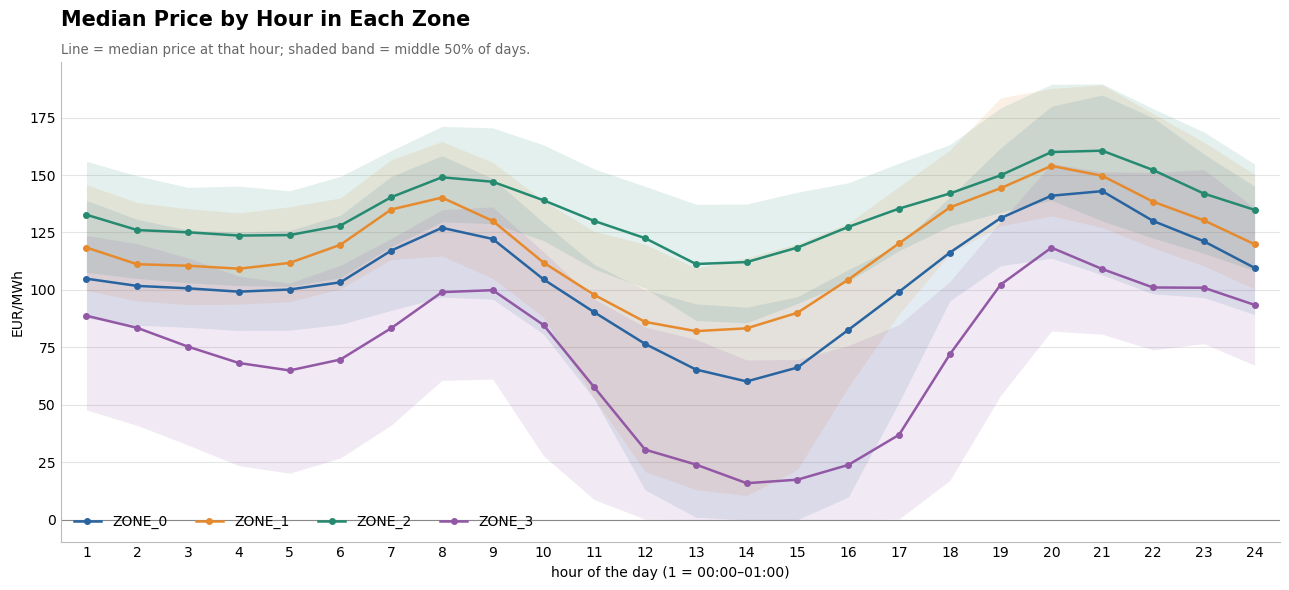

In [14]:
# ---------------------------------------------------------------------------
# Price per hour per zone (1). The typical day of each zone, all zones on one chart
# ---------------------------------------------------------------------------
H = (
    df.groupby(['delivery_date', 'market_id', 'hour_index'], as_index=False)['price_eur_mwh']
    .mean()
    .rename(columns={'price_eur_mwh': 'hourly_price'})
)

ZONES = sorted(H.market_id.unique())      # use exactly the zone names that are in the data
HOURS = np.arange(1, 25)


def tidy(ax):
    ax.grid(axis='y', color='#e5e5e5', lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color('#bbbbbb')
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


q = H.groupby(['market_id', 'hour_index']).hourly_price.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).unstack()

fig, ax = plt.subplots(figsize=(13, 6))
for z, c in zip(ZONES, COLORS):
    qz = q.loc[z]
    ax.fill_between(HOURS, qz[0.25], qz[0.75], color=c, alpha=0.12, lw=0)
    ax.plot(HOURS, qz[0.5], color=c, lw=1.8, marker='o', ms=4, label=z)
ax.axhline(0, color='#888888', lw=0.8)
ax.set(xticks=HOURS, xlim=(0.5, 24.5), xlabel='hour of the day (1 = 00:00–01:00)', ylabel='EUR/MWh')
ax.set_title('Median Price by Hour in Each Zone', fontsize=15, fontweight='bold', loc='left', pad=26)
ax.text(0, 1.01, 'Line = median price at that hour; shaded band = middle 50% of days.',
        transform=ax.transAxes, fontsize=9.5, color='#666666', va='bottom')
tidy(ax)
ax.legend(frameon=False, ncol=4, loc='lower left')
plt.tight_layout()
plt.show()

/var/folders/mf/806w9bj10vzfnz9944vc6wdm0000gn/T/ipykernel_98400/563279467.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


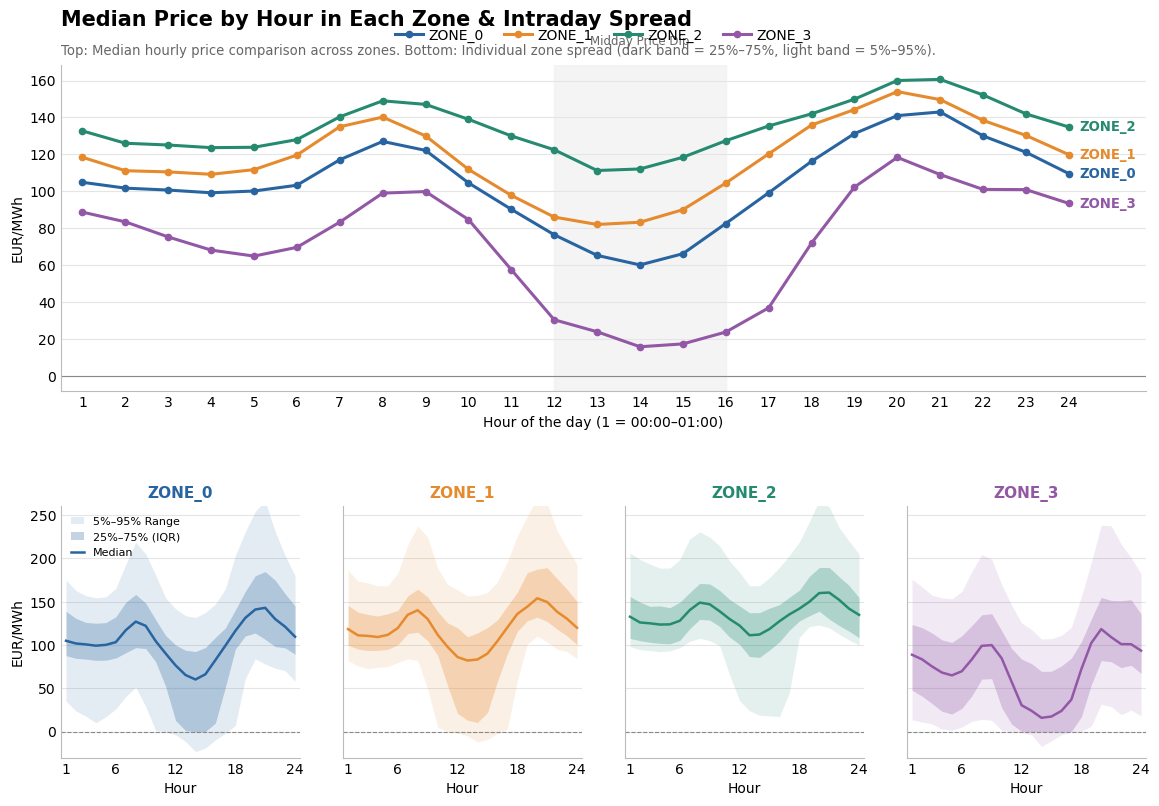

In [15]:
# ---------------------------------------------------------------------------
# Price per hour per zone (1). Combined view: Median comparison + Clean legend
# ---------------------------------------------------------------------------
H = (
    df.groupby(['delivery_date', 'market_id', 'hour_index'], as_index=False)['price_eur_mwh']
    .mean()
    .rename(columns={'price_eur_mwh': 'hourly_price'})
)

ZONES = sorted(H.market_id.unique())
HOURS = np.arange(1, 25)


def tidy(ax):
    ax.grid(axis='y', color='#e5e5e5', lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color('#bbbbbb')
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


q = H.groupby(['market_id', 'hour_index']).hourly_price.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).unstack()

fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 4, height_ratios=[1.3, 1], hspace=0.40, wspace=0.18)

# Top panel: All zone medians together with a clean legend placed outside the plot area
ax_top = fig.add_subplot(gs[0, :])
for z, c in zip(ZONES, COLORS):
    qz = q.loc[z]
    ax_top.plot(HOURS, qz[0.5], color=c, lw=2.2, marker='o', ms=4.5, label=z)
    # Direct text label at hour 24 for instant reading without checking legend
    ax_top.text(24.25, qz[0.5].loc[24], z, color=c, fontsize=9.5, fontweight='bold', va='center')

# Highlight midday price dip region
ax_top.axvspan(12, 16, color='#f2f2f2', alpha=0.8, zorder=0)
ax_top.text(14, 185, 'Midday Price Dip', fontsize=8.5, color='#666666', ha='center', va='top')

ax_top.axhline(0, color='#888888', lw=0.8)
ax_top.set(xticks=HOURS, xlim=(0.5, 25.8), xlabel='Hour of the day (1 = 00:00–01:00)', ylabel='EUR/MWh')
ax_top.set_title('Median Price by Hour in Each Zone & Intraday Spread', fontsize=15, fontweight='bold', loc='left', pad=28)
ax_top.text(
    0, 1.02,
    'Top: Median hourly price comparison across zones. Bottom: Individual zone spread (dark band = 25%–75%, light band = 5%–95%).',
    transform=ax_top.transAxes, fontsize=9.5, color='#666666', va='bottom'
)
tidy(ax_top)

# Optimized legend placed horizontally at the top center, completely out of the way of data lines
ax_top.legend(
    frameon=False, 
    ncol=4, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 1.15), 
    handletextpad=0.4, 
    columnspacing=1.5
)

# Bottom panels: Small multiples per zone showing 5%-95% and 25%-75% bands cleanly
ax_first = None
for i, (z, c) in enumerate(zip(ZONES, COLORS)):
    ax_sub = fig.add_subplot(gs[1, i], sharey=ax_first)
    if i == 0:
        ax_first = ax_sub

    qz = q.loc[z]
    ax_sub.fill_between(HOURS, qz[0.05], qz[0.95], color=c, alpha=0.12, lw=0, label='5%–95% Range')
    ax_sub.fill_between(HOURS, qz[0.25], qz[0.75], color=c, alpha=0.28, lw=0, label='25%–75% (IQR)')
    ax_sub.plot(HOURS, qz[0.5], color=c, lw=1.8, label='Median')
    ax_sub.axhline(0, color='#888888', lw=0.8, ls='--')
    ax_sub.set_title(z, fontsize=11, fontweight='bold', color=c)
    ax_sub.set(xticks=[1, 6, 12, 18, 24], xlim=(0.5, 24.5), ylim=(-30, 260), xlabel='Hour')
    
    if i == 0:
        ax_sub.set_ylabel('EUR/MWh')
        # Place a concise legend only on the first subplot to avoid cluttering all panels
        ax_sub.legend(frameon=False, loc='upper left', fontsize=8, handlelength=1.2)
    else:
        ax_sub.tick_params(labelleft=False)
        
    tidy(ax_sub)

plt.tight_layout()
plt.show()

### **Top chart:** How expensive was each day?
Each bar is the average price of one day. The faint vertical line behind it shows the gap between that day's cheapest and most expensive hour, so you can see both how pricey the day was and how much it swung.

### **Bottom chart:** How much did the price move inside the hours?
Each bar shows how far, on average, the 15-minute prices moved away from their hourly price that day, which is the exact error a flat guess would make. The coloured line shows the day's price range, so you can see that days with big swings across hours also tend to move more inside each hour.

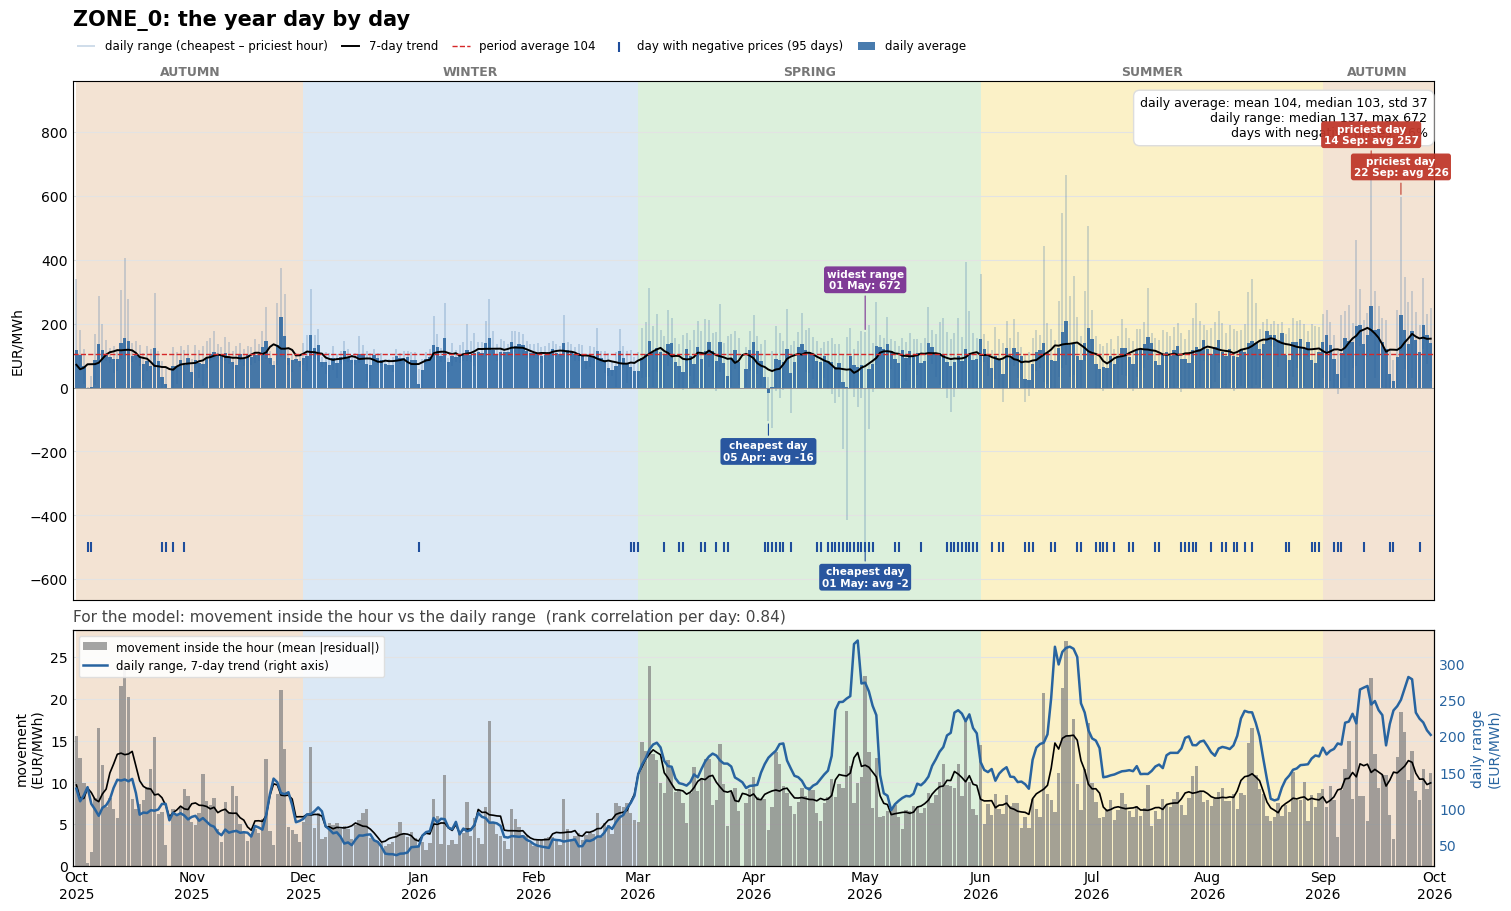

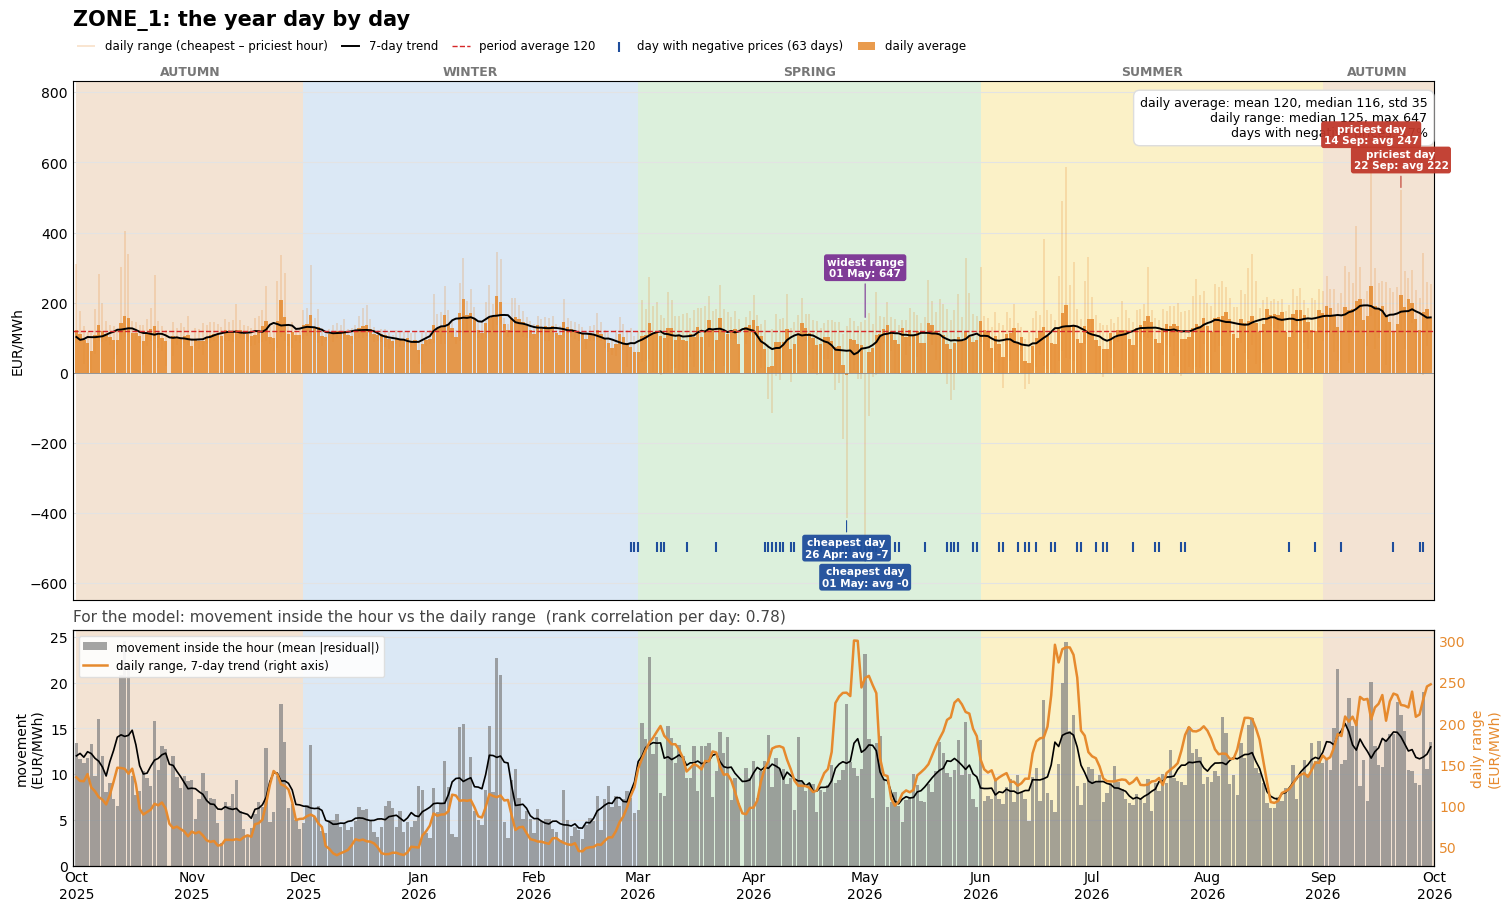

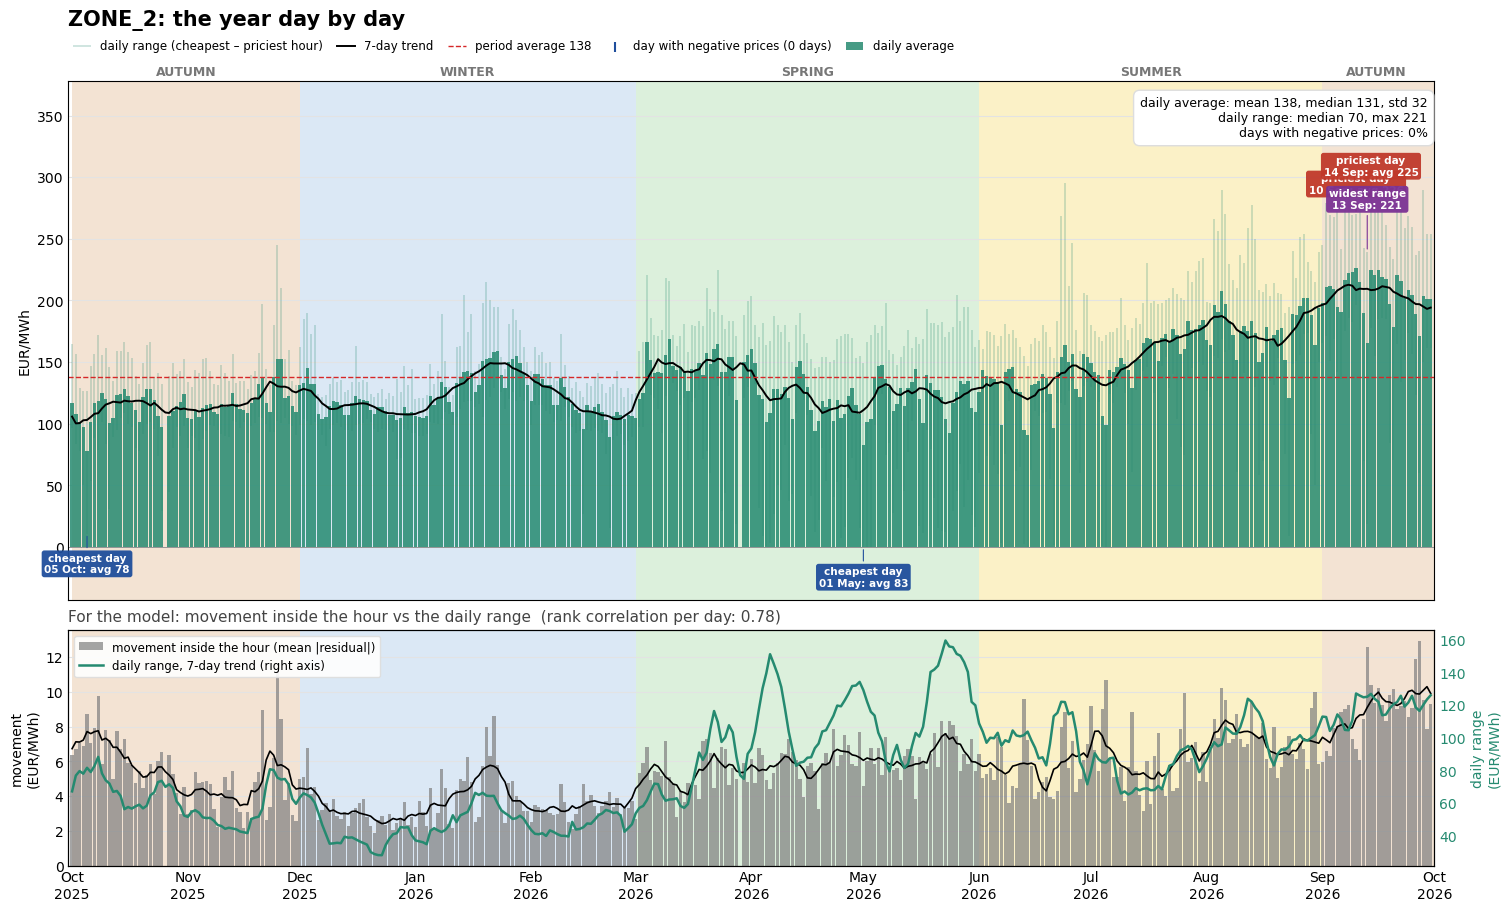

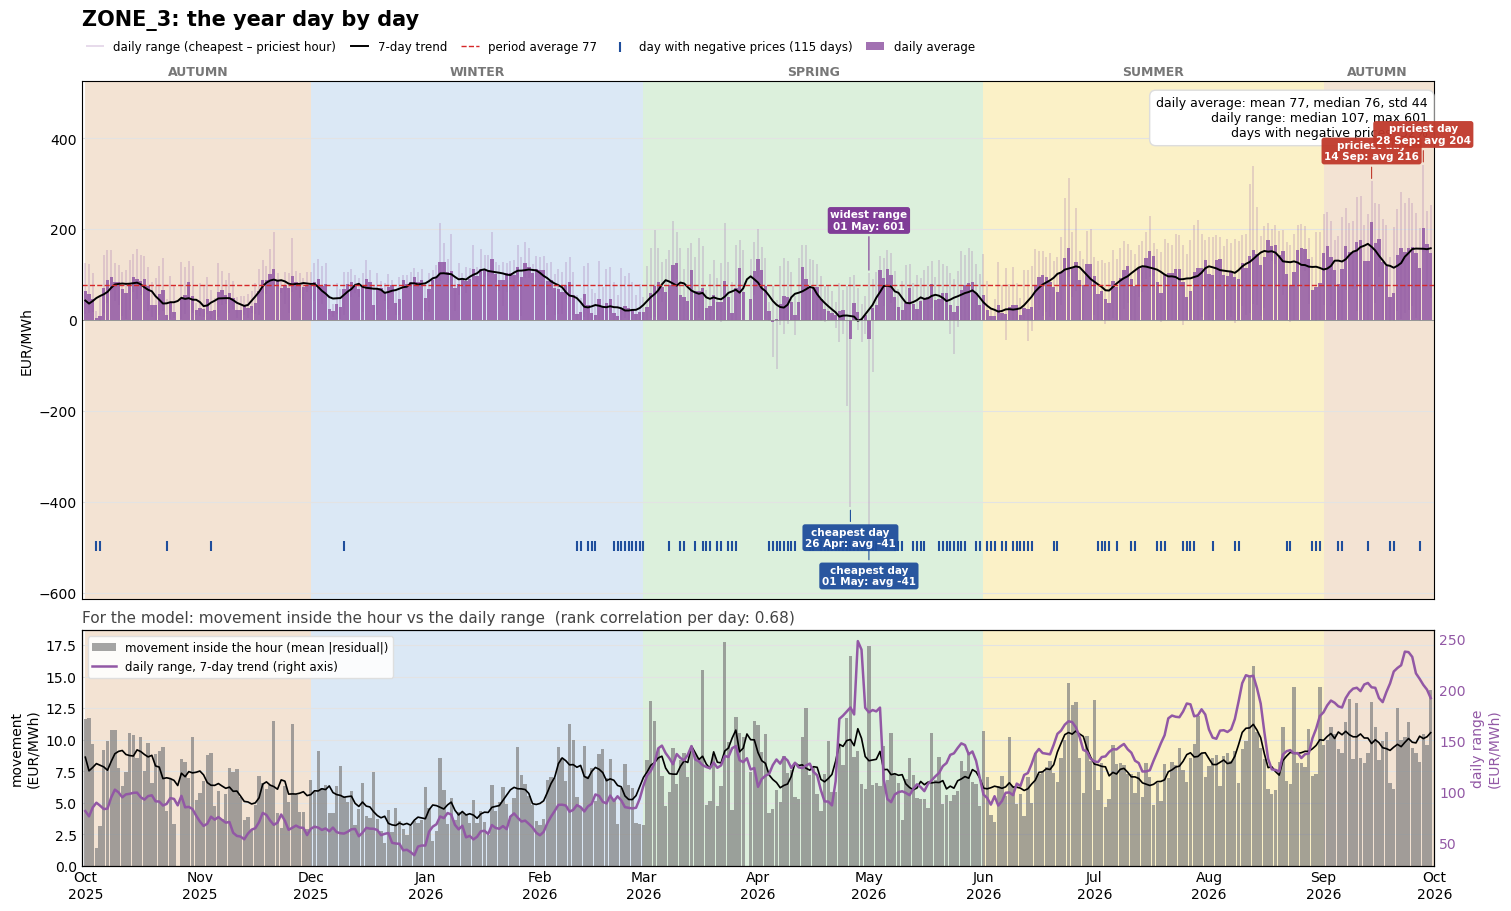

Summary per zone (daily level):


,mean daily avg,median daily avg,std daily avg,median daily range,% days with negatives,"corr(range, movement)","corr(level, movement)"
market_id,,,,,,,
ZONE_0,104.42,102.95,36.91,136.73,26.17,0.84,0.38
ZONE_1,119.81,116.44,35.46,125.07,17.36,0.78,0.28
ZONE_2,138.31,131.17,31.58,69.92,0.00,0.78,0.45
ZONE_3,76.75,76.29,43.59,106.99,31.68,0.68,0.36


In [16]:
# ---------------------------------------------------------------------------
# The year day by day, one figure per zone. Uses only df.
#   top    = daily average price, daily low–high range, 7-day trend, negative-price days, top spike days
#   bottom = what matters for the model: movement inside the hour vs the day's spread
# ---------------------------------------------------------------------------
import matplotlib.dates as mdates

# ---- Build the hour-level numbers straight from df -------------------------------------------
HOURKEY = ['delivery_date', 'market_id', 'hour_index']
dd = df[['delivery_date', 'market_id', 'hour_index', 'price_eur_mwh']].copy()
dd['delivery_date'] = pd.to_datetime(dd['delivery_date'])
dd['hourly_price'] = dd.groupby(HOURKEY)['price_eur_mwh'].transform('mean')
dd['abs_res'] = (dd['price_eur_mwh'] - dd['hourly_price']).abs()     # movement inside the hour
dd['n_neg'] = (dd['price_eur_mwh'] < 0).astype(int)                 # negative quarter-hours
hours_df = (dd.groupby(HOURKEY)
              .agg(hourly_price=('hourly_price', 'first'), abs_res=('abs_res', 'mean'), n_neg=('n_neg', 'sum'))
              .reset_index())
ZONES = sorted(hours_df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']

daily_stats_rows = []

# Background colour per meteorological season
SEASON_BG = {'autumn': '#f3e3d3', 'winter': '#dbe8f5', 'spring': '#dcf0dc', 'summer': '#fbf1c7'}
SEASON_OF = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring',
             6: 'summer', 7: 'summer', 8: 'summer', 9: 'autumn', 10: 'autumn', 11: 'autumn'}


def season_blocks(index):
    # Consecutive (start, end, season) blocks covering the date range
    months = pd.date_range(index.min().to_period('M').to_timestamp(), index.max(), freq='MS')
    blocks = []
    for m in months:
        s_name = SEASON_OF[m.month]
        end = m + pd.offsets.MonthBegin(1)
        if blocks and blocks[-1][2] == s_name:
            blocks[-1][1] = end
        else:
            blocks.append([m, end, s_name])
    return blocks


def tag(ax, day, y, text, color, dy):
    # Small labelled box with a thin pointer to one day
    ax.annotate(text, (day, y), xytext=(0, dy), textcoords='offset points', ha='center',
                va='bottom' if dy > 0 else 'top', fontsize=7.5, color='white', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.25', fc=color, ec='none', alpha=0.95),
                arrowprops=dict(arrowstyle='-', color=color, lw=0.8), zorder=7)

for z, c in zip(ZONES, COLORS):
    d = (hours_df[hours_df.market_id == z].groupby('delivery_date')
           .agg(avg=('hourly_price', 'mean'), low=('hourly_price', 'min'), high=('hourly_price', 'max'),
                move=('abs_res', 'mean'), neg_quarters=('n_neg', 'sum'))
           .asfreq('D'))                                       # missing DST days stay as gaps
    d['spread'] = d.high - d.low
    trend = d.avg.rolling(7, min_periods=4, center=True).mean()
    corr = d[['spread', 'move']].dropna().corr(method='spearman').iloc[0, 1]
    neg_days = d.neg_quarters.fillna(0) > 0
    pct_neg_days = 100 * neg_days[d.avg.notna()].mean()      # share of the days that exist (DST gaps excluded)

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(15, 9), sharex=True, layout='constrained',
                                      gridspec_kw={'height_ratios': [2.2, 1]})

    # ---- Top: price ------------------------------------------------------------
    top.vlines(d.index, d.low, d.high, color=c, alpha=0.22, lw=1.4,
               label='daily range (cheapest – priciest hour)')
    top.bar(d.index, d.avg, width=0.9, color=c, alpha=0.85, label='daily average')
    top.plot(trend.index, trend, color='k', lw=1.4, label='7-day trend')
    top.axhline(d.avg.mean(), color='#d62728', lw=1, ls='--', label=f'period average {d.avg.mean():.0f}')
    top.axhline(0, color='#888888', lw=0.6)
    # Days with at least one negative quarter: small ticks under the axis
    ymin = min(d.low.min(), 0)
    top.scatter(d.index[neg_days], np.full(neg_days.sum(), ymin), marker='|', s=60, color='#1f4e9c',
                label=f'day with negative prices ({neg_days.sum()} days)')
    # Tag the extreme days
    for day, val in d.avg.nlargest(2).items():                       # most expensive days (average)
        tag(top, day, d.high[day], f'priciest day\n{day:%d %b}: avg {val:.0f}', '#c0392b', 14)
    for day, val in d.avg.nsmallest(2).items():                      # cheapest days (average)
        tag(top, day, d.low[day], f'cheapest day\n{day:%d %b}: avg {val:.0f}', '#1f4e9c', -14)
    day = d.spread.idxmax()                                          # widest swing within one day
    tag(top, day, d.high[day], f'widest range\n{day:%d %b}: {d.spread[day]:.0f}', '#7b3294', 30)
    day = d.low.idxmin()                                             # lowest single hour
    if d.low[day] < 0 and day not in d.avg.nsmallest(2).index:
        tag(top, day, d.low[day], f'lowest hour\n{day:%d %b}: {d.low[day]:.0f}', '#117a65', -30)
    top.set_ylabel('EUR/MWh')
    top.set_title(f'{z}: the year day by day', fontsize=15, fontweight='bold', loc='left', pad=40)

    # Stats box
    stats_txt = (f'daily average: mean {d.avg.mean():.0f}, median {d.avg.median():.0f}, std {d.avg.std():.0f}\n'
                 f'daily range: median {d.spread.median():.0f}, max {d.spread.max():.0f}\n'
                 f'days with negative prices: {pct_neg_days:.0f}%')
    top.text(0.995, 0.97, stats_txt, transform=top.transAxes, ha='right', va='top', fontsize=9,
             bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='#dddddd'))
    # Legend in one row above the chart, so it never hides bars or tags
    top.legend(fontsize=8.5, loc='lower left', bbox_to_anchor=(0, 1.045), ncol=5, frameon=False,
               borderaxespad=0, handlelength=1.5, columnspacing=1.2)
    # Head-room above and below the data so the tags stay inside the chart
    lo_y, hi_y = min(d.low.min(), 0), d.high.max()
    span = hi_y - lo_y
    top.set_ylim(lo_y - 0.14 * span, hi_y + 0.22 * span)

    # ---- Bottom: what the model cares about -----------------------------------------
    bottom.bar(d.index, d.move, width=0.9, color='#7f7f7f', alpha=0.7, label='movement inside the hour (mean |residual|)')
    bottom.plot(d.index, d.move.rolling(7, min_periods=4, center=True).mean(), color='k', lw=1.2)
    bottom.set_ylabel('movement\n(EUR/MWh)')
    ax2 = bottom.twinx()
    ax2.plot(d.index, d.spread.rolling(7, min_periods=4, center=True).mean(), color=c, lw=1.8,
             label='daily range, 7-day trend (right axis)')
    ax2.set_ylabel('daily range\n(EUR/MWh)', color=c)
    ax2.spines['right'].set_visible(True)
    ax2.tick_params(axis='y', colors=c, length=0)
    bottom.set_title(f'For the model: movement inside the hour vs the daily range  (rank correlation per day: {corr:.2f})',
                     fontsize=11, loc='left', color='#444444')
    h1, l1 = bottom.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax2.legend(h1 + h2, l1 + l2, fontsize=8.5, loc='upper left', frameon=True, framealpha=0.9, edgecolor='#dddddd')

    # Axes styling: season background colours, season names, light grid
    for ax in (top, bottom):
        ax.grid(axis='y', color='#e3e3e3', lw=0.8); ax.set_axisbelow(True)
        ax.tick_params(length=0)
        for start, end, s_name in season_blocks(d.index):
            ax.axvspan(start, end, color=SEASON_BG[s_name], zorder=0, lw=0)
    for start, end, s_name in season_blocks(d.index):
        mid = start + (min(end, d.index.max()) - start) / 2
        top.text(mid, 1.005, s_name.upper(), transform=top.get_xaxis_transform(), ha='center', va='bottom',
                 fontsize=9, fontweight='bold', color='#777777')
    bottom.xaxis.set_major_locator(mdates.MonthLocator())
    bottom.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    bottom.set_xlim(d.index.min() - pd.Timedelta(days=1), d.index.max() + pd.Timedelta(days=1))
    plt.show()

    daily_stats_rows.append({
        'market_id': z, 'mean daily avg': d.avg.mean(), 'median daily avg': d.avg.median(),
        'std daily avg': d.avg.std(), 'median daily range': d.spread.median(),
        '% days with negatives': pct_neg_days,
        'corr(range, movement)': corr,
        'corr(level, movement)': d[['avg', 'move']].dropna().corr(method='spearman').iloc[0, 1],
    })

print('Summary per zone (daily level):')
pd.DataFrame(daily_stats_rows).set_index('market_id').round(2)

### 0f. Distribution of prices hour by hour
One box per hour of the day: the box is the middle 50% of days (IQR), the line inside is the median, the whiskers reach the 5th and 95th percentiles. This shows how the *whole distribution*, not just the average, changes through the day.

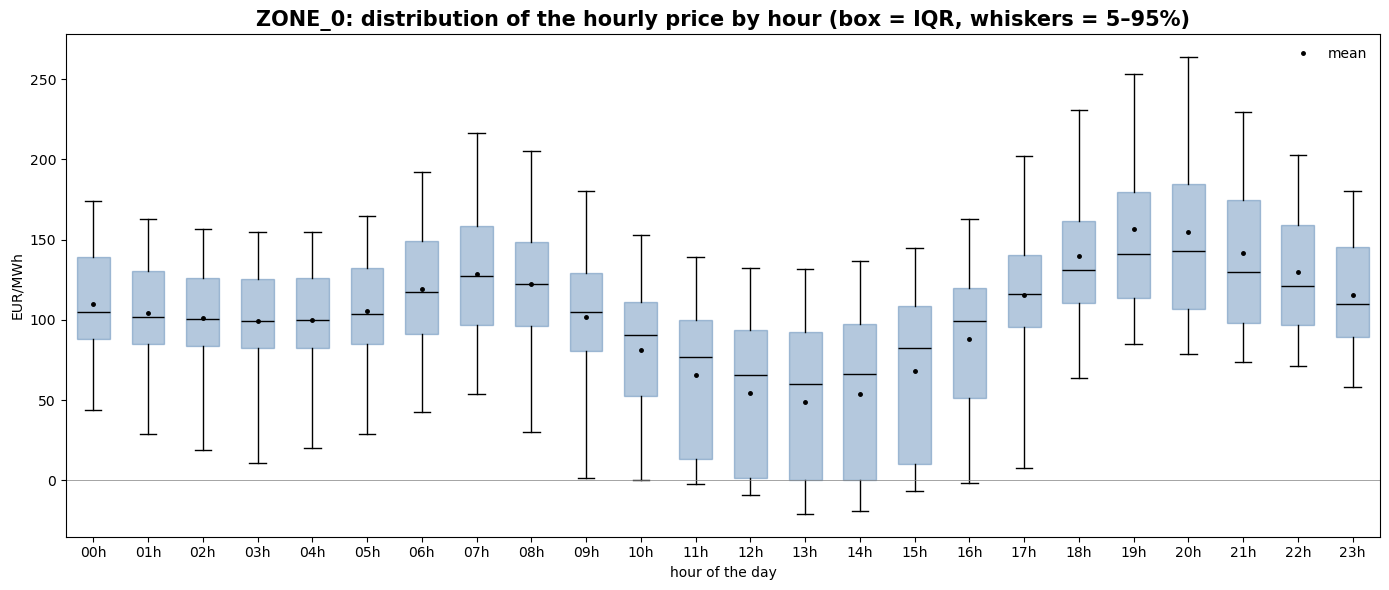

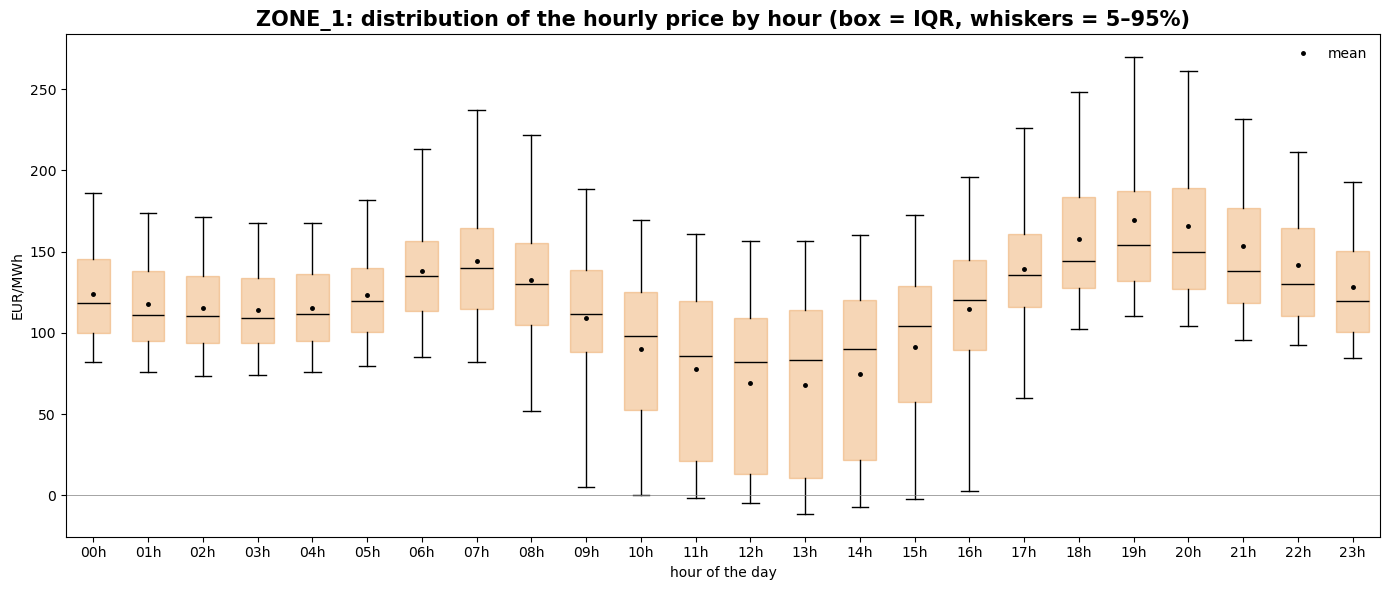

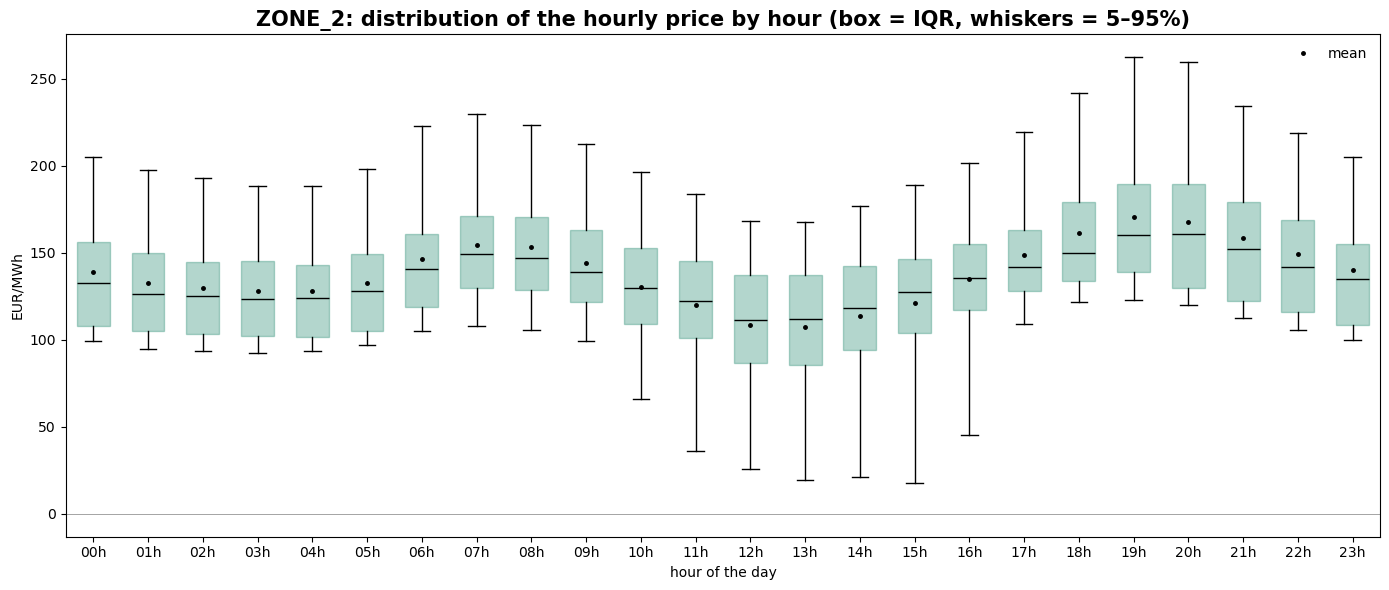

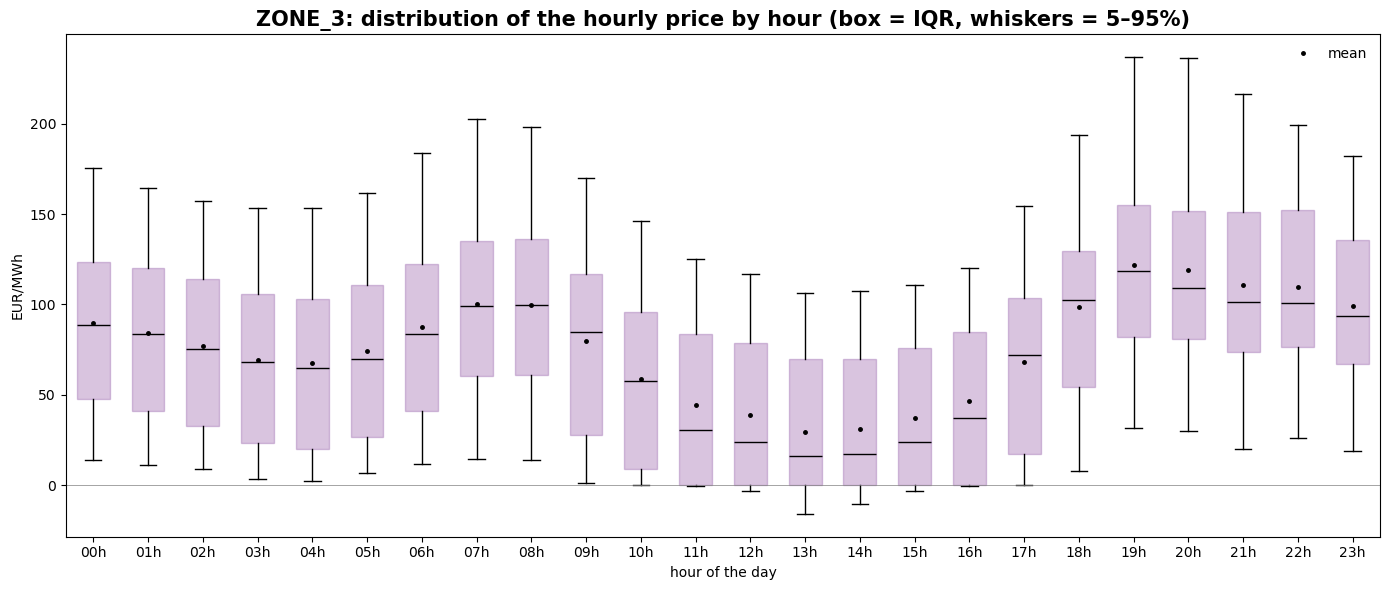

Skewness of the hourly price by hour (> 0: long tail of high prices; < 0: long tail of low prices):


,00h,01h,02h,03h,04h,05h,06h,07h,08h,09h,...,14h,15h,16h,17h,18h,19h,20h,21h,22h,23h
market_id,,,,,,,,,,,,,,,,,,,,,
ZONE_0,-0.3,-0.4,-0.5,-0.6,-0.6,-0.4,0.0,0.4,0.3,-0.1,...,-2.2,-0.5,0.2,0.2,1.2,2.8,2.5,2.6,1.3,0.0
ZONE_1,0.5,0.4,0.4,0.3,0.3,0.4,0.4,0.6,0.4,0.1,...,-2.0,-0.7,-0.1,0.2,1.0,2.4,2.5,2.6,1.5,0.6
ZONE_2,0.7,0.8,0.8,0.7,0.8,0.9,1.0,1.0,0.9,0.3,...,-0.6,-0.7,-0.7,0.4,1.2,1.1,0.9,0.8,0.8,0.7
ZONE_3,0.2,0.2,0.3,0.4,0.4,0.4,0.4,0.3,0.3,0.3,...,-3.1,-0.5,0.4,0.3,0.3,0.6,0.7,0.4,0.3,0.1


In [17]:
# ---------------------------------------------------------------------------
# 0f. Box plots of the hourly price by hour of day (one figure per zone). Uses only df.
# ---------------------------------------------------------------------------
ZONES = sorted(df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']

# One row per day, zone and hour: hourly price = average of its 4 quarters
hp = (df.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].mean()
        .rename('hourly_price').reset_index())

for z, c in zip(ZONES, COLORS):
    hz = hp[hp['market_id'] == z]
    data = [hz.loc[hz['hour_index'] == h, 'hourly_price'].dropna().to_numpy() for h in range(1, 25)]
    fig, ax = plt.subplots(figsize=(14, 6))
    bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
    for box in bp['boxes']:
        box.set(facecolor=c, alpha=0.35, edgecolor=c)
    for med in bp['medians']:
        med.set(color='k')
    ax.plot(range(1, 25), [d.mean() for d in data], 'k.', ms=5, label='mean')   # mean vs median
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_xticks(range(1, 25), [f'{h:02d}h' for h in range(24)])           # hour_index 1 = 00:00–01:00
    ax.set(xlabel='hour of the day', ylabel='EUR/MWh')
    ax.set_title(f'{z}: distribution of the hourly price by hour (box = IQR, whiskers = 5–95%)',
                 fontsize=15, fontweight='bold')
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

# Skewness of the hourly price at each hour: where is the distribution lopsided?
skew_by_hour = hp.groupby(['hour_index', 'market_id'])['hourly_price'].skew().unstack()
skew_by_hour.index = [f'{h - 1:02d}h' for h in skew_by_hour.index]
print('Skewness of the hourly price by hour (> 0: long tail of high prices; < 0: long tail of low prices):')
skew_by_hour.T.round(1)

### Price changes between hours vs inside the hour (all zones)

**Question:** how much does the price move from one hour to the next, and how much is hidden inside each hour?

**Three measures, for every hour of every day:**
- **Hour-to-hour change:** this hour's price − the previous hour's price. We can see this in the hourly data.
- **Boundary jump:** first quarter of this hour − last quarter of the previous hour. It's hidden in the hourly data.
- **Movement inside the hour:** how far the 4 quarters sit from their hourly price. It's hidden too, and it's what we predict.

**How to read it**
- **Box plot:** the change into each hour. Above 0 means the price usually rises into that hour; below 0 means it usually falls.
- **Line chart:** the typical size of each of the three changes by hour, so you can compare visible vs hidden movement.
- **Table:** the same numbers.

**Why it matters:** if the hidden movement is biggest where the hour-to-hour change is biggest, the slope between hours is a good predictor. Hours where the hidden movement is big but the visible change is small need extra features.

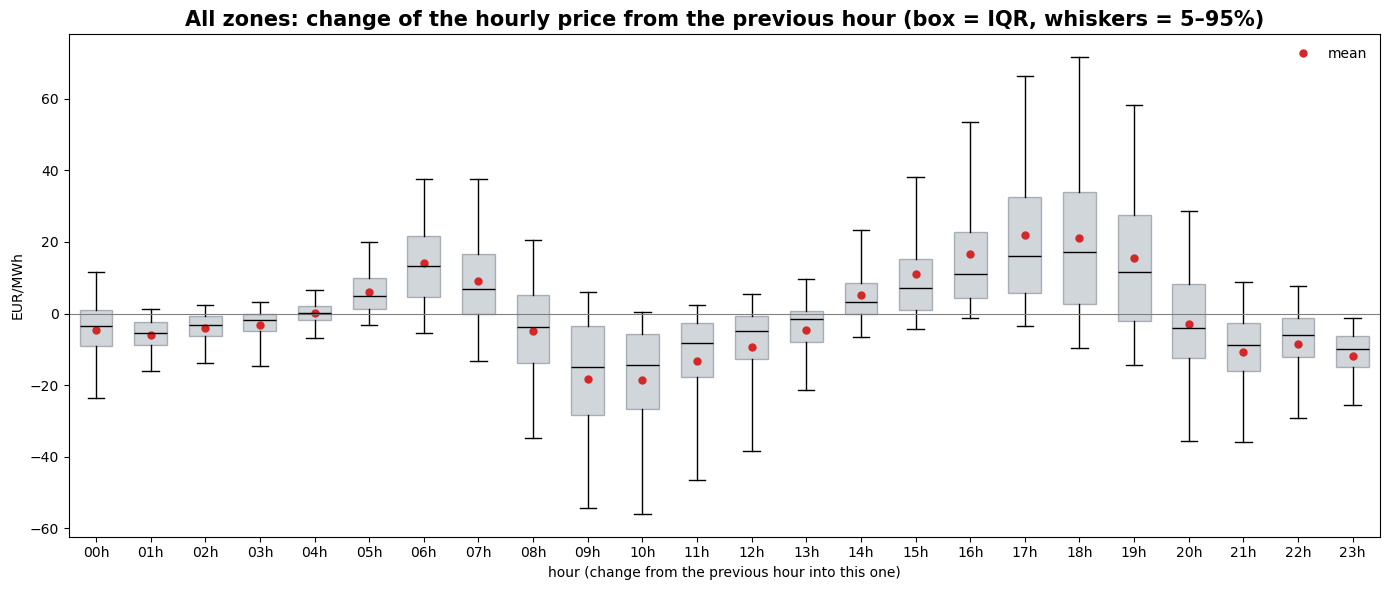

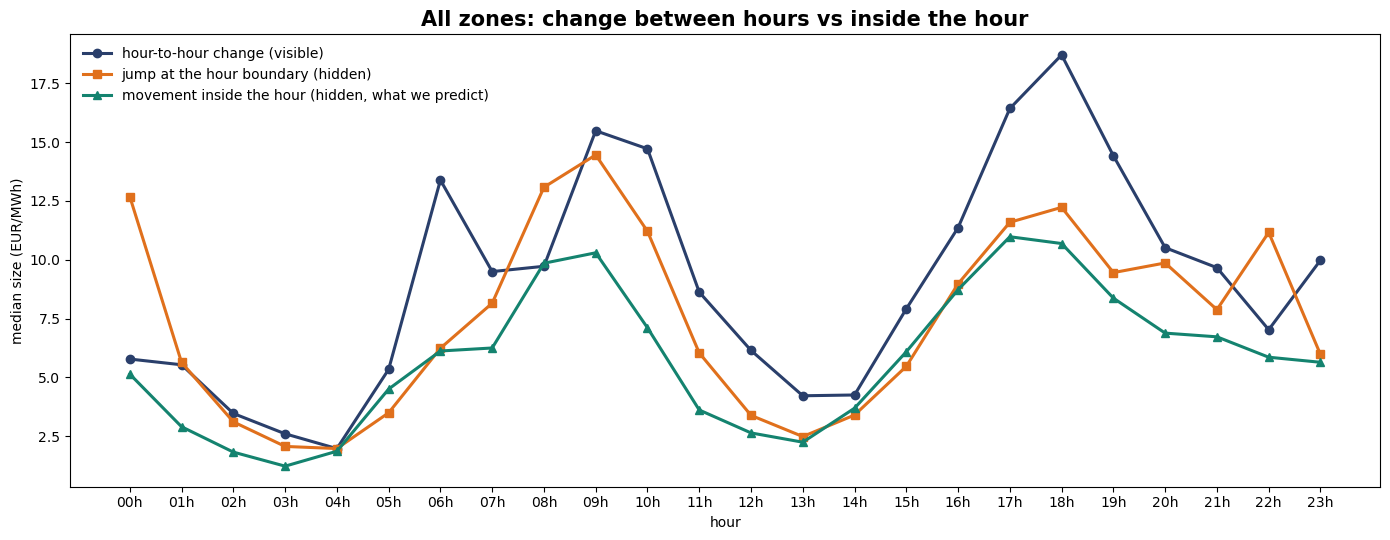

,mean,median,p95
hour-to-hour change,12.8,7.7,42.3
jump at hour boundary,11.0,6.4,36.7
movement inside the hour,7.6,5.1,23.2


In [18]:

K = ['delivery_date', 'market_id', 'hour_index']
hc = df.pivot_table(index=K, columns='quarter_index', values='price_eur_mwh').reset_index()
hc['delivery_date'] = pd.to_datetime(hc['delivery_date'])
hc = hc.sort_values(['market_id', 'delivery_date', 'hour_index'])
hc['hourly'] = hc[[1, 2, 3, 4]].mean(axis=1)
hc['inside'] = hc[[1, 2, 3, 4]].sub(hc['hourly'], axis=0).abs().mean(axis=1)   # movement inside the hour

# Only compare truly consecutive hours (midnight included, DST gaps skipped)
start = hc['delivery_date'] + pd.to_timedelta(hc['hour_index'] - 1, unit='h')
consecutive = (start - start.groupby(hc['market_id']).shift(1)) == pd.Timedelta(hours=1)
g = hc.groupby('market_id')
hc['change'] = (hc['hourly'] - g['hourly'].shift(1)).where(consecutive)          # hour-to-hour change
hc['jump'] = (hc[1] - g[4].shift(1)).where(consecutive)                          # Q4 prev hour → Q1 this hour

hours = range(1, 25)
labels = [f'{h:02d}h' for h in range(24)]

# (a) Box plot: change INTO each hour
data = [hc.loc[hc['hour_index'] == h, 'change'].dropna().to_numpy() for h in hours]
fig, ax = plt.subplots(figsize=(14, 6))
bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
for box in bp['boxes']:
    box.set(facecolor='#9aa5b1', alpha=0.45, edgecolor='#5b6670')
for med in bp['medians']:
    med.set(color='k')
ax.plot(list(hours), [d.mean() for d in data], 'o', color='#d62728', ms=5, label='mean')
ax.axhline(0, color='grey', lw=0.8)
ax.set_xticks(list(hours), labels)
ax.set(xlabel='hour (change from the previous hour into this one)', ylabel='EUR/MWh')
ax.set_title('All zones: change of the hourly price from the previous hour (box = IQR, whiskers = 5–95%)',
             fontsize=15, fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# (b) Typical size of the three changes by hour
size = hc.groupby('hour_index').agg(change=('change', lambda s: s.abs().median()),
                                    jump=('jump', lambda s: s.abs().median()),
                                    inside=('inside', 'median'))
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(size.index, size['change'], color='#2a3f6b', marker='o', lw=2.2, label='hour-to-hour change (visible)')
ax.plot(size.index, size['jump'], color='#e0701c', marker='s', lw=2.2, label='jump at the hour boundary (hidden)')
ax.plot(size.index, size['inside'], color='#14836f', marker='^', lw=2.2, label='movement inside the hour (hidden, what we predict)')
ax.set_xticks(list(hours), labels)
ax.set(xlabel='hour', ylabel='median size (EUR/MWh)')
ax.set_title('All zones: change between hours vs inside the hour', fontsize=15, fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# (c) Summary: typical size of each change
def size_stats(s):
    s = s.dropna().abs()
    return pd.Series({'mean': s.mean(), 'median': s.median(), 'p95': s.quantile(0.95)})

pd.DataFrame({'hour-to-hour change': size_stats(hc['change']),
              'jump at hour boundary': size_stats(hc['jump']),
              'movement inside the hour': size_stats(hc['inside'])}).T.round(1)

## How are the 15-minute prices spread out?

This chart shows how often each price level appears in each zone. Tall bars are prices that happen often, and the long thin tails on the sides are the rare extreme prices: spikes on the right, negative prices on the left.

**How to read it**
- **Red line (mean):** the average price.
- **Black line (median):** the middle price; half of the quarters are cheaper, half are more expensive. If the mean and median are far apart, a few extreme prices are pulling the average.
- **Shaded band:** where the middle 50% of prices fall, which is the "normal" range.
- **Dashed and dotted lines:** where 90% and 98% of prices fall. The further they spread, the more extreme the tails.

**Statistical note:** we test 4 shapes to see which describes the prices best: Gaussian, Student-t, skew-normal and a mix of 2 Gaussians. The best one, with the lowest AIC, is drawn thickest. If a heavy-tailed or two-regime shape wins over the plain Gaussian, extreme prices are common enough that the model should use **MAE / medians**, which are robust to outliers, instead of squared errors.

In [19]:
# 0a. Descriptive statistics of the 15-min prices, per zone

from scipy import stats

def describe(s):
    """Location, spread, tail and extreme statistics of one series."""
    q = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    return pd.Series({
        'count': len(s),
        'mean': s.mean(), 'median': q[0.5],
        'std': s.std(), 'IQR': q[0.75] - q[0.25],                  # spread: classic vs robust
        'MAD': (s - q[0.5]).abs().median(),                        # median absolute deviation (robust)
        'skewness': s.skew(),                                      # 0 = symmetric, > 0 = long right tail
        'excess_kurtosis': s.kurt(),                               # 0 = Gaussian tails, > 0 = heavier tails
        'min': s.min(), 'p1': q[0.01], 'p5': q[0.05], 'p25': q[0.25],
        'p75': q[0.75], 'p95': q[0.95], 'p99': q[0.99], 'max': s.max(),
        'negative_%': 100 * (s < 0).mean(),
    })

price_stats = df.groupby('market_id').price_eur_mwh.apply(describe).unstack()
print('15-min prices (EUR/MWh):')
display(price_stats.T.round(2))

15-min prices (EUR/MWh):


market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
count,34848.00,34848.00,34848.00,34848.00
mean,104.42,119.81,138.31,76.75
median,104.13,120.32,134.50,78.00
std,63.07,60.60,42.64,61.10
IQR,57.85,55.72,47.50,91.15
MAD,29.43,27.68,23.67,45.59
skewness,0.41,-0.13,0.22,0.05
excess_kurtosis,9.91,8.40,1.48,3.20
min,-499.99,-498.65,0.00,-498.65
p1,-15.00,-9.48,12.75,-11.51


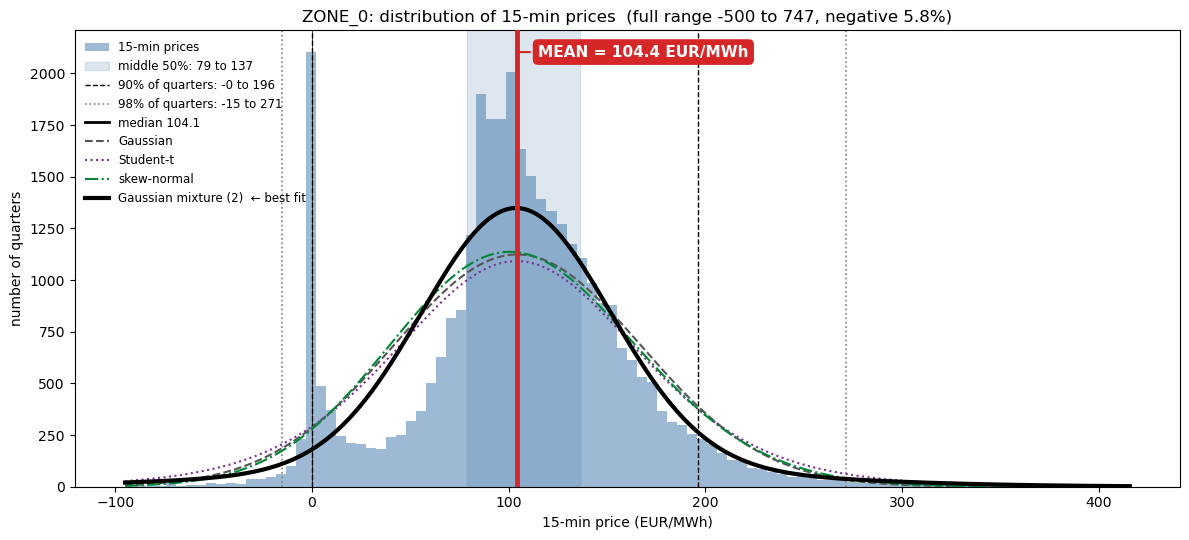

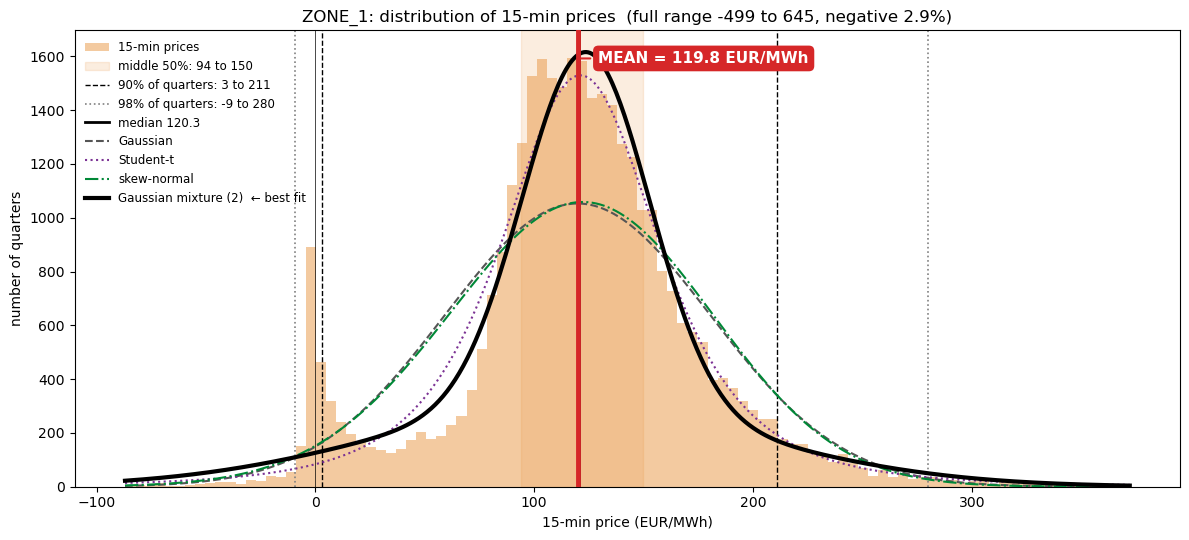

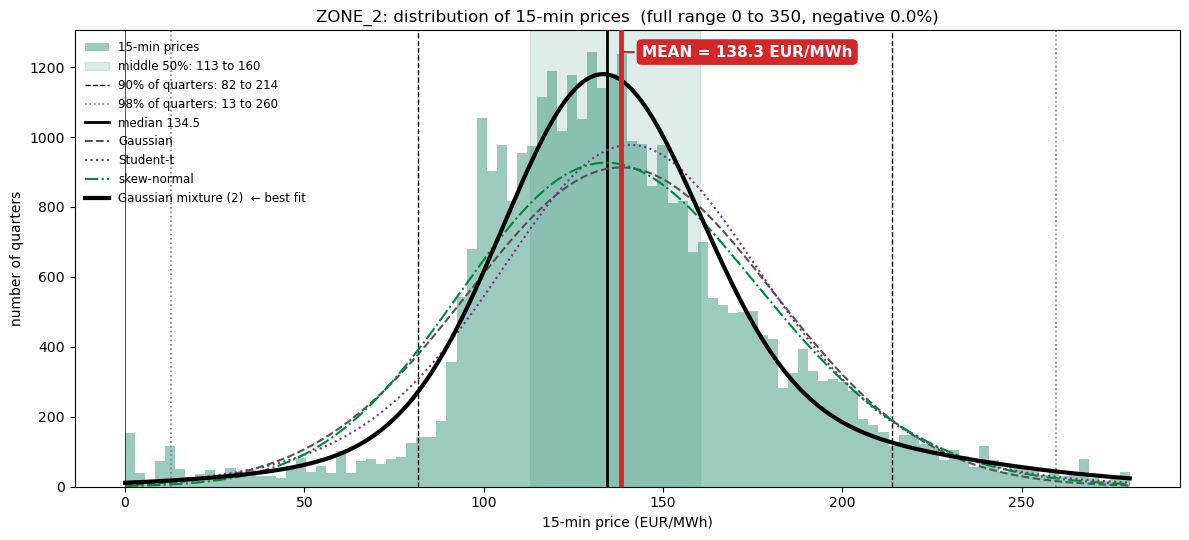

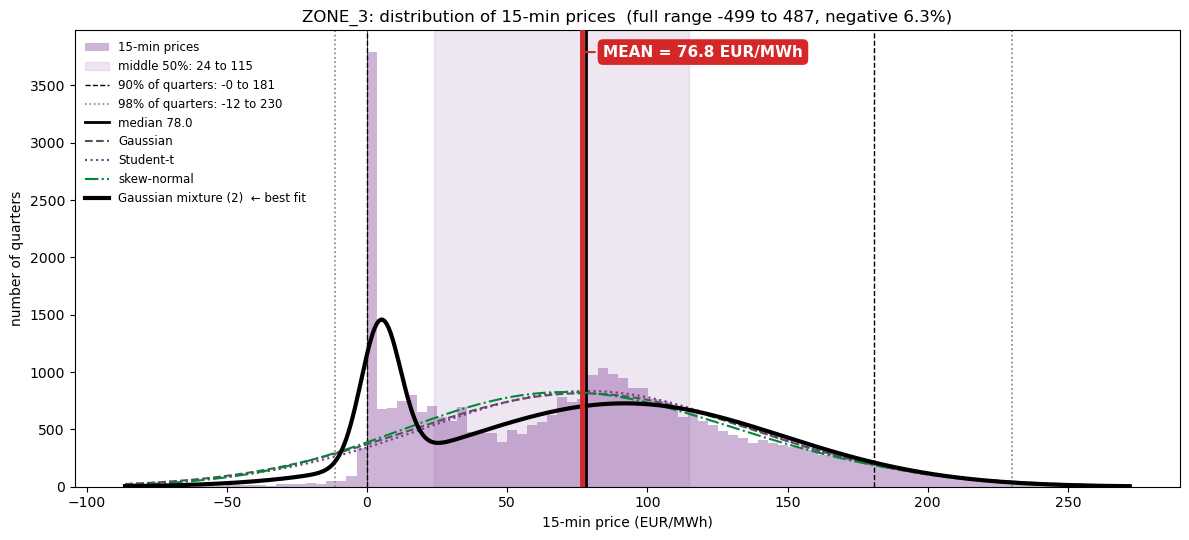

Fit quality per zone (AIC, lower = better):


market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
distribution,,,,
Gaussian,387734.0,384953.0,360457.0,385526.0
Gaussian mixture (2),383094.0,378320.0,357069.0,377990.0
Student-t,384747.0,378511.0,359019.0,384874.0
skew-normal,387296.0,384809.0,360100.0,385304.0


In [20]:
# ---------------------------------------------------------------------------
# 0a (graph 1). Distribution of the 15-min prices, one figure per zone,
#               with the mean highlighted and the best-fitting distributions overlaid. Uses only df.
# ---------------------------------------------------------------------------
from scipy import stats
from sklearn.mixture import GaussianMixture

ZONES = sorted(df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']
FIT_STYLES = {'Gaussian': ('#555555', '--'), 'Student-t': ('#7b3294', ':'),
              'skew-normal': ('#008837', '-.'), 'Gaussian mixture (2)': ('#000000', '-')}


def fit_distributions(x):
    # Fit 4 candidate distributions to x; return {name: (pdf function, AIC)}. Lower AIC = better fit.
    fits = {}
    for name, dist in [('Gaussian', stats.norm), ('Student-t', stats.t), ('skew-normal', stats.skewnorm)]:
        params = dist.fit(x)
        aic = 2 * len(params) - 2 * dist.logpdf(x, *params).sum()
        fits[name] = (lambda g, d=dist, prm=params: d.pdf(g, *prm), aic)
    gm = GaussianMixture(2, random_state=0).fit(x.reshape(-1, 1))           # two price regimes
    w, mu, sd = gm.weights_, gm.means_.ravel(), np.sqrt(gm.covariances_.ravel())
    fits['Gaussian mixture (2)'] = (lambda g, w=w, mu=mu, sd=sd: sum(w[k] * stats.norm.pdf(g, mu[k], sd[k]) for k in range(2)),
                                    gm.aic(x.reshape(-1, 1)))
    return fits


fit_summary = []
for z, c in zip(ZONES, COLORS):
    s = df.loc[df['market_id'] == z, 'price_eur_mwh'].dropna()
    x = s.to_numpy()
    p = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    lo, hi = s.quantile([0.002, 0.998])                       # hide only the 0.4% most extreme for readability
    mean = s.mean()

    fig, ax = plt.subplots(figsize=(12, 5.5))
    counts, edges, _ = ax.hist(s[(s >= lo) & (s <= hi)], bins=100, color=c, alpha=0.45, label='15-min prices')
    bin_w = edges[1] - edges[0]

    # Percentile ranges and median
    ax.axvspan(p[0.25], p[0.75], color=c, alpha=0.15, label=f'middle 50%: {p[0.25]:.0f} to {p[0.75]:.0f}')
    ax.axvline(p[0.05], color='k', ls='--', lw=1, label=f'90% of quarters: {p[0.05]:.0f} to {p[0.95]:.0f}')
    ax.axvline(p[0.95], color='k', ls='--', lw=1)
    ax.axvline(p[0.01], color='grey', ls=':', lw=1.2, label=f'98% of quarters: {p[0.01]:.0f} to {p[0.99]:.0f}')
    ax.axvline(p[0.99], color='grey', ls=':', lw=1.2)
    ax.axvline(p[0.5], color='k', lw=2, label=f'median {p[0.5]:.1f}')
    ax.axvline(0, color='k', lw=0.5)

    # Fitted distributions, scaled from density to "number of quarters"; best AIC drawn thickest
    fits = fit_distributions(x)
    best = min(fits, key=lambda k: fits[k][1])
    grid = np.linspace(lo, hi, 500)
    for name, (pdf, aic) in fits.items():
        col, ls = FIT_STYLES[name]
        ax.plot(grid, pdf(grid) * len(x) * bin_w, color=col, ls=ls, lw=3 if name == best else 1.5,
                label=f'{name}{"  ← best fit" if name == best else ""}')
        fit_summary.append({'market_id': z, 'distribution': name, 'AIC': aic, 'best': name == best})

    # The mean: thick red line plus a labelled box at the top
    ax.axvline(mean, color='#d62728', lw=3.5, zorder=5)
    ax.annotate(f'MEAN = {mean:.1f} EUR/MWh', xy=(mean, counts.max()), xytext=(15, 0),
                textcoords='offset points', color='white', fontsize=11, fontweight='bold', va='center',
                bbox=dict(boxstyle='round,pad=0.35', fc='#d62728', ec='none'), zorder=6,
                arrowprops=dict(arrowstyle='-', color='#d62728', lw=1.5))

    ax.set(title=f'{z}: distribution of 15-min prices  '
                 f'(full range {s.min():.0f} to {s.max():.0f}, negative {100 * (s < 0).mean():.1f}%)',
           xlabel='15-min price (EUR/MWh)', ylabel='number of quarters')
    ax.legend(frameon=False, fontsize=8.5, loc='upper left')
    plt.tight_layout(); plt.show()

# Which distribution fits best? (AIC: lower = better; compare within a zone only)
print('Fit quality per zone (AIC, lower = better):')
pd.DataFrame(fit_summary).pivot(index='distribution', columns='market_id', values='AIC').round(0)

## 0b. The residuals: what we actually have to predict

We already know each hourly price, so the real task is the **residual**: how far each 15-minute price sits above or below its hour's average (residual = 15-min price − hourly price). The 4 residuals of an hour always add up to 0, so their mean is 0 by definition. What matters is how **big** they are and how often they get **extreme**.

**How to read the first table**
- **std and mean |residual|:** the typical size of a move inside the hour. Mean |residual| is the error you'd make with a flat guess.
- **Percentiles (1% … 99%):** how far the moves go on normal and on rare quarters.
- **Kurtosis:** it's 0 for a normal bell curve. A high value means most quarters are close to the hourly price, with occasional very large jumps (heavy tails).

**The second table: variance split**
The total variation of the 15-min prices splits exactly into two parts:
- **The hourly level:** how much prices change from hour to hour. We're **given** this part.
- **The residual:** how much prices change inside the hour. This is the part we have to **predict**.

The last column shows what share of the total variation is inside the hour. A small share means most of the price is already known from the hourly prices, and our model only has to fill in that last slice. That's exactly where the score is decided.

In [21]:
# ---------------------------------------------------------------------------
# 0b. The same statistics for the residuals (what we actually predict). Uses only df.
# ---------------------------------------------------------------------------
r = df[['delivery_date', 'market_id', 'hour_index', 'price_eur_mwh']].copy()
r['hourly_price'] = r.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].transform('mean')
r['residual'] = r['price_eur_mwh'] - r['hourly_price']


def residual_stats(x):
    q = x.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    return pd.Series({'count': x.size, 'mean': x.mean(), 'std': x.std(), 'mean |residual|': x.abs().mean(),
                      'min': x.min(), '1%': q[0.01], '5%': q[0.05], '25%': q[0.25], 'median': q[0.5],
                      '75%': q[0.75], '95%': q[0.95], '99%': q[0.99], 'max': x.max(),
                      'skew': x.skew(), 'kurtosis': x.kurt()})


res_stats = r.groupby('market_id')['residual'].apply(residual_stats).unstack()
print('Residuals = 15-min price − hourly price (EUR/MWh):')
display(res_stats.T.round(2))

# How much of the variation is "level" (hour to hour) vs "shape" (inside the hour)?
g = r.groupby('market_id')
share = pd.DataFrame({
    'var_price': g['price_eur_mwh'].var(),
    'var_hourly_level': g['hourly_price'].var(),
    'var_residual': g['residual'].var(),
})
share['% of variance inside the hour'] = 100 * share['var_residual'] / share['var_price']
print('Variance split: total = hourly level + inside-the-hour residual')
share.round(1)

Residuals = 15-min price − hourly price (EUR/MWh):


market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
count,34848.00,34848.00,34848.00,34848.00
mean,0.00,-0.00,0.00,-0.00
std,14.35,16.03,8.64,12.24
mean |residual|,7.91,9.43,5.59,7.38
min,-215.14,-191.48,-79.44,-191.70
1%,-43.34,-49.61,-24.39,-36.97
5%,-19.69,-23.42,-13.53,-18.64
25%,-3.93,-5.01,-3.51,-4.03
median,-0.02,-0.03,0.00,0.00
75%,3.75,4.94,3.34,4.01


Variance split: total = hourly level + inside-the-hour residual


,var_price,var_hourly_level,var_residual,% of variance inside the hour
market_id,,,,
ZONE_0,3977.7,3771.8,206.0,5.2
ZONE_1,3672.7,3415.6,257.1,7.0
ZONE_2,1818.4,1743.8,74.6,4.1
ZONE_3,3733.6,3583.8,149.8,4.0


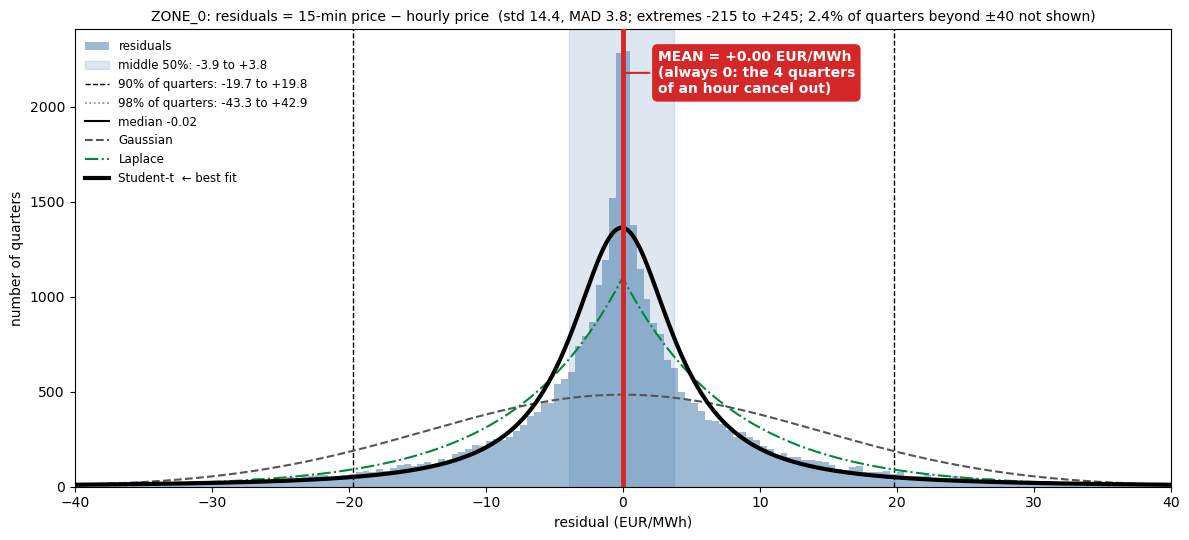

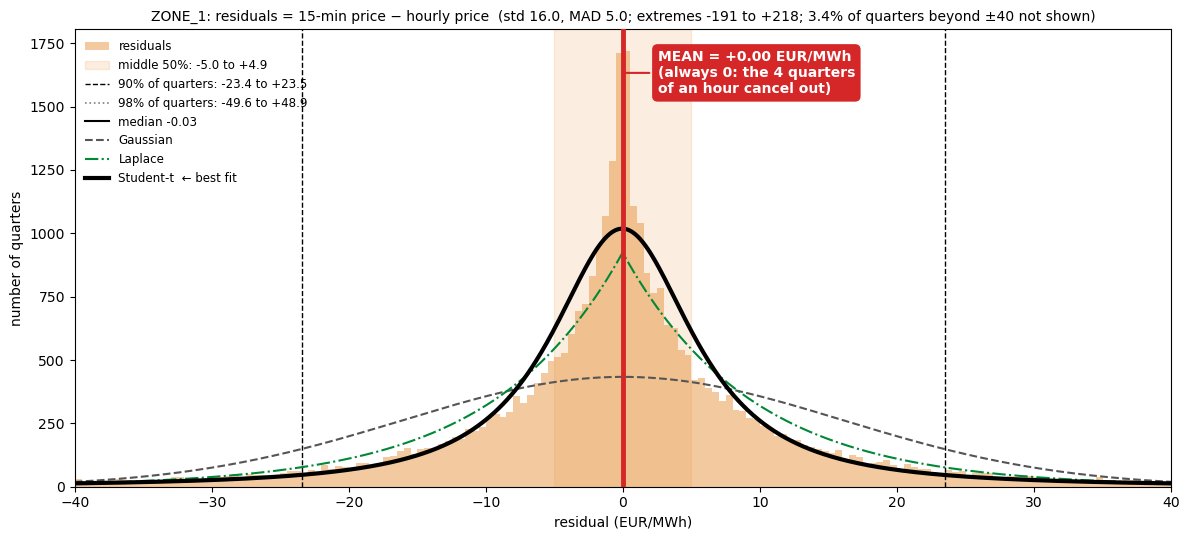

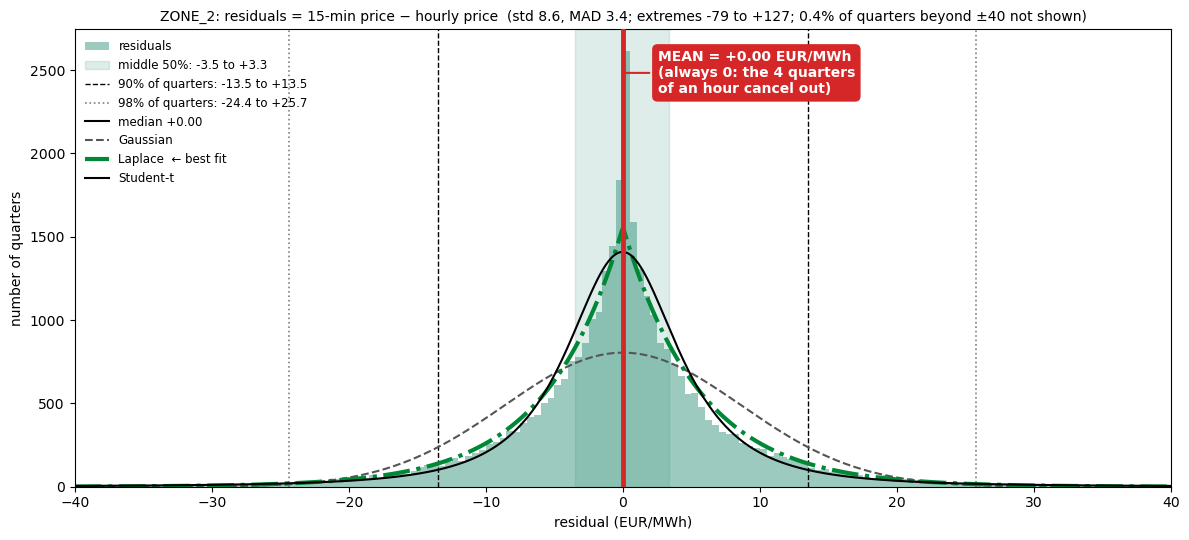

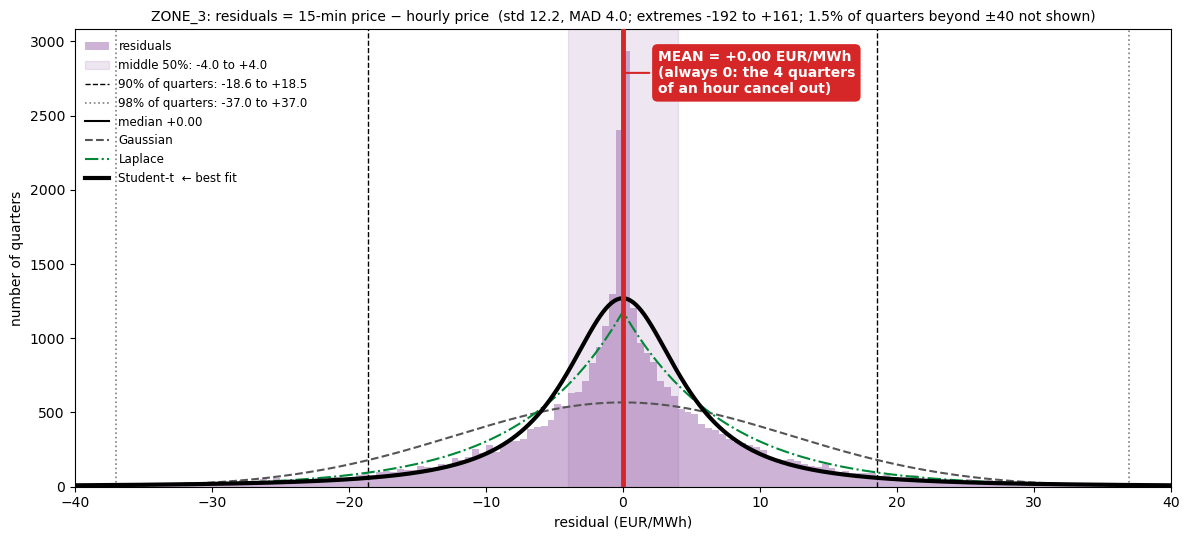

Fit quality per zone (AIC, lower = better):


market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
distribution,,,,
Gaussian,284556.0,292284.0,249188.0,273463.0
Laplace,262188.0,274373.0,237954.0,257311.0
Student-t,258848.0,272690.0,238641.0,257060.0


In [22]:
# ---------------------------------------------------------------------------
# 0b (graph). Distribution of the residuals, one figure per zone,
#             with the mean highlighted and the best-fitting distributions overlaid. Uses only df.
# ---------------------------------------------------------------------------
from scipy import stats

ZONES = sorted(df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']
RES_FIT_STYLES = {'Gaussian': ('#555555', '--'), 'Laplace': ('#008837', '-.'), 'Student-t': ('#000000', '-')}
RES_LIMIT = 40                                               # x-axis shown: ±40 EUR/MWh (covers ≈ 98% of quarters)

# Residual = 15-min price − its hourly average (computed on a copy, df stays unchanged)
rr = df[['delivery_date', 'market_id', 'hour_index', 'price_eur_mwh']].copy()
rr['residual'] = rr['price_eur_mwh'] - rr.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].transform('mean')

res_fit_summary = []
for z, c in zip(ZONES, COLORS):
    s = rr.loc[rr['market_id'] == z, 'residual'].dropna()
    x = s.to_numpy()
    p = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    mean = round(s.mean(), 2) + 0.0                          # + 0.0 avoids printing "-0.00"
    outside = 100 * (s.abs() > RES_LIMIT).mean()

    fig, ax = plt.subplots(figsize=(12, 5.5))
    bins = np.linspace(-RES_LIMIT, RES_LIMIT, 161)            # 0.5 EUR/MWh wide bins
    counts, edges, _ = ax.hist(s[s.abs() <= RES_LIMIT], bins=bins, color=c, alpha=0.45, label='residuals')
    bin_w = edges[1] - edges[0]

    # Percentile ranges and median
    ax.axvspan(p[0.25], p[0.75], color=c, alpha=0.15, label=f'middle 50%: {p[0.25]:.1f} to {p[0.75]:+.1f}')
    ax.axvline(p[0.05], color='k', ls='--', lw=1, label=f'90% of quarters: {p[0.05]:.1f} to {p[0.95]:+.1f}')
    ax.axvline(p[0.95], color='k', ls='--', lw=1)
    ax.axvline(p[0.01], color='grey', ls=':', lw=1.2, label=f'98% of quarters: {p[0.01]:.1f} to {p[0.99]:+.1f}')
    ax.axvline(p[0.99], color='grey', ls=':', lw=1.2)
    ax.axvline(p[0.5], color='k', lw=1.5, label=f'median {p[0.5]:+.2f}')

    # Fitted distributions, scaled from density to "number of quarters"; best AIC drawn thickest
    fits = {}
    for name, dist in [('Gaussian', stats.norm), ('Laplace', stats.laplace), ('Student-t', stats.t)]:
        params = dist.fit(x)
        aic = 2 * len(params) - 2 * dist.logpdf(x, *params).sum()
        fits[name] = (params, dist, aic)
    best = min(fits, key=lambda k: fits[k][2])
    grid = np.linspace(-RES_LIMIT, RES_LIMIT, 800)
    for name, (params, dist, aic) in fits.items():
        col, ls = RES_FIT_STYLES[name]
        ax.plot(grid, dist.pdf(grid, *params) * len(x) * bin_w, color=col, ls=ls,
                lw=3 if name == best else 1.5, label=f'{name}{"  ← best fit" if name == best else ""}')
        res_fit_summary.append({'market_id': z, 'distribution': name, 'AIC': aic, 'best': name == best})

    # The mean: thick red line plus a labelled box at the top
    ax.axvline(mean, color='#d62728', lw=3.5, zorder=5)
    ax.annotate(f'MEAN = {mean:+.2f} EUR/MWh\n(always 0: the 4 quarters\nof an hour cancel out)',
                xy=(mean, counts.max() * 0.95), xytext=(25, 0), textcoords='offset points',
                color='white', fontsize=10, fontweight='bold', va='center',
                bbox=dict(boxstyle='round,pad=0.4', fc='#d62728', ec='none'), zorder=6,
                arrowprops=dict(arrowstyle='-', color='#d62728', lw=1.5))

    ax.set(title=f'{z}: residuals = 15-min price − hourly price  '
                 f'(std {s.std():.1f}, MAD {(s - p[0.5]).abs().median():.1f}; extremes {s.min():.0f} to {s.max():+.0f}; '
                 f'{outside:.1f}% of quarters beyond ±{RES_LIMIT} not shown)',
           xlabel='residual (EUR/MWh)', ylabel='number of quarters', xlim=(-RES_LIMIT, RES_LIMIT))
    ax.title.set_fontsize(10)
    ax.legend(frameon=False, fontsize=8.5, loc='upper left')
    plt.tight_layout(); plt.show()

# Which distribution fits best? (AIC: lower = better; compare within a zone only)
print('Fit quality per zone (AIC, lower = better):')
pd.DataFrame(res_fit_summary).pivot(index='distribution', columns='market_id', values='AIC').round(0)

### 0h. How far apart are the 4 quarters of an hour?

For every hour, we measure how spread out its 4 quarter prices are (the standard deviation of the 4 residuals). A small value means the hourly price is already a good guess for all 4 quarters. A large value means the quarters differ a lot and the hourly view hides real money.

**How to read it:** each line shows how common each spread is in one zone. The legend gives the **median** (a normal hour) and the **90th percentile** (only 1 hour in 10 is wilder than this).

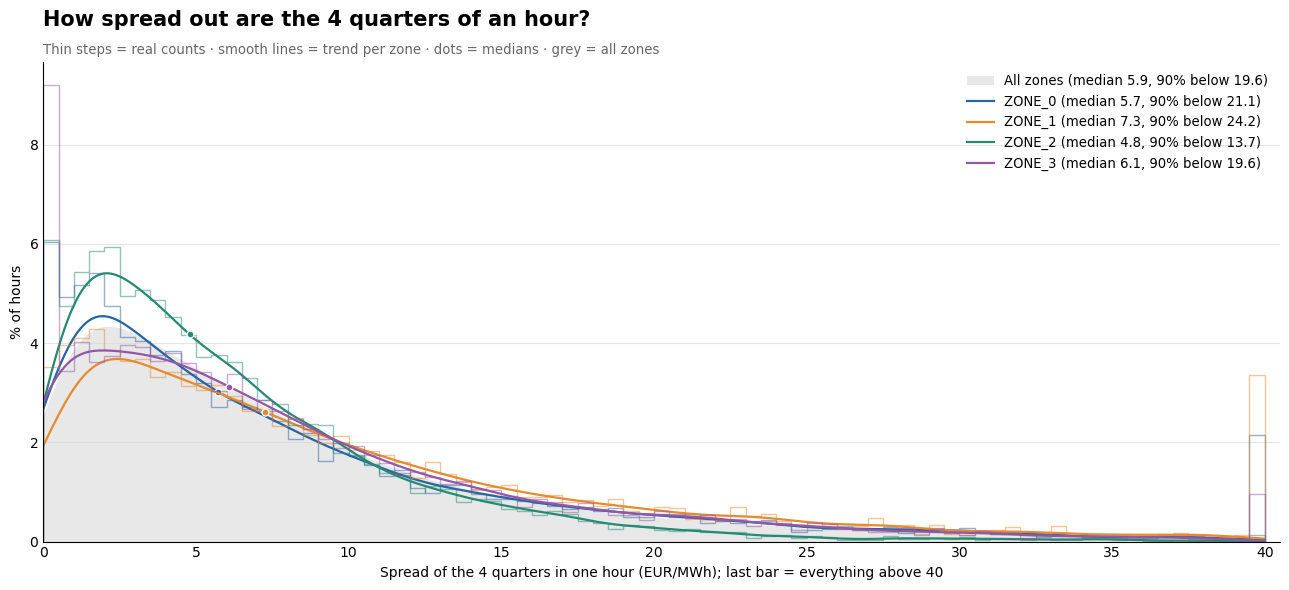

In [23]:

from scipy.stats import gaussian_kde

ZONES = sorted(df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']

# Std of the 4 quarter prices of each hour (= std of its 4 residuals)
ws = (df.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].std(ddof=0)
        .rename('within_std').reset_index())

BAR_W, MAX_X = 0.5, 40
grid = np.linspace(0, MAX_X, 400)
bins = np.arange(0, MAX_X + BAR_W, BAR_W)

def smooth_line(s):
    # Smoothed distribution, in % of hours per 0.5 EUR/MWh
    kde = gaussian_kde(s[s <= MAX_X], bw_method=0.15)
    return kde(grid) * (s <= MAX_X).mean() * BAR_W * 100

fig, ax = plt.subplots(figsize=(13, 6))
s_all = ws['within_std'].dropna().to_numpy()
ax.fill_between(grid, smooth_line(s_all), color='#d9d9d9', alpha=0.6, lw=0,
                label=f'All zones (median {np.median(s_all):.1f}, 90% below {np.percentile(s_all, 90):.1f})')
for z, c in zip(ZONES, COLORS):
    s = ws.loc[ws['market_id'] == z, 'within_std'].dropna().to_numpy()
    ax.hist(np.clip(s, None, MAX_X), bins=bins, histtype='step', lw=0.9, alpha=0.5, color=c,
            weights=np.full(len(s), 100 / len(s)))
    y = smooth_line(s)
    m = np.median(s)
    ax.plot(grid, y, color=c, lw=1.6, label=f'{z} (median {m:.1f}, 90% below {np.percentile(s, 90):.1f})')
    ax.plot(m, np.interp(m, grid, y), 'o', color=c, ms=5, mec='white', mew=1)

ax.set(xlabel=f'Spread of the 4 quarters in one hour (EUR/MWh); last bar = everything above {MAX_X}',
       ylabel='% of hours', xlim=(0, MAX_X + 0.5), ylim=(0, None))
ax.set_title('How spread out are the 4 quarters of an hour?', fontsize=15, fontweight='bold', loc='left', pad=26)
ax.text(0, 1.01, 'Thin steps = real counts · smooth lines = trend per zone · dots = medians · grey = all zones',
        transform=ax.transAxes, fontsize=9.5, color='#666666', va='bottom')
ax.grid(axis='y', color='#e5e5e5', lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9.5)
plt.tight_layout(); plt.show()

**Result**
- **A normal hour is fairly calm:** across all zones, the 4 quarters typically sit about **6 EUR/MWh** from their hourly price (median 5.9).
- **But there's a long tail:** 1 hour in 10 has a spread above about **20 EUR/MWh**, and roughly 1–3% of hours go beyond 40, which is the spike at the right edge.
- **Some hours don't move at all:** the tall first bar, especially in ZONE_3, is hours where all 4 quarters have the same price.
- **The zones differ:**
  - **ZONE_2 is the calmest:** median 4.8, 90% of hours below 13.7.
  - **ZONE_1 is the wildest:** median 7.3, 90% of hours below 24.2.

**Interpretation:** the hourly price is a good guess for most hours, but a small share of very volatile hours carries most of the error. That's why we score with MAE, so a few wild hours don't dominate, and why each zone needs its own settings. ZONE_1 will be the hardest to predict and ZONE_2 the easiest.

### 1b. Which shape best describes the spread inside the hour?
We test 4 standard shapes for a value that is always positive and has a long right tail: Exponential, Gamma, Log-normal and Weibull. The best one, with the lowest AIC, is drawn thickest.
Knowing the shape tells us how often extreme hours happen, so we can set realistic error expectations and choose a robust loss for the model.

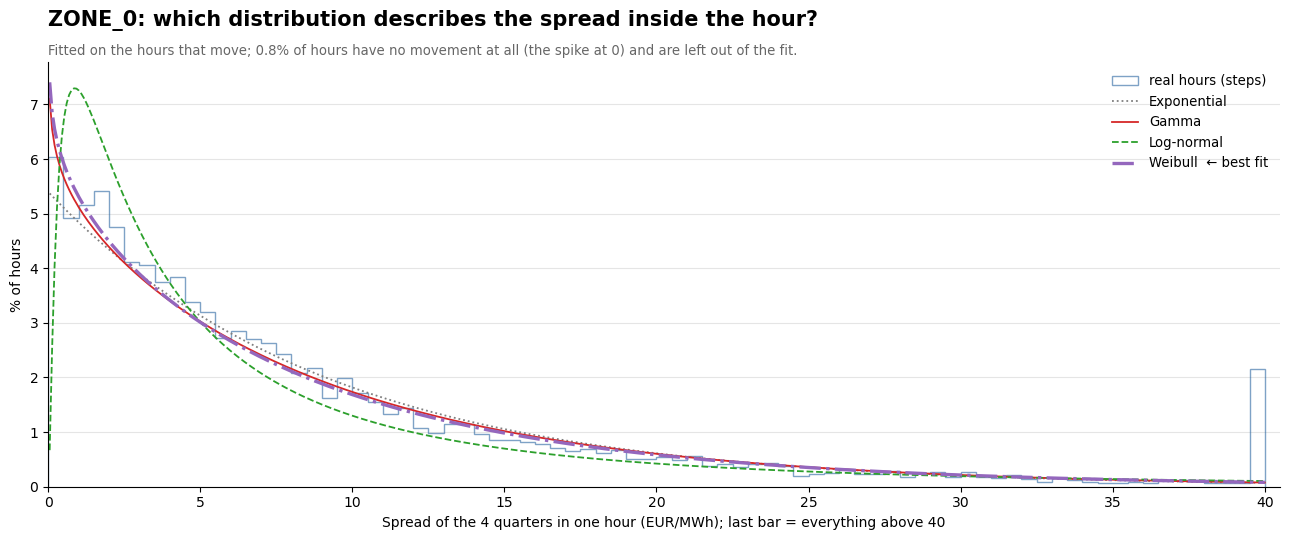

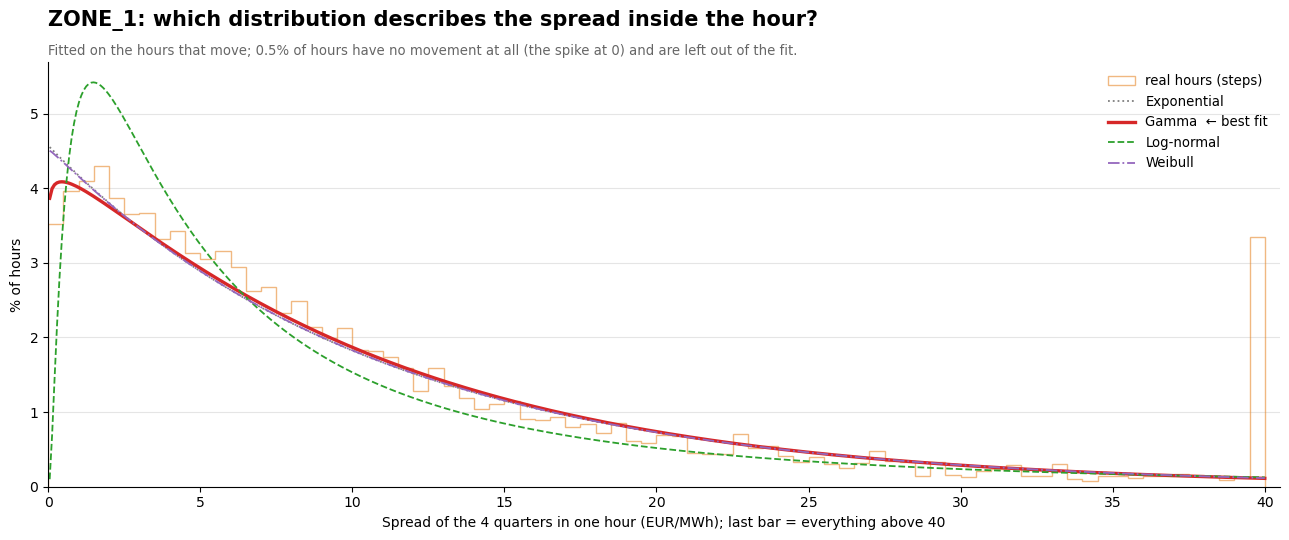

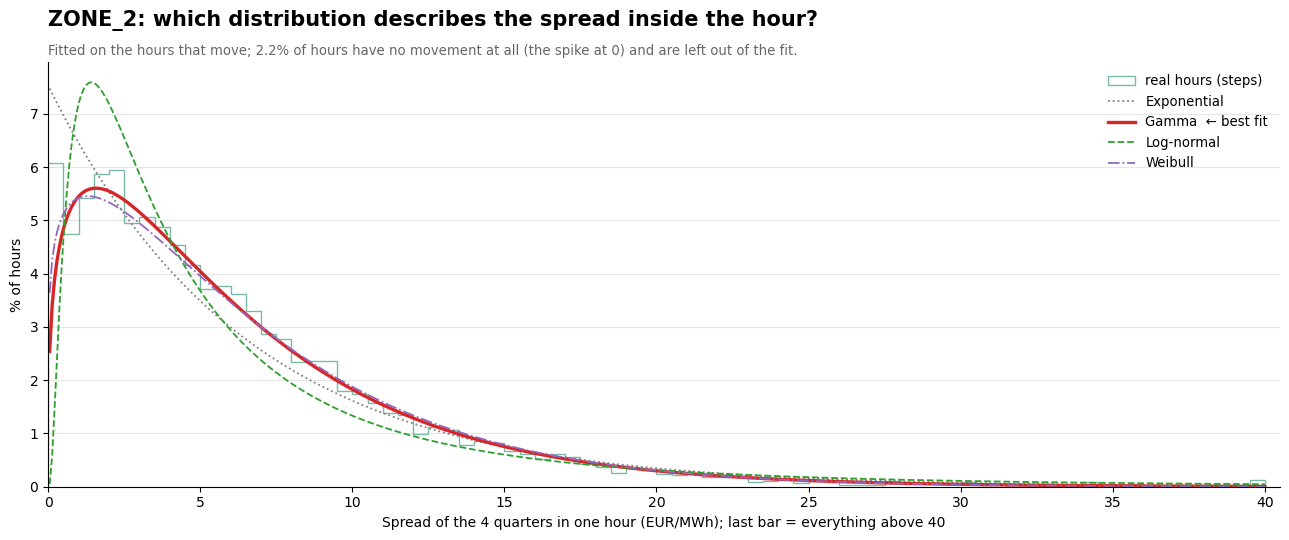

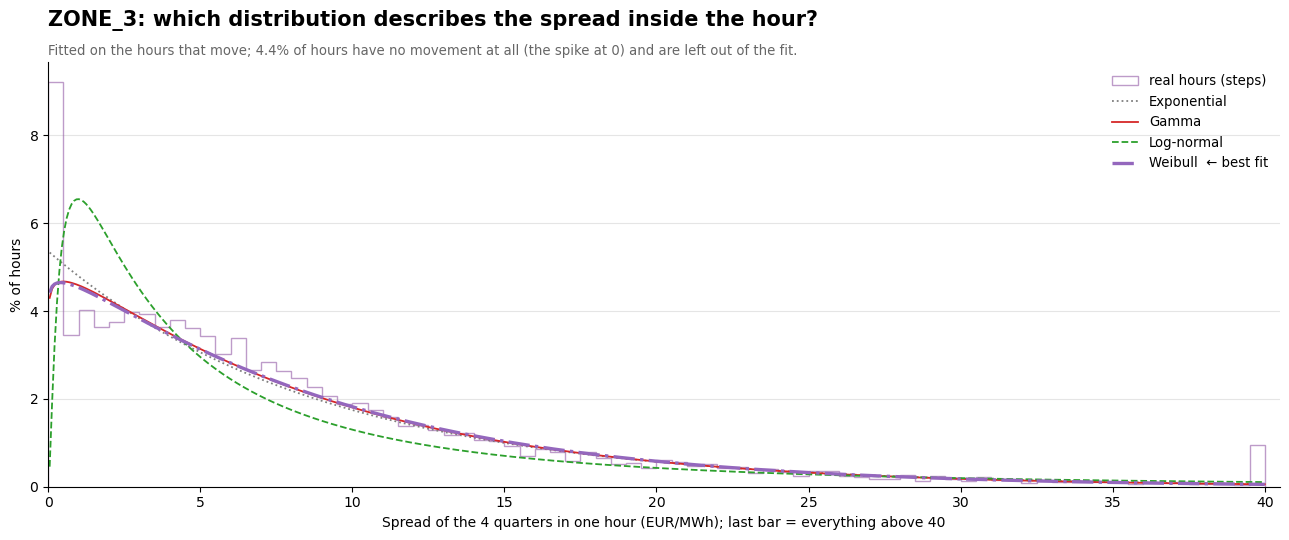

Fit quality (AIC: lower = better, compare within a zone; KS: largest gap between fitted and real, lower = better):


market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
distribution,,,,
Exponential,55624.0,58720.0,48942.0,53105.0
Gamma,55588.0,58712.0,48571.0,53089.0
Log-normal,56620.0,59606.0,49655.0,55314.0
Weibull,55543.0,58722.0,48621.0,53084.0


market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
distribution,,,,
Exponential,0.036,0.026,0.066,0.039
Gamma,0.030,0.028,0.010,0.027
Log-normal,0.063,0.061,0.061,0.096
Weibull,0.024,0.026,0.016,0.025


Best distribution per zone (by AIC):


,distribution
market_id,
ZONE_0,Weibull
ZONE_1,Gamma
ZONE_2,Gamma
ZONE_3,Weibull


In [24]:
# ---------------------------------------------------------------------------
# Within-hour variation (1b). Which distribution describes the spread of the 4 quarters? Uses only df.
# ---------------------------------------------------------------------------
from scipy import stats

ZONES = sorted(df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']

# Std of the 4 quarter prices of each hour (= std of its 4 residuals)
ws = (df.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].std(ddof=0)
        .rename('within_std').reset_index())

# Candidate distributions for a quantity that is always ≥ 0 and has a long right tail
CANDIDATES = {
    'Exponential': (stats.expon,       '#7f7f7f', ':'),
    'Gamma':       (stats.gamma,       '#d62728', '-'),
    'Log-normal':  (stats.lognorm,     '#2ca02c', '--'),
    'Weibull':     (stats.weibull_min, '#9467bd', '-.'),
}
FROZEN = 0.01                       # an hour with std below this has (almost) no movement at all
BAR_W, X_MAX = 0.5, 40
bins = np.arange(0, X_MAX + BAR_W, BAR_W)
grid = np.linspace(0.05, X_MAX, 500)

fit_rows = []
for z, c in zip(ZONES, COLORS):
    s_full = ws.loc[ws['market_id'] == z, 'within_std'].dropna().to_numpy()
    frozen_share = (s_full < FROZEN).mean()
    s = s_full[s_full >= FROZEN]                       # fit only hours that move (log-normal cannot handle 0)

    fig, ax = plt.subplots(figsize=(13, 5.5))
    ax.hist(np.clip(s_full, None, X_MAX), bins=bins, histtype='step', lw=0.9, alpha=0.6, color=c,
            weights=np.full(len(s_full), 100 / len(s_full)), label='real hours (steps)')

    fits = {}
    for name, (dist, col, ls) in CANDIDATES.items():
        params = dist.fit(s, floc=0)                   # starts at 0, like the data
        loglik = dist.logpdf(s, *params).sum()
        k = len(params) - 1                            # loc is fixed, not estimated
        fits[name] = dict(params=params, aic=2 * k - 2 * loglik,
                          ks=stats.kstest(s, dist.cdf, args=params).statistic)
    best = min(fits, key=lambda n: fits[n]['aic'])

    for name, (dist, col, ls) in CANDIDATES.items():
        # density → % of ALL hours per bar (moving hours only, so scale by their share)
        y = dist.pdf(grid, *fits[name]['params']) * (1 - frozen_share) * BAR_W * 100
        ax.plot(grid, y, color=col, ls=ls, lw=2.4 if name == best else 1.3,
                label=f'{name}{"  ← best fit" if name == best else ""}')
        fit_rows.append({'market_id': z, 'distribution': name, 'AIC': fits[name]['aic'],
                         'KS': fits[name]['ks'], 'best': name == best})

    ax.set(xlim=(0, X_MAX + 0.5), ylim=(0, None), ylabel='% of hours',
           xlabel=f'Spread of the 4 quarters in one hour (EUR/MWh); last bar = everything above {X_MAX}')
    ax.set_title(f'{z}: which distribution describes the spread inside the hour?',
                 fontsize=15, fontweight='bold', loc='left', pad=26)
    ax.text(0, 1.01, f'Fitted on the hours that move; {100 * frozen_share:.1f}% of hours have no movement at all '
                     f'(the spike at 0) and are left out of the fit.',
            transform=ax.transAxes, fontsize=9.5, color='#666666', va='bottom')
    ax.grid(axis='y', color='#e5e5e5', lw=0.8); ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, fontsize=9.5)
    plt.tight_layout(); plt.show()

fit_tab = pd.DataFrame(fit_rows)
print('Fit quality (AIC: lower = better, compare within a zone; KS: largest gap between fitted and real, lower = better):')
display(fit_tab.pivot(index='distribution', columns='market_id', values='AIC').round(0))
display(fit_tab.pivot(index='distribution', columns='market_id', values='KS').round(3))
print('Best distribution per zone (by AIC):')
fit_tab[fit_tab['best']].set_index('market_id')[['distribution']]

**Result**
- **Gamma and Weibull fit best, and they're almost tied in every zone.** Both have the smallest gaps to the real data (KS about 0.01–0.03). Weibull wins in ZONE_0 and ZONE_3, Gamma in ZONE_1 and ZONE_2.
- **Log-normal fits worst everywhere.** It puts too many hours at small spreads and too few in the middle.
- **Exponential is close behind in ZONE_0, ZONE_1 and ZONE_3:** most hours have a small spread, and big spreads become steadily rarer.
- **ZONE_2 is different.** Very small spreads are rare, so the curve rises before it falls, which a plain exponential can't capture. That's why Exponential does clearly worse there.
- **Some hours don't move at all:** 0.5–4.4% of hours, most in ZONE_3, have all 4 quarters at the same price.

**Interpretation:** the spread inside the hour follows a smooth, skewed shape. Most hours are calm, and big swings become steadily rarer, but they never fully disappear. There's no sign of separate "regimes", just a long tail. For the model, this means errors will be driven by a minority of volatile hours, so we use MAE and judge each zone separately.

### Extremes: when do the most extreme prices happen?
We list the 3 highest and 3 lowest quarter-hours per zone, and every day where prices went very low (< −400) or very high (> 400 EUR/MWh). This shows whether extremes are random one-offs or follow a pattern (time of day, season, several zones at once) that the model should be ready for.

In [25]:
# ---------------------------------------------------------------------------
# 0c. Extremes: the most extreme quarters and the days they belong to. Uses only df.
# ---------------------------------------------------------------------------
ZONES = sorted(df['market_id'].unique())
ex = df[['delivery_date', 'market_id', 'hour_index', 'quarter_index', 'price_eur_mwh']].copy()
ex['time'] = [f'{h - 1:02d}:{(q - 1) * 15:02d}' for h, q in zip(ex['hour_index'], ex['quarter_index'])]
cols = ['delivery_date', 'time', 'price_eur_mwh']

for z in ZONES:
    d = ex[ex['market_id'] == z]
    top = d.nlargest(3, 'price_eur_mwh')[cols].assign(kind='highest')
    low = d.nsmallest(3, 'price_eur_mwh')[cols].assign(kind='lowest')
    print(z); display(pd.concat([top, low]).reset_index(drop=True))


def by_day_and_zone(mask, label):
    t = ex[mask].groupby(['delivery_date', 'market_id']).size().unstack(fill_value=0)
    print(f'{label}, by day and zone:')
    display(t if len(t) else 'none')


by_day_and_zone(ex['price_eur_mwh'] < -400, 'Quarters below −400 EUR/MWh')
by_day_and_zone(ex['price_eur_mwh'] > 400, 'Quarters above 400 EUR/MWh')

ZONE_0


,delivery_date,time,price_eur_mwh,kind
0,2026-06-24,20:45,747.10,highest
1,2026-09-14,19:45,740.01,highest
2,2026-09-14,20:00,704.41,highest
3,2026-05-01,13:15,-499.99,lowest
4,2026-05-01,13:30,-499.99,lowest
5,2026-05-01,13:45,-499.99,lowest


ZONE_1


,delivery_date,time,price_eur_mwh,kind
0,2026-06-24,20:45,645.20,highest
1,2026-06-24,19:45,641.86,highest
2,2026-09-14,19:45,632.64,highest
3,2026-05-01,13:30,-498.65,lowest
4,2026-05-01,14:00,-497.80,lowest
5,2026-05-01,14:15,-497.80,lowest


ZONE_2


...

,delivery_date,time,price_eur_mwh,kind
0,2026-08-13,19:45,487.38,highest
1,2026-08-12,19:45,461.17,highest
2,2026-06-24,19:45,433.42,highest
3,2026-05-01,13:30,-498.65,lowest
4,2026-05-01,14:00,-497.80,lowest
5,2026-05-01,14:15,-497.80,lowest


Quarters below −400 EUR/MWh, by day and zone:


market_id,ZONE_0,ZONE_1,ZONE_3
delivery_date,,,
2026-04-26,4,4,4
2026-05-01,8,8,8


Quarters above 400 EUR/MWh, by day and zone:


market_id,ZONE_0,ZONE_1,ZONE_3
delivery_date,,,
2025-10-01,1,0,0
2025-10-13,1,0,0
2025-10-14,4,4,0
2026-03-04,1,0,0
2026-05-28,4,0,0
2026-06-01,1,0,0
2026-06-18,6,4,0
2026-06-23,12,10,0
2026-06-24,13,12,1


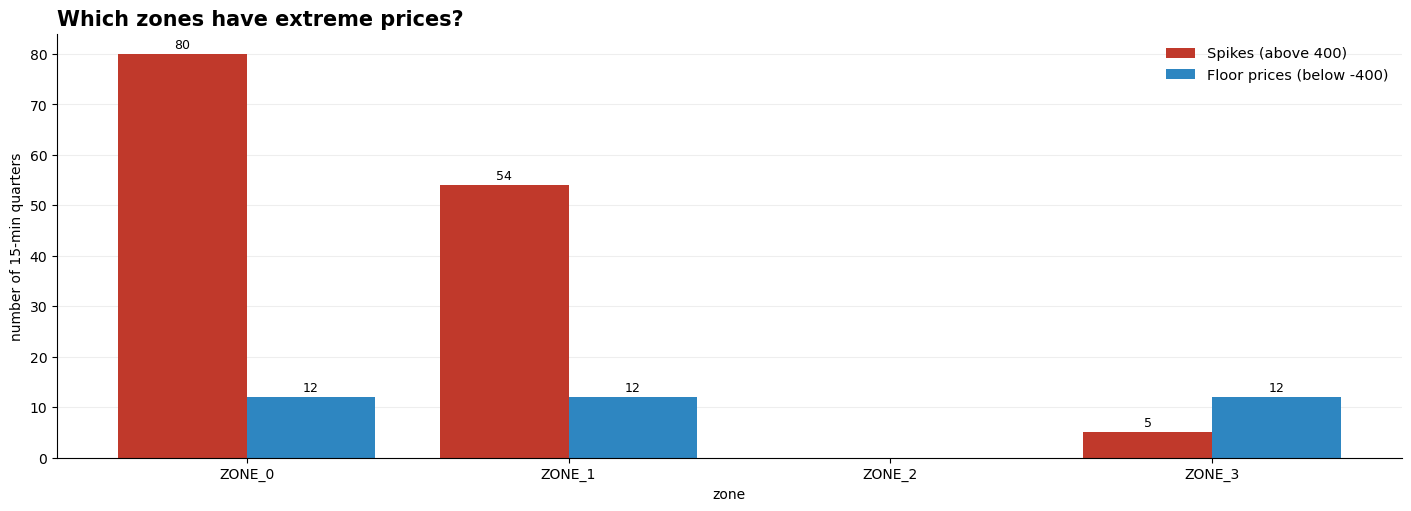

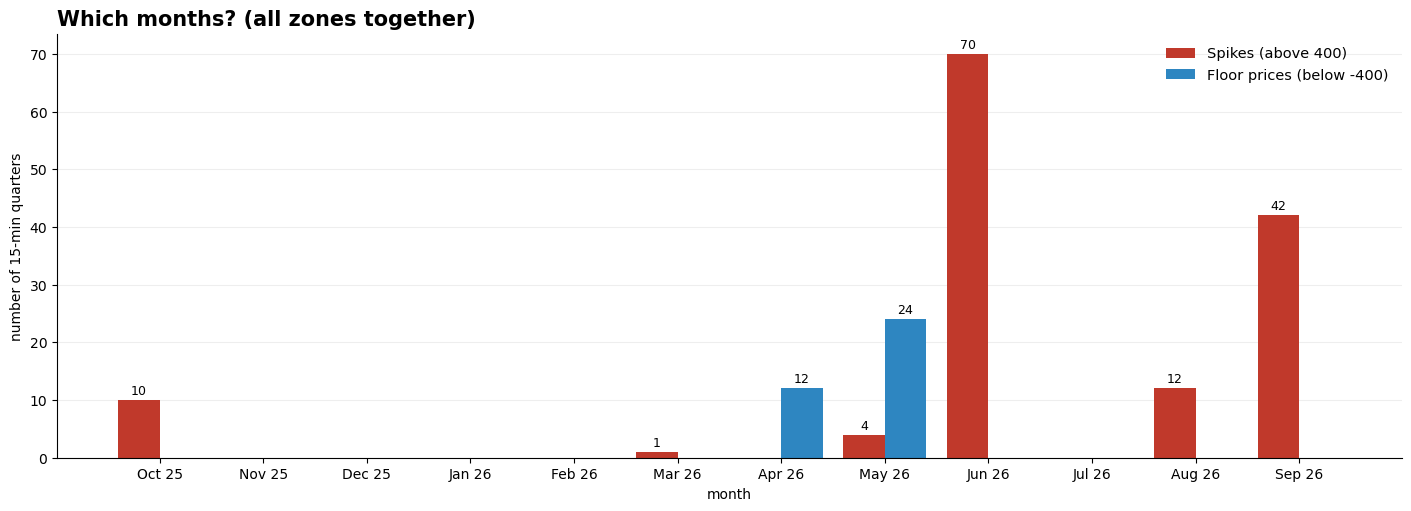

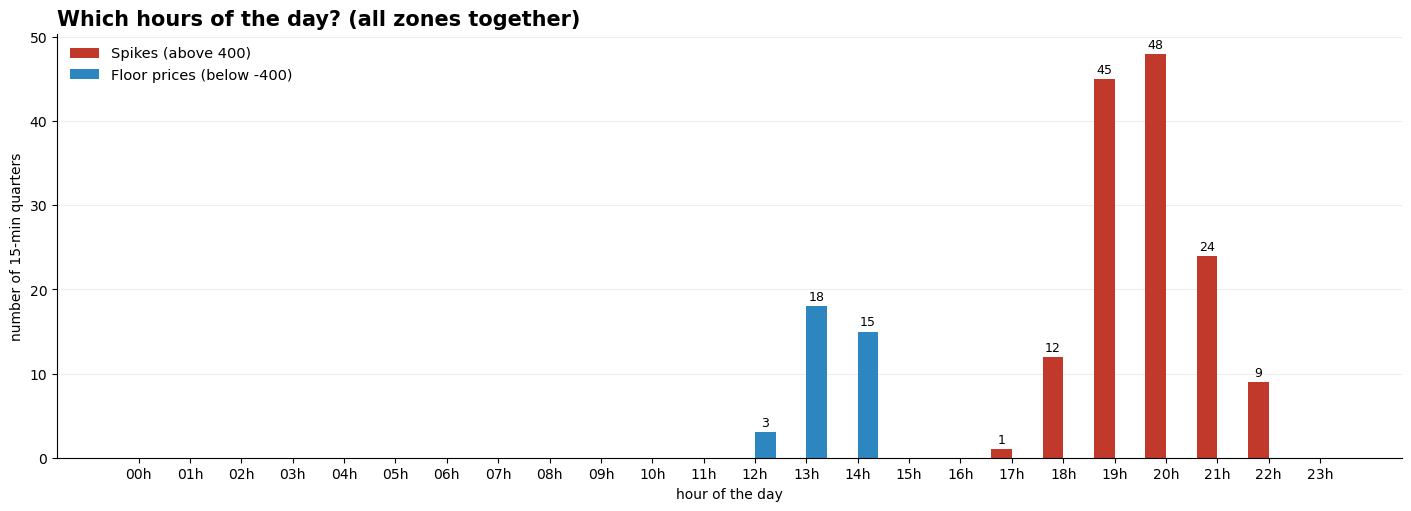

In [26]:
# ---------------------------------------------------------------------------
# 0c (graphs). Extreme prices made simple: which zone, which month, which hour. Uses only df.
#   Spike = a quarter above 400 EUR/MWh · Floor = a quarter below −400 EUR/MWh
# ---------------------------------------------------------------------------
HIGH, LOW = 400, -400
SPIKE_C, FLOOR_C = '#c0392b', '#2e86c1'

e = df[['delivery_date', 'market_id', 'hour_index', 'price_eur_mwh']].copy()
e['delivery_date'] = pd.to_datetime(e['delivery_date'])
e['spike'] = e['price_eur_mwh'] > HIGH
e['floor'] = e['price_eur_mwh'] < LOW


def two_bars(table, title, xlabel):
    # Side-by-side bars: red = spikes, blue = floor, with the number on top of each bar
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(14, 5), layout='constrained')
    for col, color, shift, label in [('spike', SPIKE_C, -0.2, f'Spikes (above {HIGH})'),
                                     ('floor', FLOOR_C, 0.2, f'Floor prices (below {LOW})')]:
        bars = ax.bar(x + shift, table[col], width=0.4, color=color, label=label)
        ax.bar_label(bars, labels=[f'{v:.0f}' if v > 0 else '' for v in table[col]], fontsize=9, padding=2)
    ax.set_xticks(x, table.index)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('number of 15-min quarters')
    ax.set_title(title, fontsize=15, fontweight='bold', loc='left')
    ax.legend(frameon=False, fontsize=10.5)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#eeeeee'); ax.set_axisbelow(True)
    plt.show()


# 1) Which zones?
by_zone = e.groupby('market_id')[['spike', 'floor']].sum()
two_bars(by_zone, 'Which zones have extreme prices?', 'zone')

# 2) Which months?
by_month = e.groupby(e['delivery_date'].dt.to_period('M'))[['spike', 'floor']].sum()
by_month.index = by_month.index.strftime('%b %y')
two_bars(by_month, 'Which months? (all zones together)', 'month')

# 3) Which hours of the day?
by_hour = e.groupby('hour_index')[['spike', 'floor']].sum().reindex(range(1, 25), fill_value=0)
by_hour.index = [f'{h - 1:02d}h' for h in by_hour.index]
two_bars(by_hour, 'Which hours of the day? (all zones together)', 'hour of the day')

**Result**
- **Zones:** ZONE_0 (80) and ZONE_1 (54) have almost all the spikes, ZONE_3 has only 5, and ZONE_2 has none. Floor prices hit ZONE_0, 1 and 3 equally (12 each), on the same days.
- **Months:** spikes mostly in **June (70)** and **September (42)**. Floor prices only in **April and May**.
- **Hours:** spikes in the **evening (18–21h, peak at 19–20h)**. Floor prices at **midday (12–14h)**.

**For the model:** extremes are rare but always at the same times, evening for spikes and sunny midday for floor prices, so hour of day and zone are key features.

## Seasonal Analysis

In [27]:
# ---------------------------------------------------------------------------
# Seasonal analysis: (1) all zones together, (2) zone by zone. Uses only df.
# ---------------------------------------------------------------------------
SEASON_ORDER = ['autumn', 'winter', 'spring', 'summer']
SEASON_COL = {'autumn': '#c8743a', 'winter': '#2f6db5', 'spring': '#3a9a5b', 'summer': '#e0a800'}
SEASON_OF = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring',
             6: 'summer', 7: 'summer', 8: 'summer', 9: 'autumn', 10: 'autumn', 11: 'autumn'}


def prepare_seasons(df, by_zone=True):
    # Minimal working copy: real dates, a season column, and (optionally) all zones merged into one group
    d = df[['delivery_date', 'market_id', 'hour_index', 'price_eur_mwh']].copy()
    d['delivery_date'] = pd.to_datetime(d['delivery_date'])
    d['season'] = pd.Categorical(d['delivery_date'].dt.month.map(SEASON_OF), SEASON_ORDER, ordered=True)
    if not by_zone:
        d['market_id'] = 'ALL ZONES'
    return d


def season_summary(d, stat='median'):
    # Hour-of-day profile and summary table per group (zone or ALL ZONES) and season
    keys = ['market_id', 'season']
    profile = d.groupby(keys + ['hour_index'], observed=True)['price_eur_mwh'].agg(stat).unstack()
    g = d.groupby(keys, observed=True)['price_eur_mwh']
    summary = pd.DataFrame({
        'days': d.groupby(keys, observed=True)['delivery_date'].nunique(),
        'mean': g.mean(), 'median': g.median(), 'std': g.std(),
        'p5': g.quantile(0.05), 'p95': g.quantile(0.95), 'min': g.min(), 'max': g.max(),
        '% negative': g.apply(lambda s: 100 * (s < 0).mean()),
        'cheapest hour': profile.idxmin(axis=1), 'priciest hour': profile.idxmax(axis=1),
        'daily swing': profile.max(axis=1) - profile.min(axis=1),
    })
    return profile, summary


def plot_profiles(profile, stat, title):
    # One panel per group, one line per season
    groups = profile.index.get_level_values('market_id').unique()
    width = 13 if len(groups) == 1 else 4.4 * len(groups)
    fig, axes = plt.subplots(1, len(groups), figsize=(width, 5), sharey=True, layout='constrained')
    for ax, z in zip(np.atleast_1d(axes), groups):
        for s in SEASON_ORDER:
            if (z, s) in profile.index:
                ax.plot(profile.columns, profile.loc[(z, s)], color=SEASON_COL[s], lw=1.8, marker='o', ms=3, label=s)
        ax.axhline(0, color='#999999', lw=0.6)
        ax.set(xticks=range(1, 25) if len(groups) == 1 else [1, 6, 12, 18, 24], xlabel='hour of the day')
        ax.set_title(z, fontsize=12, fontweight='bold', loc='left')
        ax.grid(axis='y', color='#e5e5e5', lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
    np.atleast_1d(axes)[0].set_ylabel('EUR/MWh')
    np.atleast_1d(axes)[0].legend(frameon=False, fontsize=9)
    fig.suptitle(f'{title} ({stat})', fontsize=15, fontweight='bold', x=0.01, ha='left')
    plt.show()

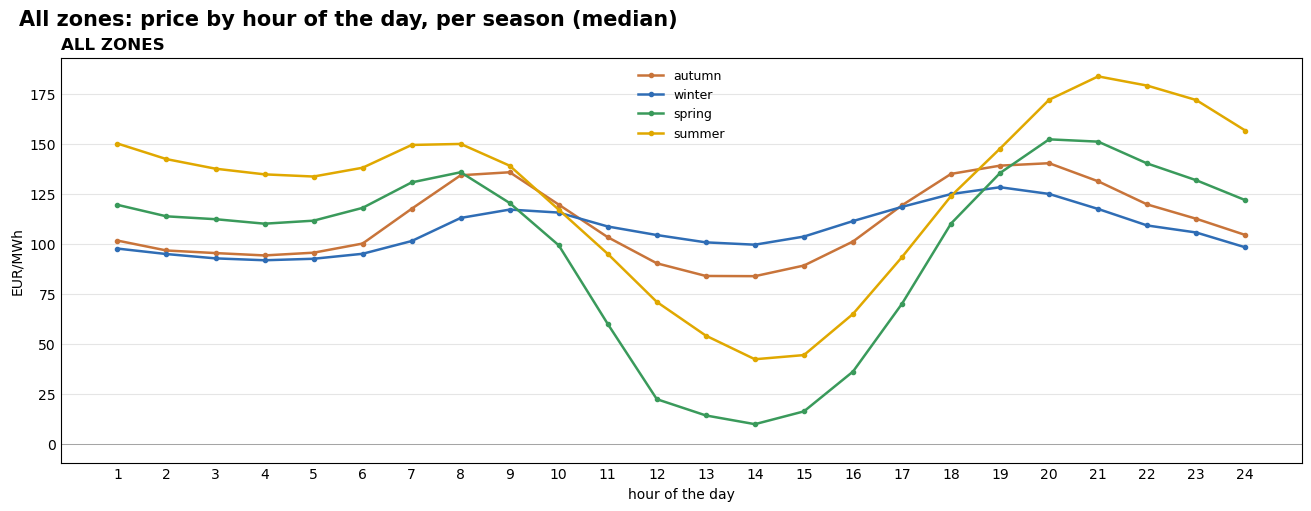

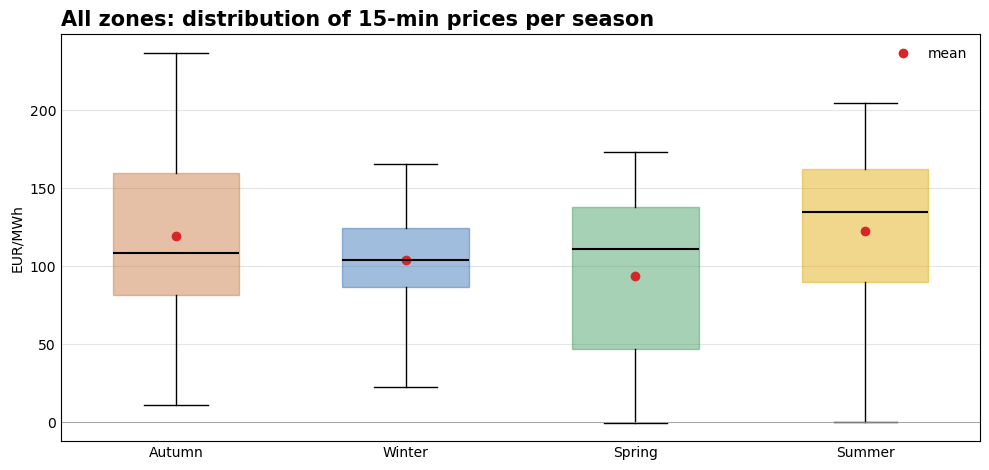

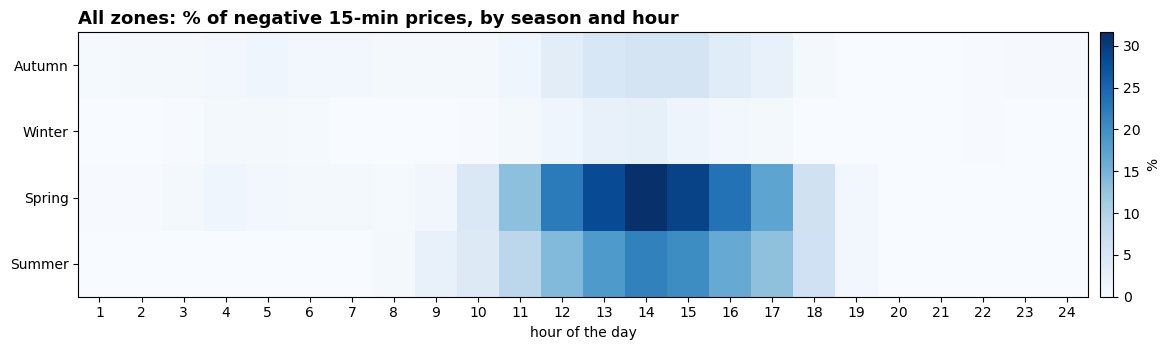

days   mean  median   std    p5    p95    min    max  \
market_id season                                                         
ALL ZONES autumn    90  119.3   108.2  66.7  11.0  236.7  -19.0  740.0   
          winter    90  104.2   104.0  40.3  22.9  165.5   -0.6  397.6   
          spring    91   93.4   110.9  65.1  -0.2  173.0 -500.0  468.3   
          summer    92  122.3   135.0  66.0  -0.0  204.7  -53.0  747.1   

                  % negative  cheapest hour  priciest hour  daily swing  
market_id season                                                         
ALL ZONES autumn         1.5             14             20         56.4  
          winter         0.5              4             19         36.5  
          spring         7.6             14             20        142.2  
          summer         5.3             14             21        141.2

In [28]:
# ---------------------------------------------------------------------------
# (1) ALL ZONES TOGETHER
# ---------------------------------------------------------------------------
d_all = prepare_seasons(df, by_zone=False)
profile_all, summary_all = season_summary(d_all)

# a) The typical day in each season
plot_profiles(profile_all, 'median', 'All zones: price by hour of the day, per season')

# b) How prices are spread in each season (box = middle 50%, whiskers = 5–95%)
fig, ax = plt.subplots(figsize=(10, 4.8))
data = [d_all.loc[d_all.season == s, 'price_eur_mwh'] for s in SEASON_ORDER]
bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.55)
for box, s in zip(bp['boxes'], SEASON_ORDER):
    box.set(facecolor=SEASON_COL[s], alpha=0.45, edgecolor=SEASON_COL[s])
for med in bp['medians']:
    med.set(color='k', lw=1.5)
ax.plot(range(1, 5), [x.mean() for x in data], 'o', color='#d62728', ms=6, label='mean')
ax.axhline(0, color='#999999', lw=0.6)
ax.set(xticks=range(1, 5), xticklabels=[s.capitalize() for s in SEASON_ORDER], ylabel='EUR/MWh')
ax.set_title('All zones: distribution of 15-min prices per season', fontsize=15, fontweight='bold', loc='left')
ax.grid(axis='y', color='#e5e5e5', lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# c) Share of negative prices by season and hour
neg = d_all.assign(neg=d_all.price_eur_mwh < 0).groupby(['season', 'hour_index'], observed=True).neg.mean().unstack() * 100
fig, ax = plt.subplots(figsize=(13, 3.6))
im = ax.imshow(neg, aspect='auto', cmap='Blues', vmin=0)
ax.set(xticks=range(24), xticklabels=range(1, 25), yticks=range(len(neg)), yticklabels=[s.capitalize() for s in neg.index],
       xlabel='hour of the day')
ax.set_title('All zones: % of negative 15-min prices, by season and hour', fontsize=13, fontweight='bold', loc='left')
fig.colorbar(im, ax=ax, label='%', pad=0.01)
plt.tight_layout(); plt.show()

summary_all.round(1)

In [29]:
# ---------------------------------------------------------------------------
# Movement INSIDE the hour, per season: (1) all zones together, (2) zone by zone. Uses only df.
# ---------------------------------------------------------------------------
HOURKEY = ['delivery_date', 'market_id', 'hour_index']

iq = df[['delivery_date', 'market_id', 'hour_index', 'quarter_index', 'price_eur_mwh']].copy()
iq['delivery_date'] = pd.to_datetime(iq['delivery_date'])
iq['season'] = pd.Categorical(iq['delivery_date'].dt.month.map(SEASON_OF), SEASON_ORDER, ordered=True)
iq['hourly'] = iq.groupby(HOURKEY)['price_eur_mwh'].transform('mean')
iq['residual'] = iq['price_eur_mwh'] - iq['hourly']          # 15-min price − hourly average
iq['abs_res'] = iq['residual'].abs()                           # size of the move inside the hour

# One row per hour: size of the movement and its direction (Q4 − Q1)
wide = iq.pivot_table(index=HOURKEY, columns='quarter_index', values='residual').add_prefix('r').reset_index()
wide.columns.name = None
ih = wide.merge(iq.groupby(HOURKEY, as_index=False).agg(season=('season', 'first')), on=HOURKEY)
ih['season'] = pd.Categorical(ih['season'], SEASON_ORDER, ordered=True)
ih['move'] = ih[['r1', 'r2', 'r3', 'r4']].abs().mean(axis=1)                                   # mean |residual|
ih['swing'] = ih[['r1', 'r2', 'r3', 'r4']].max(axis=1) - ih[['r1', 'r2', 'r3', 'r4']].min(axis=1)  # highest − lowest quarter
ih['tilt'] = ih['r4'] - ih['r1']                                                                # > 0 rises, < 0 falls


def intra_summary(h, keys):
    g = h.groupby(keys, observed=True)
    return pd.DataFrame({
        'hours': g.size(),
        'mean move': g['move'].mean(),
        'median move': g['move'].median(),
        'p90 move': g['move'].quantile(0.9),
        'median swing': g['swing'].median(),
        '% hours swing > 20': g['swing'].apply(lambda s: 100 * (s > 20).mean()),
        '% rising hours': g['tilt'].apply(lambda s: 100 * (s > 0).mean()),
    })


def plot_by_hour(h, value, ylabel, title, zero_line=False):
    # One panel per zone (or a single wide panel if only one group), one line per season
    groups = sorted(h['market_id'].unique())
    width = 13 if len(groups) == 1 else 4.4 * len(groups)
    fig, axes = plt.subplots(1, len(groups), figsize=(width, 4.8), sharey=True, layout='constrained')
    prof = h.groupby(['market_id', 'season', 'hour_index'], observed=True)[value].mean().unstack()
    for ax, z in zip(np.atleast_1d(axes), groups):
        for s in SEASON_ORDER:
            if (z, s) in prof.index:
                ax.plot(prof.columns, prof.loc[(z, s)], color=SEASON_COL[s], lw=1.8, marker='o', ms=3, label=s.capitalize())
        if zero_line:
            ax.axhline(0, color='#888888', lw=0.8)
        ax.set(xticks=range(1, 25) if len(groups) == 1 else [1, 6, 12, 18, 24], xlabel='hour of the day')
        ax.set_title(z, fontsize=12, fontweight='bold', loc='left')
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        ax.grid(axis='y', color='#ececec', lw=0.9); ax.set_axisbelow(True); ax.tick_params(length=0)
    np.atleast_1d(axes)[0].set_ylabel(ylabel)
    np.atleast_1d(axes)[0].legend(frameon=False, fontsize=9)
    fig.suptitle(title, fontsize=15, fontweight='bold', x=0.01, ha='left')
    plt.show()

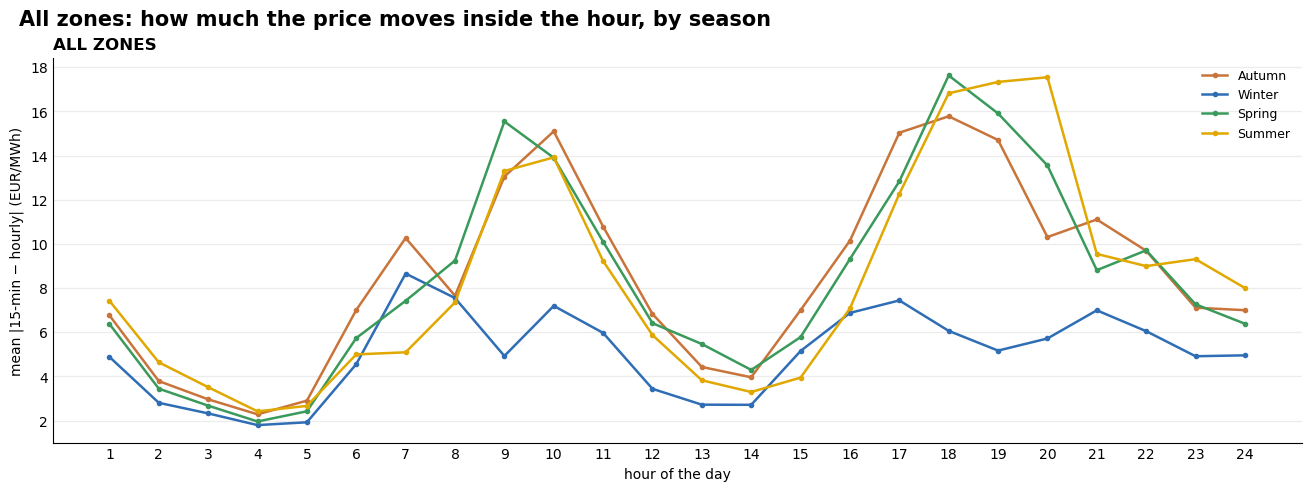

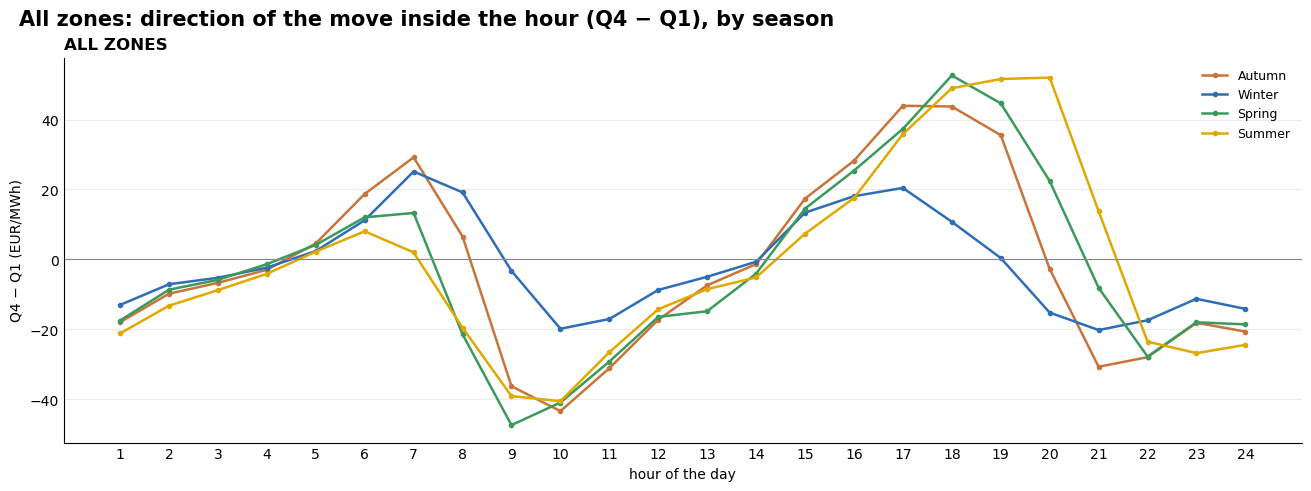

,hours,mean move,median move,p90 move,median swing,% hours swing > 20,% rising hours
season,,,,,,,
autumn,8640,8.6,5.9,19.0,17.7,45.2,40.4
winter,8640,5.0,3.6,10.4,10.8,24.1,40.5
spring,8736,8.4,5.7,19.6,17.0,44.6,39.6
summer,8832,8.3,5.7,18.3,17.3,43.9,39.2


In [30]:
# ---------------------------------------------------------------------------
# (1) ALL ZONES TOGETHER
# ---------------------------------------------------------------------------
ih_all = ih.assign(market_id='ALL ZONES')

# a) How much the price moves inside each hour, by season
plot_by_hour(ih_all, 'move', 'mean |15-min − hourly| (EUR/MWh)',
             'All zones: how much the price moves inside the hour, by season')

# b) In which direction: Q4 − Q1 (> 0 = price rises through the hour, < 0 = falls)
plot_by_hour(ih_all, 'tilt', 'Q4 − Q1 (EUR/MWh)',
             'All zones: direction of the move inside the hour (Q4 − Q1), by season', zero_line=True)

# c) Summary per season
intra_summary(ih_all, ['season']).round(1)

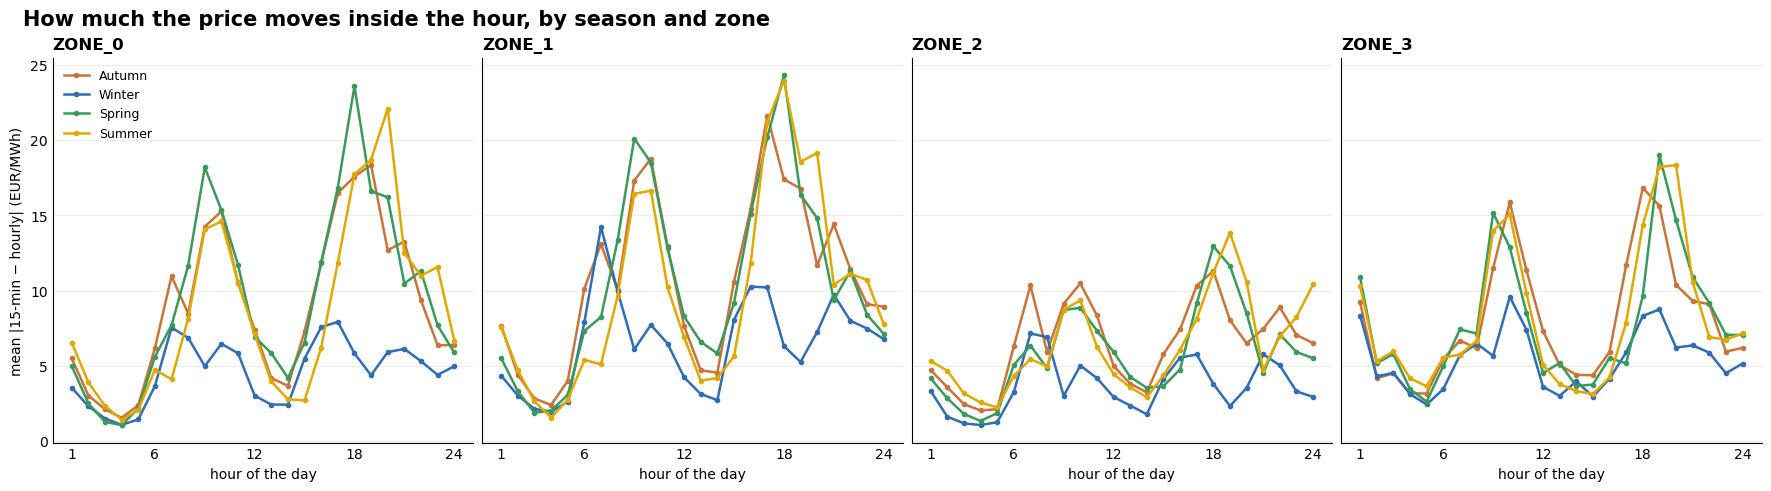

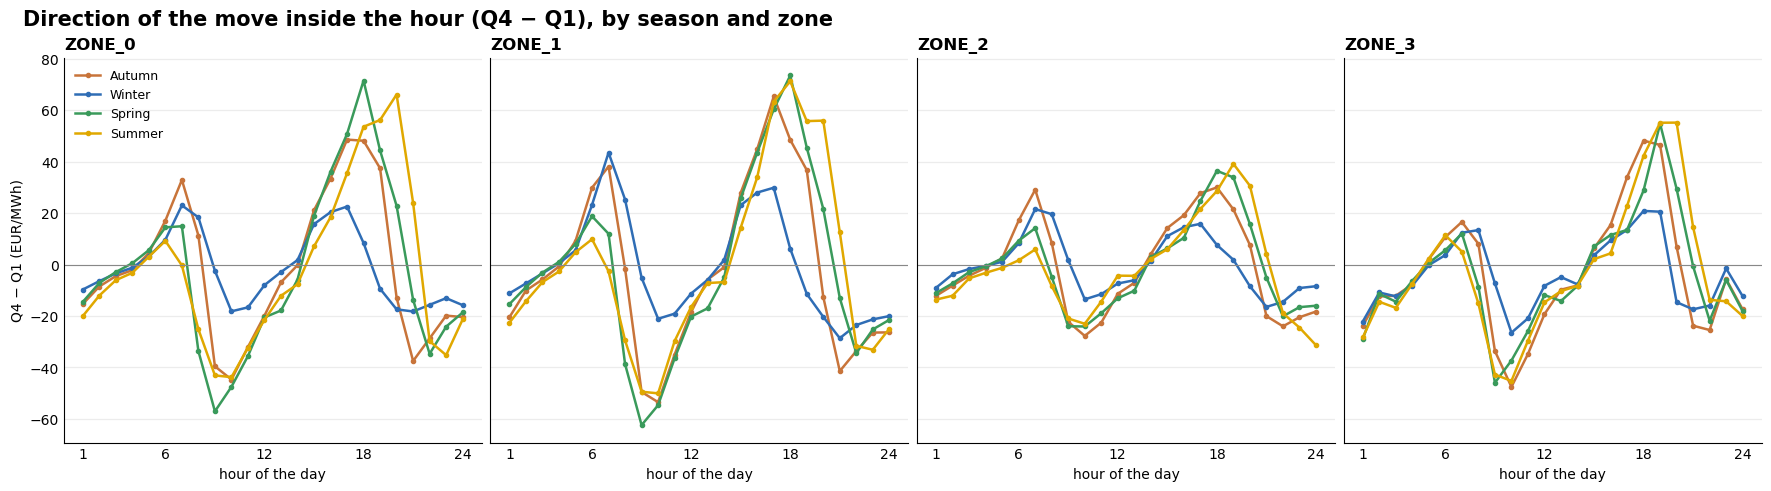

hours  mean move  median move  p90 move  median swing  \
market_id season                                                          
ZONE_0    autumn   2160        9.0          5.7      21.0          17.5   
          winter   2160        4.6          3.4       9.4          10.1   
          spring   2184        9.4          6.3      22.7          19.2   
          summer   2208        8.6          5.6      18.6          17.9   
ZONE_1    autumn   2160       10.7          7.5      22.8          22.5   
          winter   2160        6.5          4.6      13.1          13.6   
          spring   2184       10.5          7.1      25.7          21.8   
          summer   2208        9.9          6.6      22.4          20.2   
ZONE_2    autumn   2160        6.5          5.1      13.9          14.4   
          winter   2160        3.6          2.8       7.5           8.3   
          spring   2184        5.8          4.6      12.2          13.6   
          summer   2208        6.3          5.0      13.6          14.2   
ZONE_3    autumn   2160        8.1          5.9      17.8          17.9   
          winter   2160        5.4          4.1      11.1          12.2   
          spring   2184        7.9          5.4      18.6          16.5   
          summer   2208        8.2          5.8      18.9          18.0   

                  % hours swing > 20  % rising hours  
market_id season                                      
ZONE_0    autumn                45.0            40.2  
          winter                20.7            41.3  
          spring                48.5            39.9  
          summer                45.6            38.4  
ZONE_1    autumn                54.2            41.6  
          winter                34.4            41.1  
          spring                52.4            42.2  
          summer                50.4            40.4  
ZONE_2    autumn                35.9            41.3  
          winter                12.8            40.6  
          spring                34.0            39.9  
          summer                34.5            41.6  
ZONE_3    autumn                45.8            38.7  
          winter                28.3            38.8  
          spring                43.6            36.3  
          summer                45.1            36.3

In [31]:
# ---------------------------------------------------------------------------
# (2) ZONE BY ZONE
# ---------------------------------------------------------------------------
plot_by_hour(ih, 'move', 'mean |15-min − hourly| (EUR/MWh)',
             'How much the price moves inside the hour, by season and zone')
plot_by_hour(ih, 'tilt', 'Q4 − Q1 (EUR/MWh)',
             'Direction of the move inside the hour (Q4 − Q1), by season and zone', zero_line=True)

intra_summary(ih, ['market_id', 'season']).round(1)

---
# 1. The hourly price hides a lot

The black steps are what we're given: one price per hour. The coloured line is what we need to predict: the real 15-minute prices. The gap between them is the residual, and that's what this whole challenge is about.

The top panel shows 15 days in August 2026 for ZONE_0. The bottom panel zooms in on 2 days so you can see the movement inside each hour. Change `WINDOW_START` to explore another period; it must end before September.

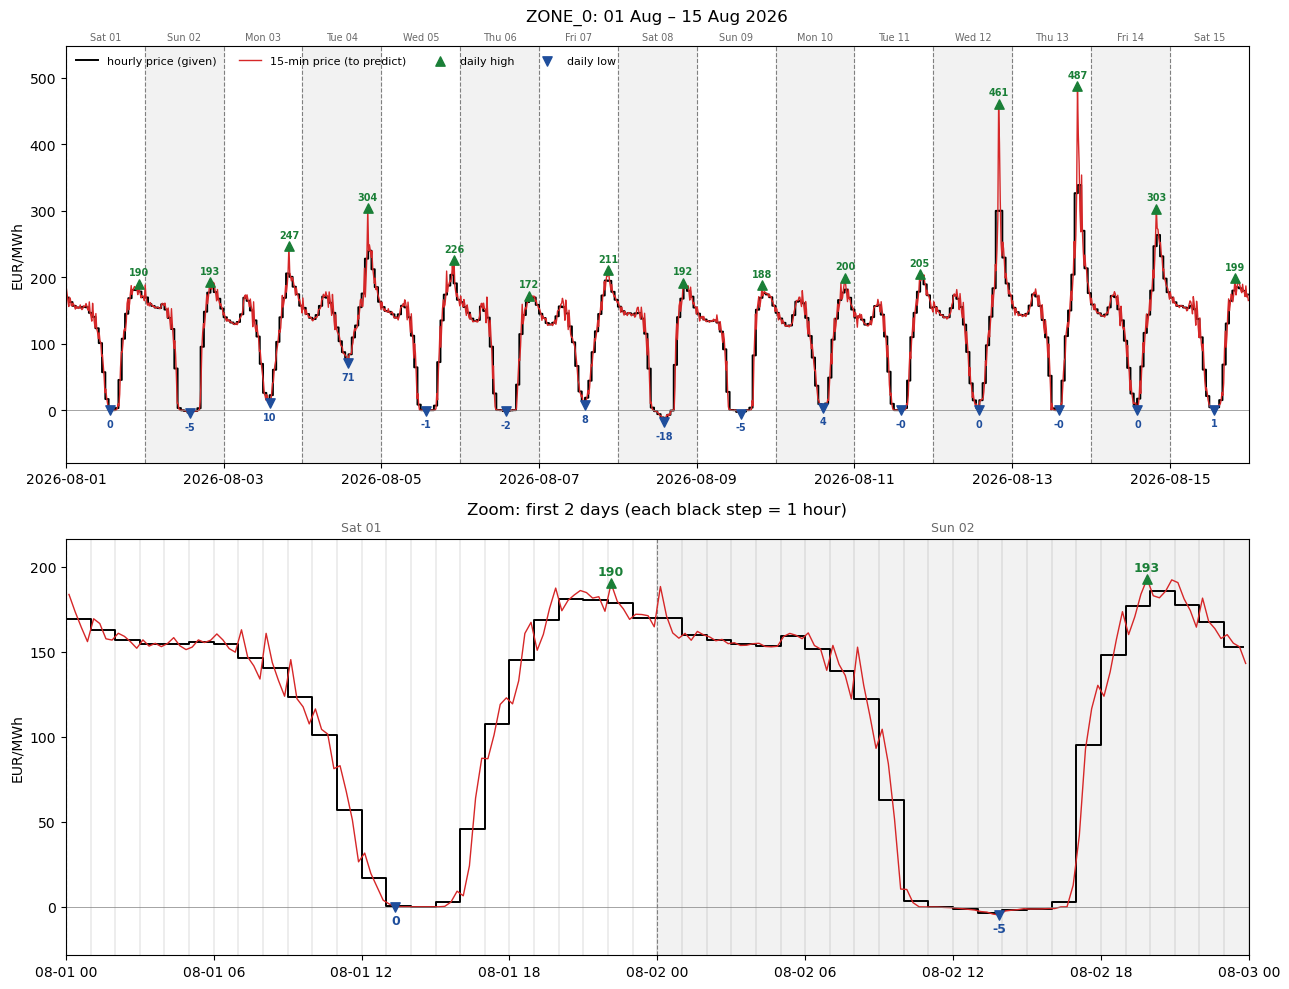

In [32]:
# ---------------------------------------------------------------------------
# 1a. 15 days of real prices: 15-min price vs the hourly price we are given. Uses only df.
# ---------------------------------------------------------------------------
ZONES = sorted(df['market_id'].unique())
EDA_END = pd.Timestamp('2026-08-31')
WINDOW_START = pd.Timestamp('2026-08-01')
WINDOW_DAYS, ZOOM_DAYS = 15, 2
assert WINDOW_START + pd.Timedelta(days=WINDOW_DAYS - 1) <= EDA_END, 'window must end before September'

HIGH_COLOR, LOW_COLOR = '#1a7f37', '#1f4e9c'     # green = daily high, blue = daily low
DAY_SHADE = '#f2f2f2'                            # grey band on every other day

# Copy of df with real dates and the hourly price (average of the 4 quarters)
pw = df[['delivery_date', 'market_id', 'hour_index', 'quarter_index', 'price_eur_mwh']].copy()
pw['delivery_date'] = pd.to_datetime(pw['delivery_date'])
pw['hourly_price'] = pw.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].transform('mean')


def plot_window(zone, color, start=WINDOW_START, days=WINDOW_DAYS, zoom_days=ZOOM_DAYS):
    # Top: full window. Bottom: zoom. Black step = hourly price, coloured line = 15-min price.
    end = start + pd.Timedelta(days=days)
    w = pw[(pw.market_id == zone) & (pw.delivery_date >= start) & (pw.delivery_date < end)].copy()
    w['time'] = (w.delivery_date + pd.to_timedelta(w.hour_index - 1, unit='h')
                 + pd.to_timedelta((w.quarter_index - 1) * 15, unit='min'))
    w['plot_time'] = w.time + pd.Timedelta(minutes=7.5)          # plotted at quarter centre
    w = w.sort_values('time')
    zoom_end = start + pd.Timedelta(days=zoom_days)

    # Highest and lowest 15-min price of each day
    highs = w.loc[w.groupby('delivery_date').price_eur_mwh.idxmax()]
    lows = w.loc[w.groupby('delivery_date').price_eur_mwh.idxmin()]

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(13, 10))
    for ax, part_end, label_size in [(top, end, 7), (bottom, zoom_end, 9)]:
        part = w[w.time < part_end]
        day_list = pd.date_range(start, part_end - pd.Timedelta(days=1))

        # Day separation: alternating grey bands, a line at each midnight, the date on top
        for i, d in enumerate(day_list):
            if i % 2 == 1:
                ax.axvspan(d, d + pd.Timedelta(days=1), color=DAY_SHADE, zorder=0)
            ax.axvline(d, color='grey', lw=0.8, ls='--', zorder=1)
            ax.text(d + pd.Timedelta(hours=12), 1.01, f'{d:%a %d}', transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', fontsize=label_size, color='dimgrey')

        ax.step(part.time, part.hourly_price, where='post', color='k', lw=1.4, label='hourly price (given)')
        ax.plot(part.plot_time, part.price_eur_mwh, color=color, lw=1, label='15-min price (to predict)')

        # Mark and label the daily highs and lows
        hi, lo = highs[highs.time < part_end], lows[lows.time < part_end]
        ax.scatter(hi.plot_time, hi.price_eur_mwh, marker='^', s=45, color=HIGH_COLOR, zorder=5, label='daily high')
        ax.scatter(lo.plot_time, lo.price_eur_mwh, marker='v', s=45, color=LOW_COLOR, zorder=5, label='daily low')
        for _, r in hi.iterrows():
            ax.annotate(f'{r.price_eur_mwh:.0f}', (r.plot_time, r.price_eur_mwh), xytext=(0, 6),
                        textcoords='offset points', ha='center', fontsize=label_size, color=HIGH_COLOR, fontweight='bold')
        for _, r in lo.iterrows():
            ax.annotate(f'{r.price_eur_mwh:.0f}', (r.plot_time, r.price_eur_mwh), xytext=(0, -12),
                        textcoords='offset points', ha='center', fontsize=label_size, color=LOW_COLOR, fontweight='bold')

        ax.axhline(0, color='grey', lw=0.5)
        ax.set_xlim(start, part_end)
        ax.margins(y=0.12)                                       # room for the labels
        ax.set_ylabel('EUR/MWh')

    top.set_title(f'{zone}: {start:%d %b} – {end - pd.Timedelta(days=1):%d %b %Y}', pad=18)
    top.legend(frameon=False, ncol=4, loc='upper left', fontsize=8)
    bottom.set_title(f'Zoom: first {zoom_days} days (each black step = 1 hour)', pad=18)
    for h in pd.date_range(start, zoom_end, freq='h'):
        bottom.axvline(h, color='grey', lw=0.2, zorder=1)
    plt.tight_layout(); plt.show()


plot_window(ZONES[0], '#d62728')

---
# 2. Prices slide toward the next hour

Averaging the residuals of each quarter position (Q1–Q4) over the whole year, hour by hour, shows the typical shape. Where Q1 is below Q4 the price rises inside the hour; where Q1 is above Q4 it falls.

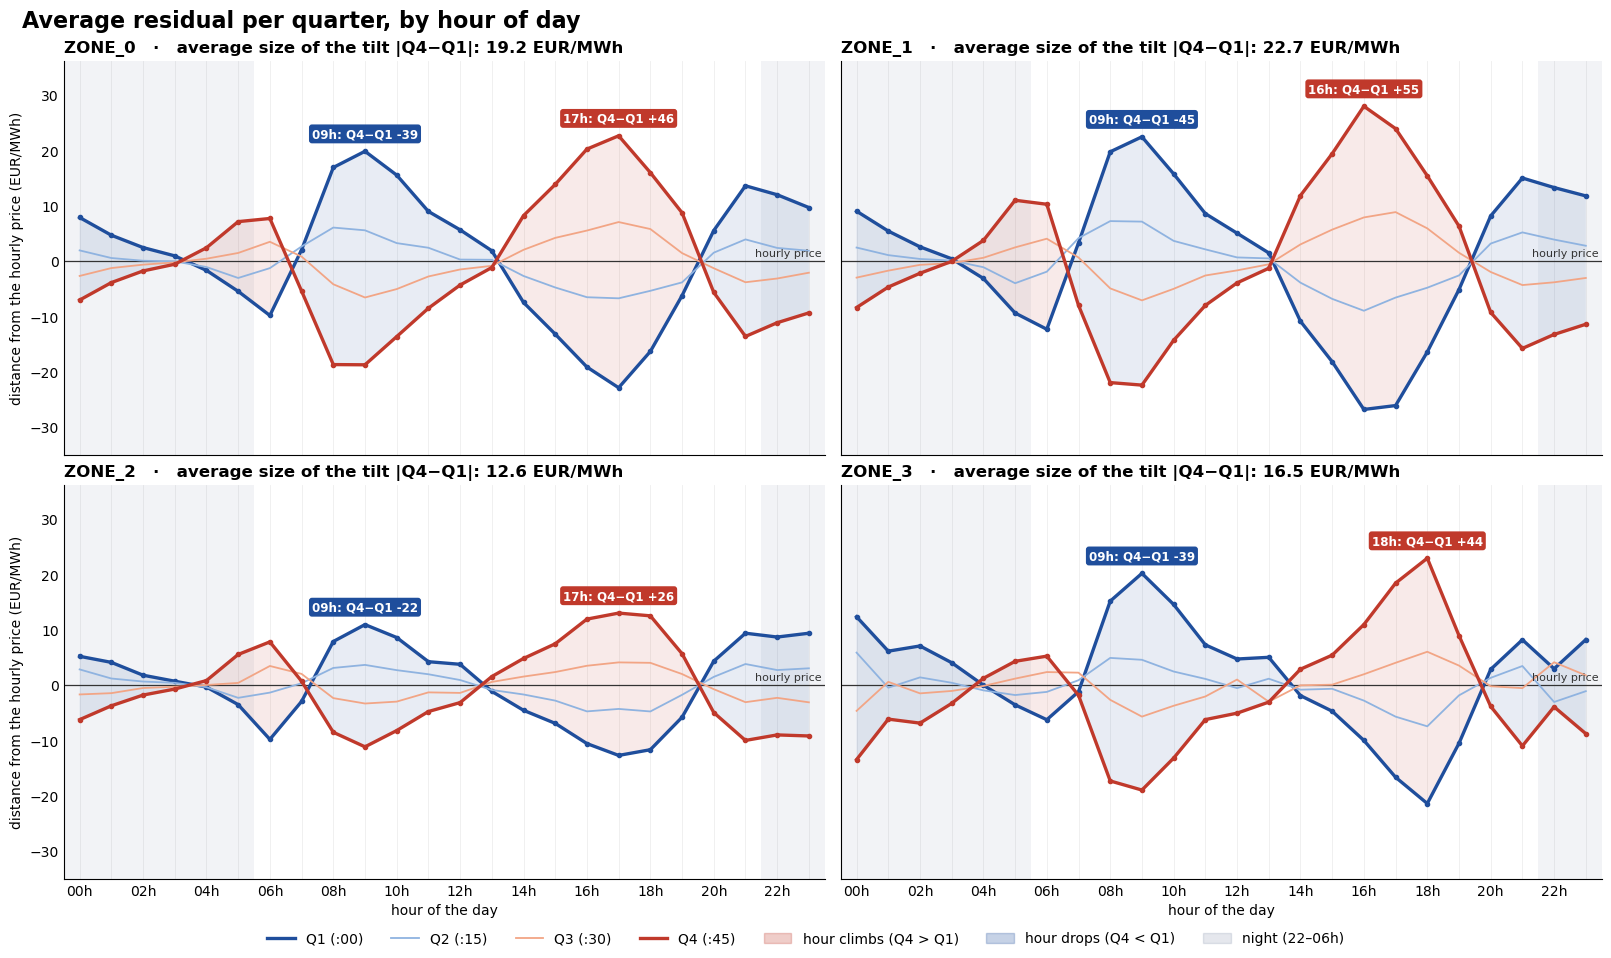

In [33]:
# ---------------------------------------------------------------------------
# 2a. Average Q1..Q4 residual for each hour of the day, per zone. Uses only df.
# ---------------------------------------------------------------------------
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ZONES = sorted(df['market_id'].unique())
Q_COLORS = ['#1f4e9c', '#8fb3e0', '#f2a585', '#c0392b']     # Q1 dark blue … Q4 dark red
Q_WIDTH = [2.4, 1.3, 1.3, 2.4]                               # edges thick, middle thin
UP, DOWN, NIGHT = '#c0392b', '#1f4e9c', '#2a3f6b'
HOURS = np.arange(24)                                        # 0 = 00:00–01:00


def add_residual(frame):
    # residual = 15-min price − hourly price (average of the hour's 4 quarters)
    f = frame.copy()
    hourly = f.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].transform('mean')
    f['residual'] = f['price_eur_mwh'] - hourly
    return f


def quarter_lines(frame, title='Average residual per quarter, by hour of day'):
    # Mean residual of Q1..Q4 vs hour of day, one panel per zone. Returns the mean shape.
    if 'residual' not in frame.columns:
        frame = add_residual(frame)
    avg = frame.groupby(['market_id', 'hour_index', 'quarter_index'])['residual'].mean()

    fig, axes = plt.subplots(2, 2, figsize=(16, 9.5), sharex=True, sharey=True, layout='constrained')
    for ax, z in zip(axes.ravel(), ZONES):
        q = {k: avg[z].xs(k, level='quarter_index').reindex(range(1, 25)).to_numpy() for k in range(1, 5)}

        # Background: night hours, hour grid
        ax.axvspan(-0.5, 5.5, color=NIGHT, alpha=0.06, lw=0)
        ax.axvspan(21.5, 23.5, color=NIGHT, alpha=0.06, lw=0)
        for h in HOURS:
            ax.axvline(h, color='#eeeeee', lw=0.6, zorder=0)

        # Shade between Q1 and Q4: red = hour climbs (Q4 above Q1), blue = hour drops
        ax.fill_between(HOURS, q[1], q[4], where=q[4] >= q[1], color=UP, alpha=0.10, lw=0, interpolate=True)
        ax.fill_between(HOURS, q[1], q[4], where=q[4] < q[1], color=DOWN, alpha=0.10, lw=0, interpolate=True)

        for k in range(1, 5):
            ax.plot(HOURS, q[k], color=Q_COLORS[k - 1], lw=Q_WIDTH[k - 1], marker='o',
                    ms=3 if k in (1, 4) else 0, zorder=3)
        ax.axhline(0, color='#333333', lw=0.9, zorder=2)
        ax.text(23.4, 0.6, 'hourly price', ha='right', va='bottom', fontsize=8, color='#333333')

        # Label the biggest climb and the biggest drop
        gap = q[4] - q[1]
        for h, col in [(int(np.nanargmax(gap)), UP), (int(np.nanargmin(gap)), DOWN)]:
            top = max(q[1][h], q[4][h])
            ax.annotate(f'{h:02d}h: Q4−Q1 {gap[h]:+.0f}', (h, top), xytext=(0, 10), textcoords='offset points',
                        ha='center', fontsize=8.5, fontweight='bold', color='white',
                        bbox=dict(boxstyle='round,pad=0.25', fc=col, ec='none'), zorder=5)

        ax.set_title(f'{z}   ·   average size of the tilt |Q4−Q1|: {np.nanmean(np.abs(gap)):.1f} EUR/MWh',
                     fontsize=12, fontweight='bold', loc='left')
        for s in ['top', 'right']:
            ax.spines[s].set_visible(False)
        ax.tick_params(length=0)

    for ax in axes[-1]:
        ax.set_xticks(HOURS[::2], [f'{h:02d}h' for h in HOURS[::2]])
        ax.set_xlabel('hour of the day')
    for ax in axes[:, 0]:
        ax.set_ylabel('distance from the hourly price (EUR/MWh)')
    axes[0, 0].set_xlim(-0.5, 23.5)
    axes[0, 0].margins(y=0.15)

    handles = [Line2D([], [], color=Q_COLORS[k], lw=Q_WIDTH[k], label=f'Q{k + 1} ({":00 :15 :30 :45".split()[k]})')
               for k in range(4)]
    handles += [Patch(color=UP, alpha=0.25, label='hour climbs (Q4 > Q1)'),
                Patch(color=DOWN, alpha=0.25, label='hour drops (Q4 < Q1)'),
                Patch(color=NIGHT, alpha=0.12, label='night (22–06h)')]
    fig.legend(handles=handles, loc='outside lower center', ncol=7, frameon=False, fontsize=10)
    fig.suptitle(title, fontsize=16, fontweight='bold', x=0.01, ha='left')
    plt.show()
    return avg


avg_shape = quarter_lines(df)

**Result**
- **Every hour tilts in a straight line.** Q1 and Q4 are mirror images, and Q2/Q3 move the same way at about ⅓ of the size. The price goes straight up or straight down through the hour.
- **The direction follows the day:**
  - the hour **drops** at night (20–03h) and in the morning (07–12h, solar coming in)
  - it **climbs** in the early morning (04–06h) and the afternoon (13–19h, solar fading)
- **The biggest drop is at 09h,** where the last quarter sits 22–45 EUR/MWh below the first. **The biggest climb is at 16–18h,** where the last quarter sits 26–55 EUR/MWh above the first.
- **Turning points (around 03h, 07h, 13h, 20h):** the lines cross 0 there, and the tilt flips direction.
- **Zone sizes:** ZONE_1 tilts the most (22.7 EUR/MWh on average) and ZONE_2 the least (12.6). ZONE_0 (19.2) and ZONE_3 (16.5) sit in between. ZONE_3 is a bit noisier late at night.

**For the model**
- **A straight tilt (the slope rule) captures most of the shape.**
- **Use one tilt strength k per zone:** strong for ZONE_1, weak for ZONE_2.
- **Use hour of day as a feature,** since it predicts the direction of the tilt.
- **At the turning-point hours, use that day's neighbouring hourly prices,** because the direction there changes from day to day.

### 2b. The sawtooth
Inside each hour the price slides steadily in one direction, then snaps back when the next hour starts: slope, jump, slope, jump, like the teeth of a saw.
This chart shows that pattern across all 96 quarters of the day, and the table shows that the first and last quarters of each hour carry most of the error.

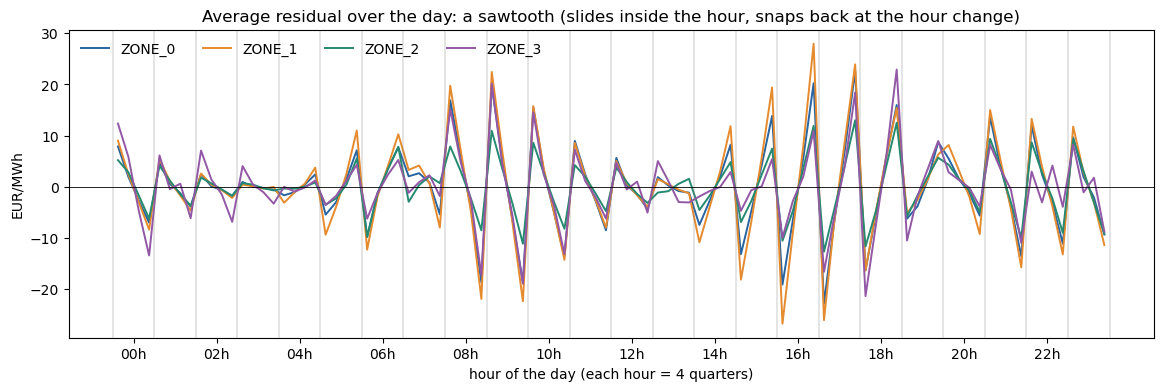

Mean |residual| (flat-guess error) by quarter position:


quarter_index,Q1,Q2,Q3,Q4
market_id,,,,
ZONE_0,11.83,4.03,4.06,11.74
ZONE_1,13.67,5.18,5.03,13.82
ZONE_2,7.56,3.59,3.41,7.80
ZONE_3,10.36,4.35,4.31,10.51


In [34]:
# ---------------------------------------------------------------------------
# 2b. The sawtooth: average residual over the 96 quarters of the day. Uses only df.
# ---------------------------------------------------------------------------
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']

st = df[['delivery_date', 'market_id', 'hour_index', 'quarter_index', 'price_eur_mwh']].copy()
st['qod'] = (st['hour_index'] - 1) * 4 + st['quarter_index']                       # 1..96
st['residual'] = st['price_eur_mwh'] - st.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].transform('mean')

profile_96 = st.groupby(['qod', 'market_id'])['residual'].mean().unstack()          # 96 × 4 zones
ax = profile_96.plot(figsize=(14, 4), color=COLORS, lw=1.4)
for h in range(0, 97, 4):
    ax.axvline(h + 0.5, color='grey', lw=0.3)                                       # hour boundaries
ax.axhline(0, color='k', lw=0.6)
ax.set_xticks([h * 4 + 2.5 for h in range(0, 24, 2)], [f'{h:02d}h' for h in range(0, 24, 2)])
ax.set(title='Average residual over the day: a sawtooth (slides inside the hour, snaps back at the hour change)',
       xlabel='hour of the day (each hour = 4 quarters)', ylabel='EUR/MWh')
ax.legend(ncol=4, frameon=False)
plt.show()

# Where does the error sit inside the hour?
print('Mean |residual| (flat-guess error) by quarter position:')
st.assign(abs_res=st['residual'].abs()).groupby(['market_id', 'quarter_index'])['abs_res'].mean().unstack().add_prefix('Q').round(2)

**Result:** every zone shows the same sawtooth: the price swings inside each hour and snaps back at every hour change, with the biggest teeth in the morning (08–10h) and the evening (15–18h), up to ±25 EUR/MWh. It's almost flat at night (01–05h) and around midday (11–14h). ZONE_1 swings the most, ZONE_2 the least, and the four zones move almost in lockstep, so one model shape with a different strength per zone should work.

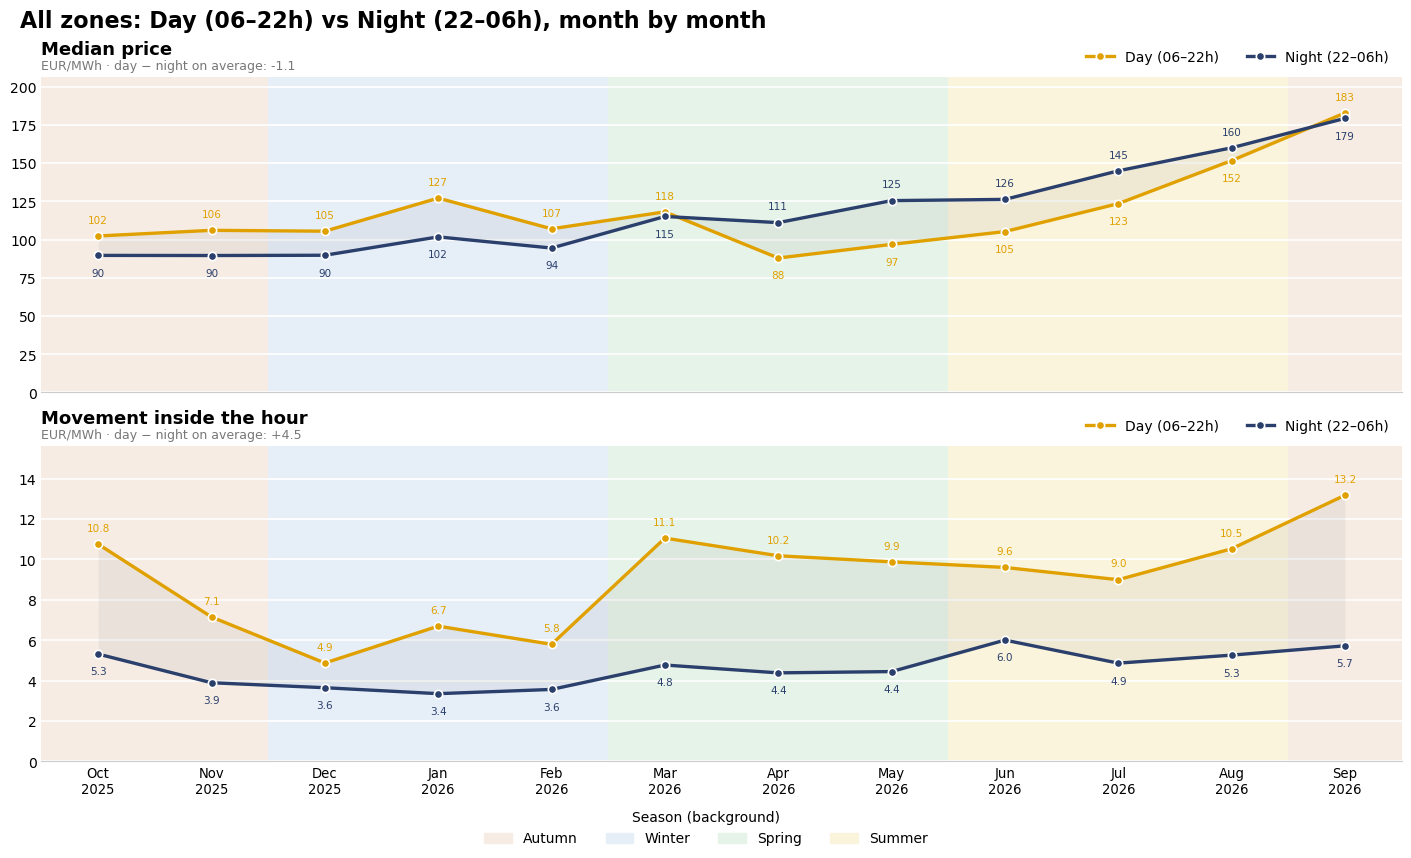

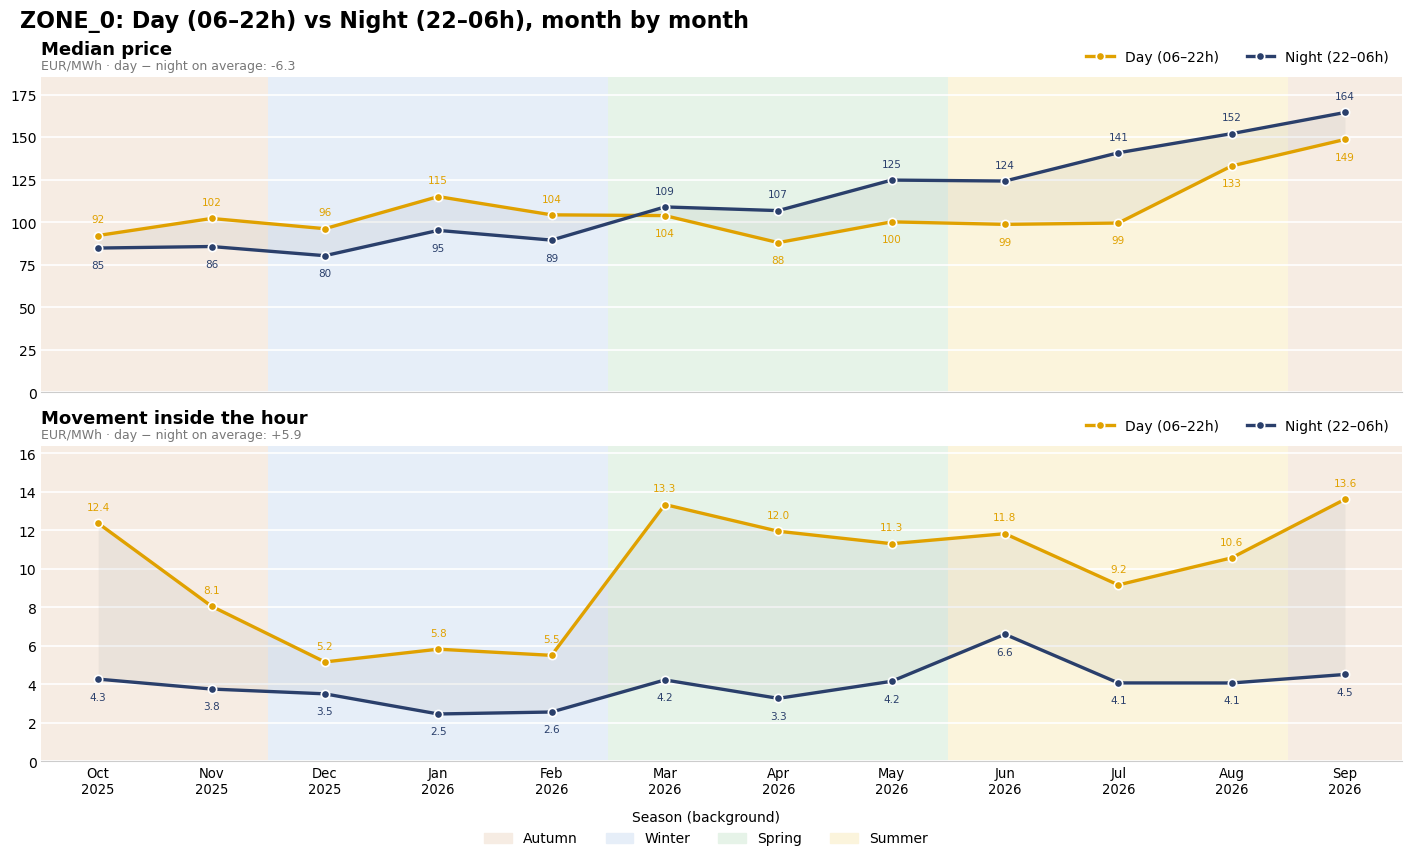

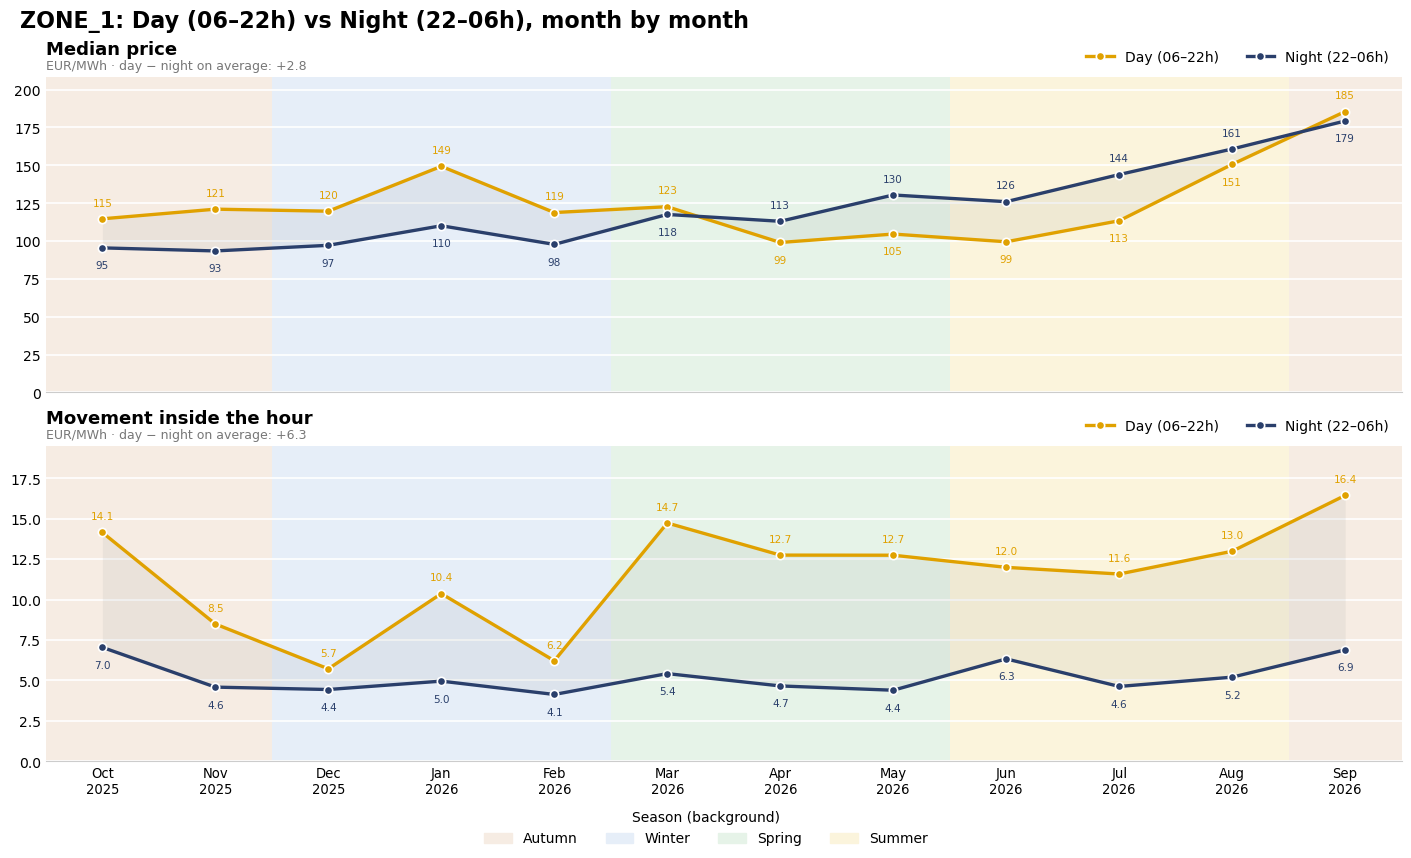

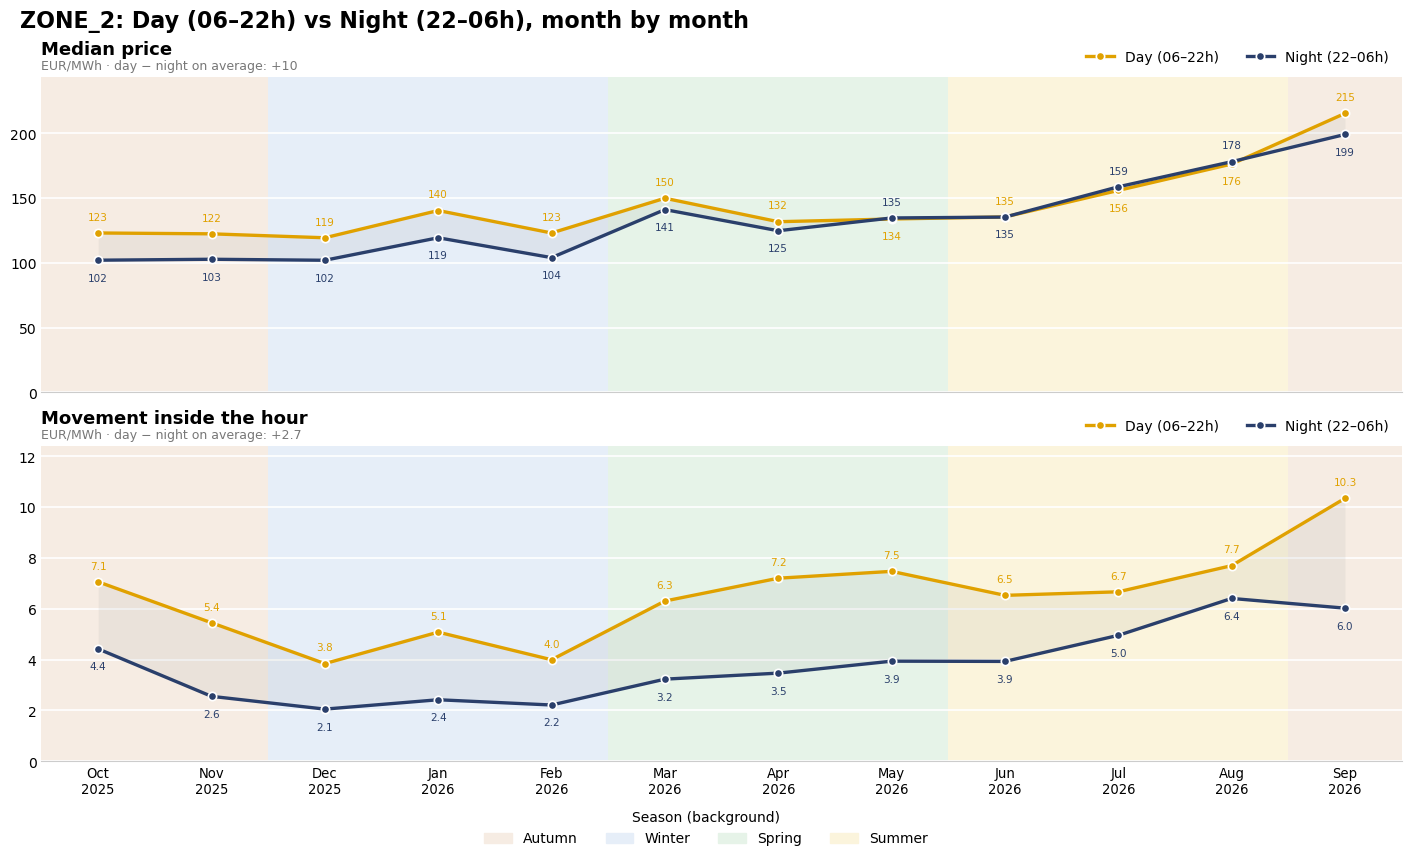

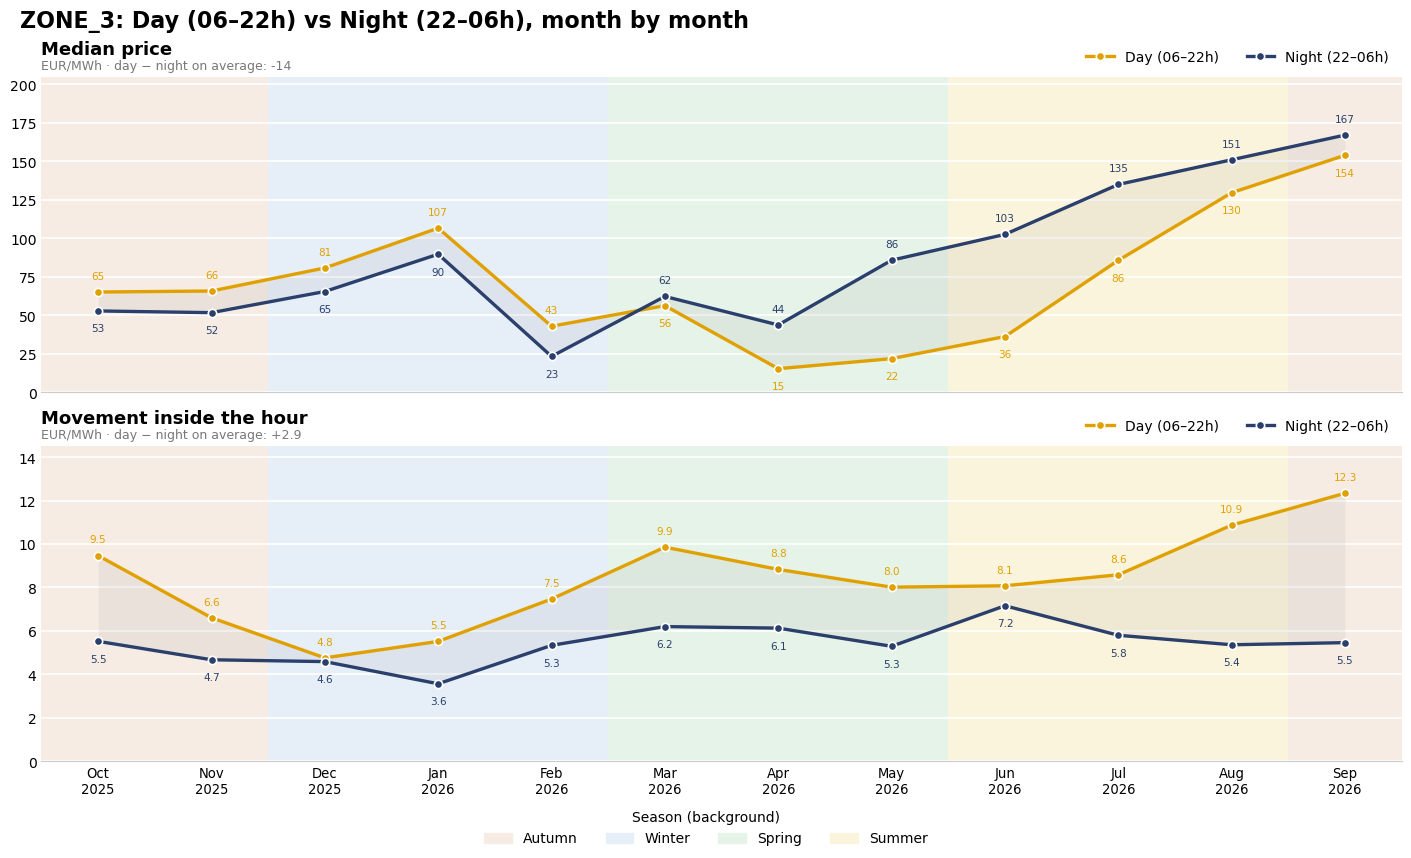

In [35]:
# ---------------------------------------------------------------------------
# Day vs night, month by month: all zones together, then zone by zone. Uses only df.
# ---------------------------------------------------------------------------
from matplotlib.patches import Patch

DAY_HOURS = range(7, 23)                     # day = 06:00–22:00 (hour_index 7–22), night = 22:00–06:00
PERIOD_COL = {'day': '#e0a100', 'night': '#2a3f6b'}
PERIOD_LABEL = {'day': 'Day (06–22h)', 'night': 'Night (22–06h)'}
SEASON_BG = {'autumn': '#f6ece3', 'winter': '#e6eef8', 'spring': '#e6f3e8', 'summer': '#fbf4dc'}
SEASON_OF = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring',
             6: 'summer', 7: 'summer', 8: 'summer', 9: 'autumn', 10: 'autumn', 11: 'autumn'}
HOURKEY = ['delivery_date', 'market_id', 'hour_index']

m = df[['delivery_date', 'market_id', 'hour_index', 'price_eur_mwh']].copy()
m['delivery_date'] = pd.to_datetime(m['delivery_date'])
m['month'] = m['delivery_date'].dt.to_period('M').astype(str)
m['period'] = np.where(m['hour_index'].isin(DAY_HOURS), 'day', 'night')
m['hourly'] = m.groupby(HOURKEY)['price_eur_mwh'].transform('mean')
m['move'] = (m['price_eur_mwh'] - m['hourly']).abs()       # distance of each 15-min price from its hourly average


def month_table(data):
    # One row per month, day and night side by side
    g = data.groupby(['month', 'period'])
    return pd.DataFrame({'price': g['price_eur_mwh'].median(),          # median: not distorted by rare spikes
                         'movement': g['move'].mean()}).unstack('period')


def plot_month(t, title):
    months = t.index.tolist()
    x = np.arange(len(months))
    panels = [('price', 'Median price', 'EUR/MWh', '{:.0f}'),
              ('movement', 'Movement inside the hour', 'EUR/MWh', '{:.1f}')]
    fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True, layout='constrained')

    for ax, (col, sub, unit, fmt) in zip(axes, panels):
        # Season bands in the background
        for i, mo in enumerate(months):
            ax.axvspan(i - 0.5, i + 0.5, color=SEASON_BG[SEASON_OF[pd.Period(mo).month]], lw=0, zorder=0)
        day, night = t[(col, 'day')].to_numpy(), t[(col, 'night')].to_numpy()
        # Shaded gap between day and night
        ax.fill_between(x, day, night, color='#9a9a9a', alpha=0.12, lw=0, zorder=1)
        for vals, other, p in [(day, night, 'day'), (night, day, 'night')]:
            ax.plot(x, vals, color=PERIOD_COL[p], lw=2.4, marker='o', ms=6, mec='white', mew=1.2,
                    label=PERIOD_LABEL[p], zorder=3)
            # Value labels: the higher line gets its label above, the lower line below, so they never collide
            for xi, v, o in zip(x, vals, other):
                above = v >= o
                ax.annotate(fmt.format(v), (xi, v), xytext=(0, 8 if above else -9), textcoords='offset points',
                            ha='center', va='bottom' if above else 'top', fontsize=7.5, color=PERIOD_COL[p])
        # Legend above the panel on the right, so it never hides a point
        ax.legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=2, frameon=False, fontsize=10)
        # Title, unit and the average gap
        gap = np.nanmean(day - night)
        ax.set_title(sub, fontsize=13, fontweight='bold', loc='left', pad=16)
        ax.text(0, 1.015, f'{unit} · day − night on average: {gap:+.{1 if abs(gap) < 10 else 0}f}',
                transform=ax.transAxes, fontsize=9, color='#777777', va='bottom')
        lo, hi = np.nanmin([day.min(), night.min()]), np.nanmax([day.max(), night.max()])
        pad = (hi - lo) * 0.25 or 1
        ax.set_ylim(0 if lo >= 0 else lo - pad, hi + pad)
        for side in ['top', 'right', 'left']:
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color('#cccccc')
        ax.grid(axis='y', color='#ffffff', lw=1.2); ax.set_axisbelow(True); ax.tick_params(length=0)

    axes[-1].set_xticks(x, [pd.Period(mo).strftime('%b\n%Y') for mo in months], fontsize=9.5)
    axes[-1].set_xlim(-0.5, len(months) - 0.5)
    seasons = [Patch(color=c, label=s.capitalize()) for s, c in SEASON_BG.items()]
    fig.legend(handles=seasons, loc='outside lower center', ncol=4, frameon=False, fontsize=10,
               title='Season (background)')
    fig.suptitle(title, fontsize=16, fontweight='bold', x=0.01, ha='left')
    plt.show()


# ---- ALL ZONES TOGETHER, then ZONE BY ZONE ----------------------------------
groups = [('All zones', m)] + [(z, m[m['market_id'] == z]) for z in sorted(m['market_id'].unique())]
for name, data in groups:
    plot_month(month_table(data), f'{name}: Day (06–22h) vs Night (22–06h), month by month')

---
# 3. The slope between hours explains most of the shape

`slope = next hour − previous hour` measures the direction and steepness of the daily ramp around an hour. `Q4 − Q1` measures the tilt inside the hour. If the two line up, the hourly curve alone predicts most of the shape. (Hours 1 and 24 have only a one-sided slope; chapter 4 looks at them.)

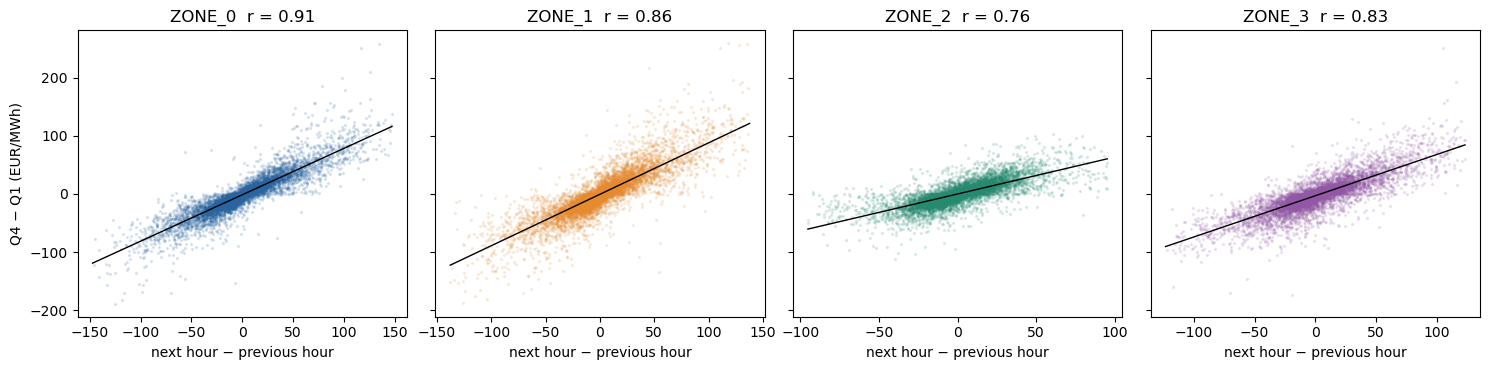

,corr,corr_spearman,fit_slope
market_id,,,
ZONE_0,0.91,0.93,0.80
ZONE_1,0.86,0.89,0.89
ZONE_2,0.76,0.80,0.64
ZONE_3,0.83,0.83,0.71


In [36]:
# ---------------------------------------------------------------------------
# 3a. Slope vs tilt inside the hour, per zone. Uses only df.
# ---------------------------------------------------------------------------
ZONES = sorted(df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']

# One row per hour: the 4 quarters side by side, plus the hourly price
S = (df.pivot_table(index=['delivery_date', 'market_id', 'hour_index'], columns='quarter_index',
                    values='price_eur_mwh')
       .reset_index()
       .sort_values(['market_id', 'delivery_date', 'hour_index']))
S['hourly'] = S[[1, 2, 3, 4]].mean(axis=1)
g = S.groupby(['market_id', 'delivery_date'])['hourly']
S['slope'] = g.shift(-1) - g.shift(1)            # next hour − previous hour (same day only)
S['q4_minus_q1'] = S[4] - S[1]                   # tilt inside the hour
S = S.dropna(subset=['slope', 'q4_minus_q1'])    # hours 2–23 (two-sided slope)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
slope_rows = []
for ax, z, c in zip(axes, ZONES, COLORS):
    p = S[S['market_id'] == z]
    lim = p['slope'].abs().quantile(0.99)        # hide the 1% largest slopes in the plot only
    pc = p[p['slope'].abs() <= lim]
    ax.scatter(pc['slope'], pc['q4_minus_q1'], s=2, alpha=0.12, color=c)
    b = np.polyfit(p['slope'], p['q4_minus_q1'], 1)     # least-squares line on all points
    xs = np.linspace(-lim, lim, 2)
    ax.plot(xs, np.polyval(b, xs), color='k', lw=1)
    r = p['slope'].corr(p['q4_minus_q1'])
    slope_rows.append({'market_id': z, 'corr': r,
                       'corr_spearman': p['slope'].corr(p['q4_minus_q1'], method='spearman'),
                       'fit_slope': b[0]})
    ax.set(title=f'{z}  r = {r:.2f}', xlabel='next hour − previous hour')
axes[0].set_ylabel('Q4 − Q1 (EUR/MWh)')
plt.tight_layout(); plt.show()
pd.DataFrame(slope_rows).set_index('market_id').round(2)

**The first win: a rule with no training.** Tilt the four quarters along the slope:

`residual_q = k × slope_c × offset_q`, with offsets (−0.375, −0.125, +0.125, +0.375)

`slope_c` is half the two-sided slope (one-sided at the day edges). The offsets sum to zero, so the hourly average is preserved automatically. `k = 1` is a straight line between hour centres; larger `k` lets the price move more inside the hour. This is **descriptive only**: k is chosen on the same data, so it is not a validation score.

In [37]:
# ---------------------------------------------------------------------------
# 3b. MAE of the slope rule for several scale factors k. Uses only df.
# ---------------------------------------------------------------------------
OFFSETS = np.array([-0.375, -0.125, 0.125, 0.375])     # quarter centres relative to the hour centre (in hours)
K_GRID = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]

# One row per hour: the 4 quarters side by side
Hk = (df.pivot_table(index=['delivery_date', 'market_id', 'hour_index'], columns='quarter_index',
                     values='price_eur_mwh')
        .reset_index()
        .sort_values(['market_id', 'delivery_date', 'hour_index'])
        .reset_index(drop=True))
Hk['hourly'] = Hk[[1, 2, 3, 4]].mean(axis=1)
R = Hk[[1, 2, 3, 4]].to_numpy() - Hk[['hourly']].to_numpy()          # residuals, one row per hour

# Hourly slope in EUR per hour: (next − previous) / 2; one-sided at the first/last hour of the day
g = Hk.groupby(['market_id', 'delivery_date'])['hourly']
prev, nxt = g.shift(1), g.shift(-1)
Hk['slope_c'] = np.where(prev.notna() & nxt.notna(), (nxt - prev) / 2,
                         np.where(nxt.notna(), nxt - Hk['hourly'], Hk['hourly'] - prev))
slope_c = Hk['slope_c'].to_numpy()[:, None]


def official_mae(frame, col):
    # Challenge score: MAE per day and zone → average per zone
    return frame.groupby(['market_id', 'delivery_date'])[col].mean().groupby('market_id').mean()


flat_mae = official_mae(Hk.assign(e=np.abs(R).mean(axis=1)), 'e')   # flat guess = all quarters = hourly price
FLAT_SCORE = flat_mae.mean()

k_tab = {'flat': flat_mae}
for k in K_GRID:
    err = np.abs(R - k * slope_c * OFFSETS).mean(axis=1)            # error of each hour
    k_tab[f'slope × {k:g}'] = official_mae(Hk.assign(e=err), 'e')
k_tab = pd.DataFrame(k_tab)
k_tab.loc['MEAN'] = k_tab.mean()                                     # equal weight per zone

SLOPE1_SCORE, SLOPE2_SCORE = k_tab.loc['MEAN', 'slope × 1'], k_tab.loc['MEAN', 'slope × 2']
print(f'Flat {FLAT_SCORE:.2f}  →  slope × 1 {SLOPE1_SCORE:.2f} ({SLOPE1_SCORE / FLAT_SCORE - 1:+.0%})'
      f'  →  slope × 2 {SLOPE2_SCORE:.2f} ({SLOPE2_SCORE / FLAT_SCORE - 1:+.0%})')
best_k = k_tab.drop(index='MEAN').drop(columns='flat').idxmin(axis=1)
print('Best k per zone:', best_k.to_dict())
k_tab.round(2)

Flat 7.58  →  slope × 1 5.46 (-28%)  →  slope × 2 4.57 (-40%)
Best k per zone: {'ZONE_0': 'slope × 2', 'ZONE_1': 'slope × 2.5', 'ZONE_2': 'slope × 2', 'ZONE_3': 'slope × 2'}


,flat,slope × 1,slope × 1.5,slope × 2,slope × 2.5,slope × 3,slope × 3.5,slope × 4
market_id,,,,,,,,
ZONE_0,7.91,5.17,4.24,3.85,4.12,4.90,6.01,7.32
ZONE_1,9.43,6.91,6.01,5.48,5.44,5.84,6.58,7.56
ZONE_2,5.59,4.28,3.98,3.98,4.25,4.74,5.39,6.16
ZONE_3,7.38,5.49,5.01,4.98,5.39,6.13,7.10,8.20
MEAN,7.58,5.46,4.81,4.57,4.80,5.40,6.27,7.31


> **What we found**
>
> - **The hourly slope predicts the tilt inside the hour.** The correlation is high in every zone (r ≈ 0.91 / 0.86 / 0.76 / 0.82 for ZONE_0–ZONE_3), and the rank correlation is just as high, so it isn't driven by a few spikes. ZONE_2 is the weakest.
> - **A simple rule with no training cuts the error by about 40%:** flat **7.30** → slope × 1 **5.32** (−27%) → slope × 2 **4.45** (−39%).
> - **The price tilts about twice as much inside the hour as a straight line between hours would suggest.** Most of the step from one hour to the next already happens *inside* the hour, which is why k ≈ 2 beats k = 1.
> - **The best k differs by zone** (see "Best k per zone" above), so k should be set per zone, using the training data only.

**→ The slope explains most of the shape. What's left?**

---
# 4. Where the simple rule breaks

The plot below shows the error that is **left** after the slope rule (k = 2), hour by hour, against the flat guess. The gaps between the two lines are the hours the rule already fixes; whatever remains is what the next steps must explain. Five complications follow, each kept short.

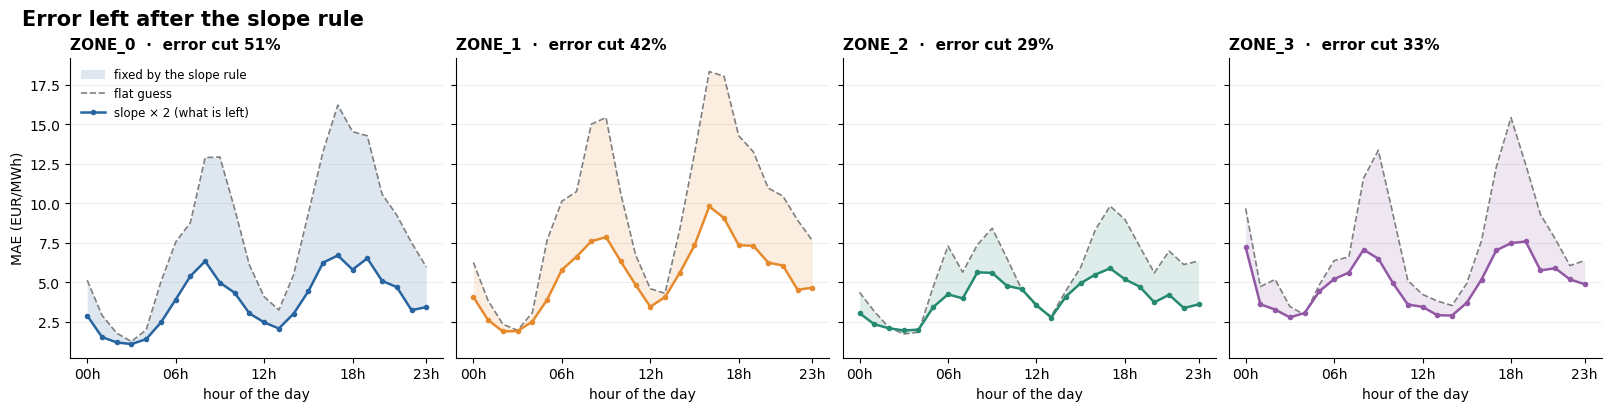

In [38]:
# ---------------------------------------------------------------------------
# 4. What's left after the slope rule (k = 2), by hour and zone. Uses Hk / R / slope_c from 3b.
# ---------------------------------------------------------------------------
ZONES = sorted(df['market_id'].unique())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']

Hk['err_flat'] = np.abs(R).mean(axis=1)                                   # flat guess error per hour
Hk['err_slope2'] = np.abs(R - 2 * slope_c * OFFSETS).mean(axis=1)         # slope rule (k = 2) error per hour
left = Hk.groupby(['market_id', 'hour_index'])[['err_flat', 'err_slope2']].mean()

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True, layout='constrained')
for ax, z, c in zip(axes, ZONES, COLORS):
    l = left.loc[z]
    x = l.index - 1                                                        # 0..23
    ax.fill_between(x, l['err_slope2'], l['err_flat'], color=c, alpha=0.15, lw=0, label='fixed by the slope rule')
    ax.plot(x, l['err_flat'], color='grey', ls='--', lw=1.2, label='flat guess')
    ax.plot(x, l['err_slope2'], color=c, marker='.', lw=1.8, label='slope × 2 (what is left)')
    cut = 1 - l['err_slope2'].mean() / l['err_flat'].mean()
    ax.set_title(f'{z}  ·  error cut {cut:.0%}', fontsize=11, fontweight='bold', loc='left')
    ax.set_xticks([0, 6, 12, 18, 23], ['00h', '06h', '12h', '18h', '23h'])
    ax.set_xlabel('hour of the day')
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#eeeeee'); ax.set_axisbelow(True)
axes[0].set_ylabel('MAE (EUR/MWh)')
axes[0].legend(frameon=False, fontsize=8.5)
fig.suptitle('Error left after the slope rule', fontsize=15, fontweight='bold', x=0.01, ha='left')
plt.show()

## Day vs Night

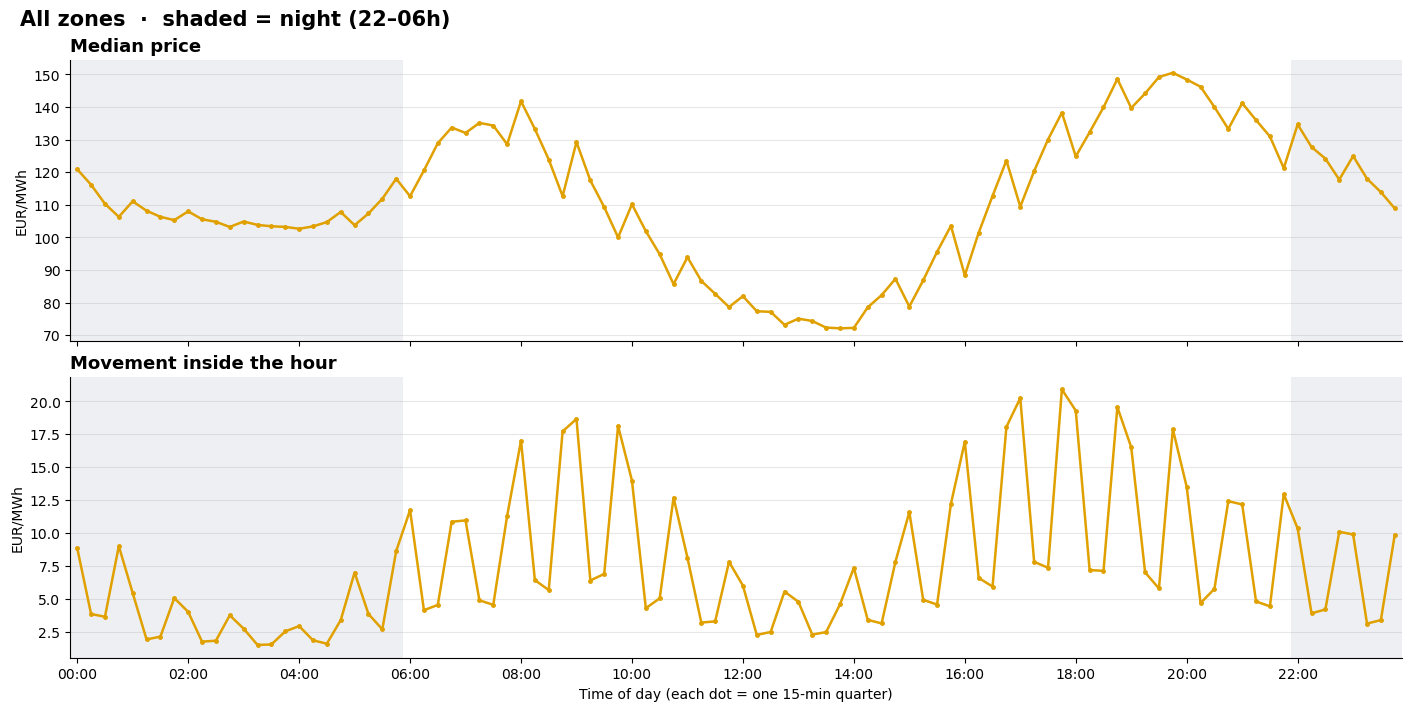

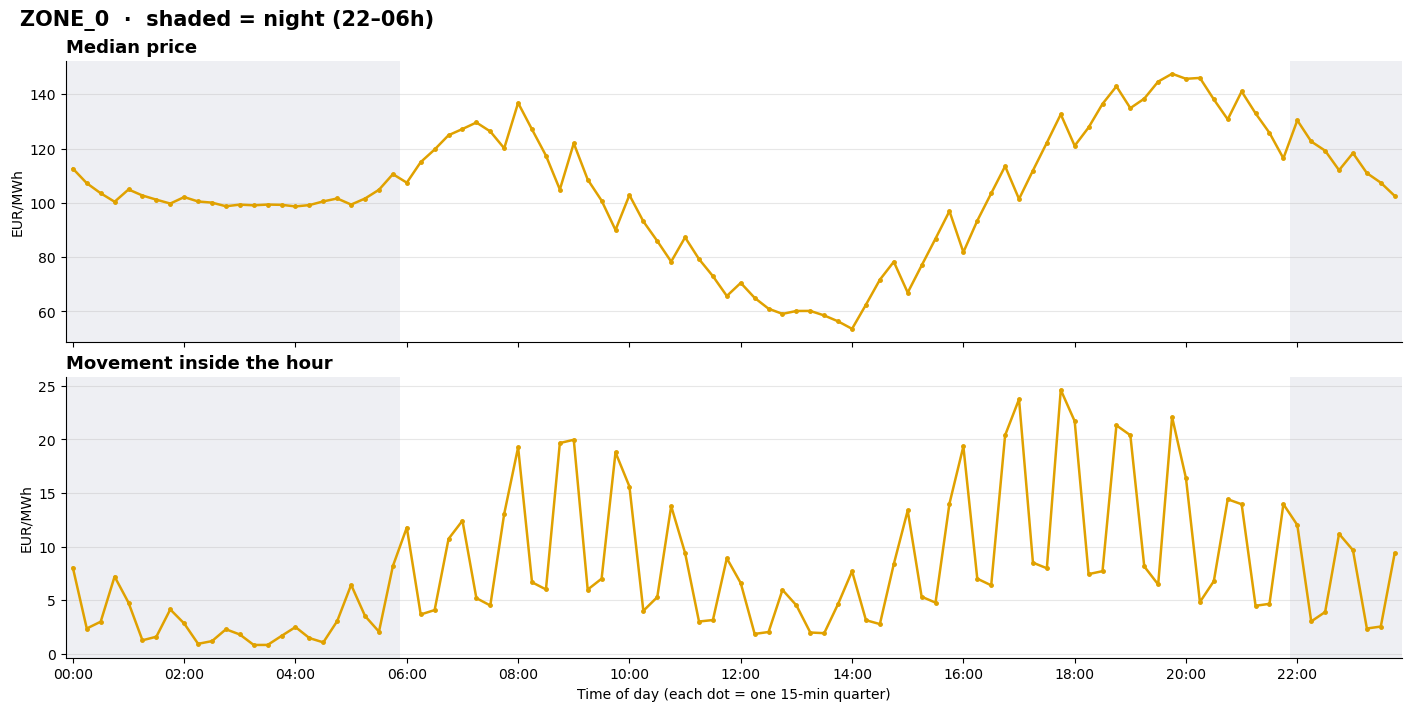

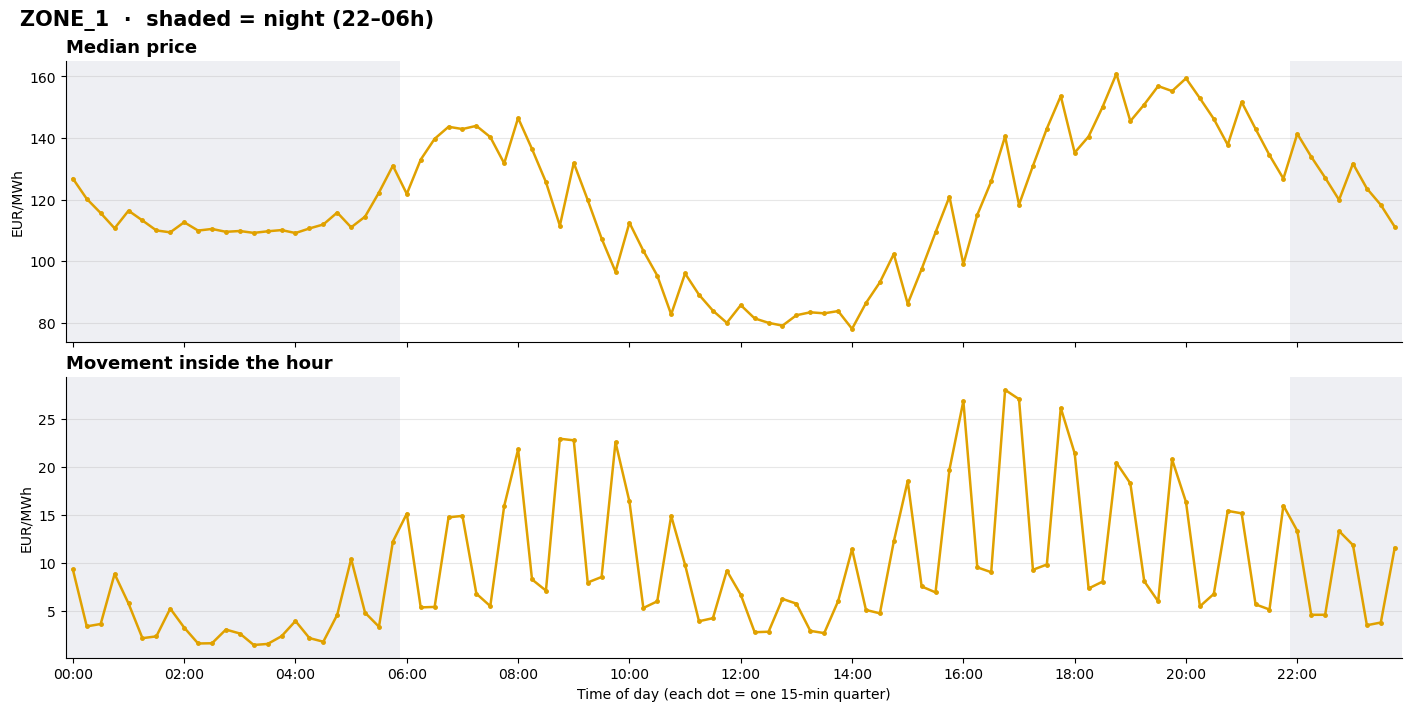

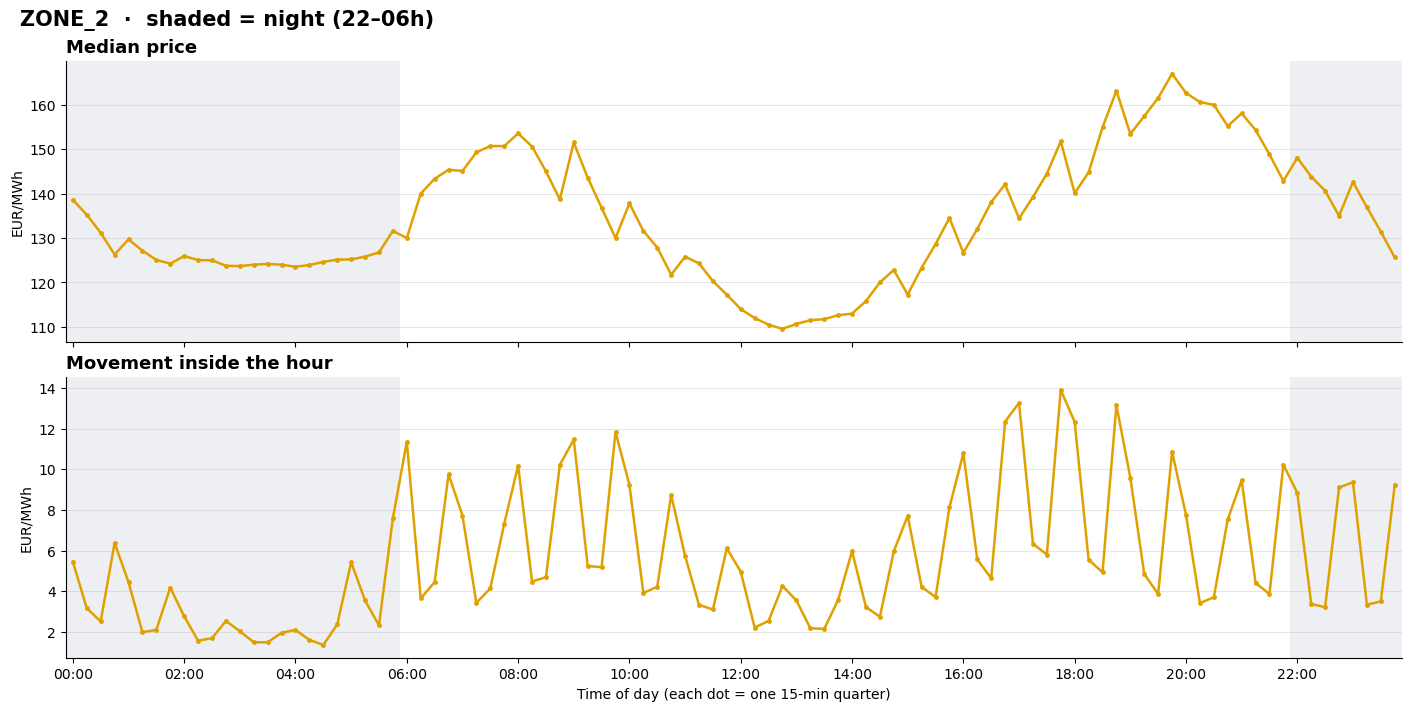

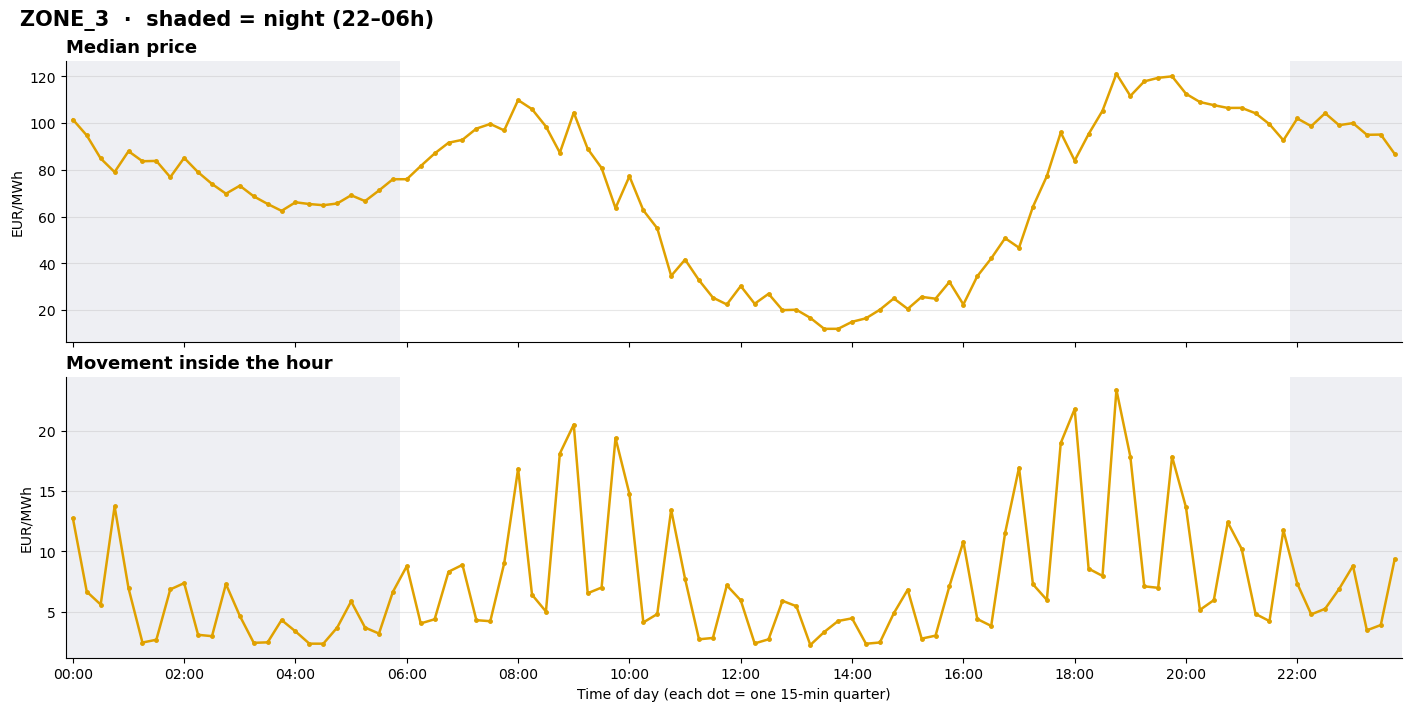

In [39]:
# ---------------------------------------------------------------------------
# Day vs night by quarter-hour (96 slots of the day). All zones, then each zone. Uses only df.
# ---------------------------------------------------------------------------
q = df[['delivery_date', 'market_id', 'hour_index', 'quarter_index', 'price_eur_mwh']].copy()
q['slot'] = (q['hour_index'] - 1) * 4 + (q['quarter_index'] - 1)        # 0..95  (0 = 00:00, 95 = 23:45)
q['move'] = (q['price_eur_mwh']
             - q.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].transform('mean')).abs()

def plot_quarters(data, title):
    t = data.groupby('slot').agg(price=('price_eur_mwh', 'median'), move=('move', 'mean'))
    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, layout='constrained')
    for ax, col, sub in zip(axes, ['price', 'move'], ['Median price', 'Movement inside the hour']):
        ax.axvspan(-0.5, 23.5, color='#2a3f6b', alpha=0.08, lw=0)            # night 00–06
        ax.axvspan(87.5, 95.5, color='#2a3f6b', alpha=0.08, lw=0)            # night 22–24
        ax.plot(t.index, t[col], color='#e0a100', lw=1.8, marker='o', ms=2.5)
        ax.set_title(sub, fontsize=13, fontweight='bold', loc='left')
        ax.set_ylabel('EUR/MWh')
        for s in ['top', 'right']:
            ax.spines[s].set_visible(False)
        ax.grid(axis='y', alpha=0.3)
    axes[-1].set_xticks(range(0, 96, 8), [f'{h:02d}:00' for h in range(0, 24, 2)])
    axes[-1].set_xlim(-0.5, 95.5)
    axes[-1].set_xlabel('Time of day (each dot = one 15-min quarter)')
    fig.suptitle(f'{title}  ·  shaded = night (22–06h)', fontsize=15, fontweight='bold', x=0.01, ha='left')
    plt.show()

plot_quarters(q, 'All zones')
for z in sorted(q['market_id'].unique()):
    plot_quarters(q[q['market_id'] == z], z)